In [1]:
# Cell 1 - Import và nạp dữ liệu
!pip install -q duckdb xgboost statsmodels

import numpy as np
import pandas as pd
import re
import duckdb
import time
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
import os

In [2]:
!git clone https://github.com/nguyenngocdangkhoa16122007-collab/airbnb-price-prediction.git

Cloning into 'airbnb-price-prediction'...
remote: Enumerating objects: 54, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 54 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (54/54), 5.58 MiB | 7.24 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [3]:
!ls -R /content/airbnb-price-prediction

/content/airbnb-price-prediction:
checkpoints  data	outputs    reproduce.py
configs      notebooks	README.md  requirements.txt

/content/airbnb-price-prediction/checkpoints:

/content/airbnb-price-prediction/configs:

/content/airbnb-price-prediction/data:
processed  raw

/content/airbnb-price-prediction/data/processed:

/content/airbnb-price-prediction/data/raw:
AB_NYC_2019.csv

/content/airbnb-price-prediction/notebooks:
Full_notebook.ipynb

/content/airbnb-price-prediction/outputs:
figures  metrics  tables

/content/airbnb-price-prediction/outputs/figures:

/content/airbnb-price-prediction/outputs/metrics:

/content/airbnb-price-prediction/outputs/tables:


In [4]:
PROJECT_ROOT = "/content/airbnb-price-prediction"

DATA_PATH = os.path.join(
    PROJECT_ROOT, "data", "raw", "AB_NYC_2019.csv"
)

OUTPUT_PATH = os.path.join(
    PROJECT_ROOT, "outputs"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

SEED = 42
np.random.seed(SEED)
df = pd.read_csv(DATA_PATH)

df.shape, df.columns.tolist()

((48895, 16),
 ['id',
  'name',
  'host_id',
  'host_name',
  'neighbourhood_group',
  'neighbourhood',
  'latitude',
  'longitude',
  'room_type',
  'price',
  'minimum_nights',
  'number_of_reviews',
  'last_review',
  'reviews_per_month',
  'calculated_host_listings_count',
  'availability_365'])

In [5]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [7]:
so_dong, so_cot = df.shape
print(f'Tổng số dòng: {so_dong}')
print(f'Tổng số cột: {so_cot}')

# Xem nhanh kiểu dữ liệu tổng quát
df.info()

Tổng số dòng: 48895
Tổng số cột: 16
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 

In [ ]:
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [ ]:
# Cell 1 - Import, thiết lập và chuẩn bị dữ liệu trực quan hóa
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Bỏ price = 0; các cột cần thiết cho trực quan hóa
df_viz = df.loc[df["price"].notna() & (df["price"] > 0)].copy()

# ===== Giới hạn tại Phân vị 99 thay cho IQR =====
# Giới hạn price tại P99 để loại bỏ ~1% giá trị cực cao
price_p99 = df_viz["price"].quantile(0.99)
df_viz["price_capped"] = df_viz["price"].clip(upper=price_p99)
df_viz["log_price"] = np.log1p(df_viz["price_capped"])

# Giới hạn minimum_nights tại P99
min_nights_p99 = df_viz["minimum_nights"].quantile(0.99)
df_viz["minimum_nights_capped"] = df_viz["minimum_nights"].clip(upper=min_nights_p99)

# In thông số tóm tắt
print(f"Số dòng dùng để trực quan hóa: {len(df_viz):,}")
print(f"Ngưỡng giới hạn price (P99): ${price_p99:,.0f}")
print(f"Ngưỡng giới hạn minimum_nights (P99): {min_nights_p99:.0f} đêm")
print(f"Số price = 0 đã loại bỏ: {(df['price'] == 0).sum():,}")
print(f"Số giá trị price bị giới hạn: {(df_viz['price'] > price_p99).sum():,} (~1%)")
print(f"Số giá trị minimum_nights bị giới hạn: {(df_viz['minimum_nights'] > min_nights_p99).sum():,} (~1%)")

Số dòng dùng để trực quan hóa: 48,884
Ngưỡng giới hạn price (P99): $799
Ngưỡng giới hạn minimum_nights (P99): 45 đêm
Số price = 0 đã loại bỏ: 11
Số giá trị price bị giới hạn: 474 (~1%)
Số giá trị minimum_nights bị giới hạn: 469 (~1%)


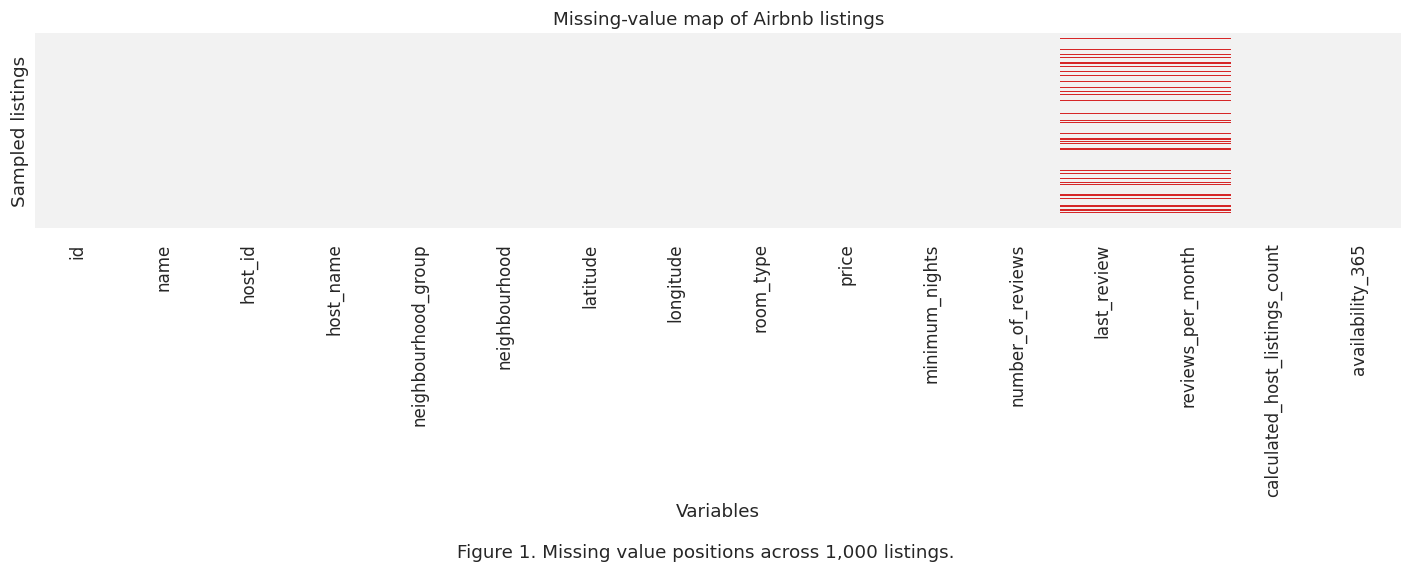

,missing_pct
last_review,20.558339
reviews_per_month,20.558339
host_name,0.042949
name,0.032723
neighbourhood_group,0.000000
neighbourhood,0.000000
id,0.000000
host_id,0.000000
longitude,0.000000
latitude,0.000000


In [ ]:
# Cell 2 - EDA: missing-value heatmap
# Lấy mẫu tối đa 1,000 dòng để biểu đồ dễ đọc; tỷ lệ missing vẫn phản ánh toàn bộ dataset.

missing_sample = df.sample(
    n=min(1000, len(df)),
    random_state=SEED
)

fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    missing_sample.isna(),
    yticklabels=False,
    cbar=False,
    cmap=["#F2F2F2", "#D62728"],
    ax=ax
)

ax.set_title("Missing-value map of Airbnb listings")
ax.set_xlabel("Variables")
ax.set_ylabel("Sampled listings")
fig.text(
    0.5, -0.03,
    f"Figure 1. Missing value positions across {len(missing_sample):,} listings.",
    ha="center"
)

plt.tight_layout()
plt.show()

# Bảng tỷ lệ missing để diễn giải biểu đồ
missing_summary = (
    df.isna().mean()
      .mul(100)
      .sort_values(ascending=False)
      .rename("missing_pct")
      .to_frame()
)

missing_summary

cho thấy dữ liệu Airbnb có chất lượng khá tốt khi phần lớn các biến không chứa giá trị thiếu. Các giá trị thiếu chỉ xuất hiện ở hai biến last_review và reviews_per_month. Điều này có thể được giải thích bởi các listing chưa nhận được đánh giá từ khách hàng, khiến ngày đánh giá gần nhất và số đánh giá trung bình mỗi tháng không thể xác định. Do đó, các giá trị thiếu này mang ý nghĩa nghiệp vụ chứ không phải lỗi thu thập dữ liệu.

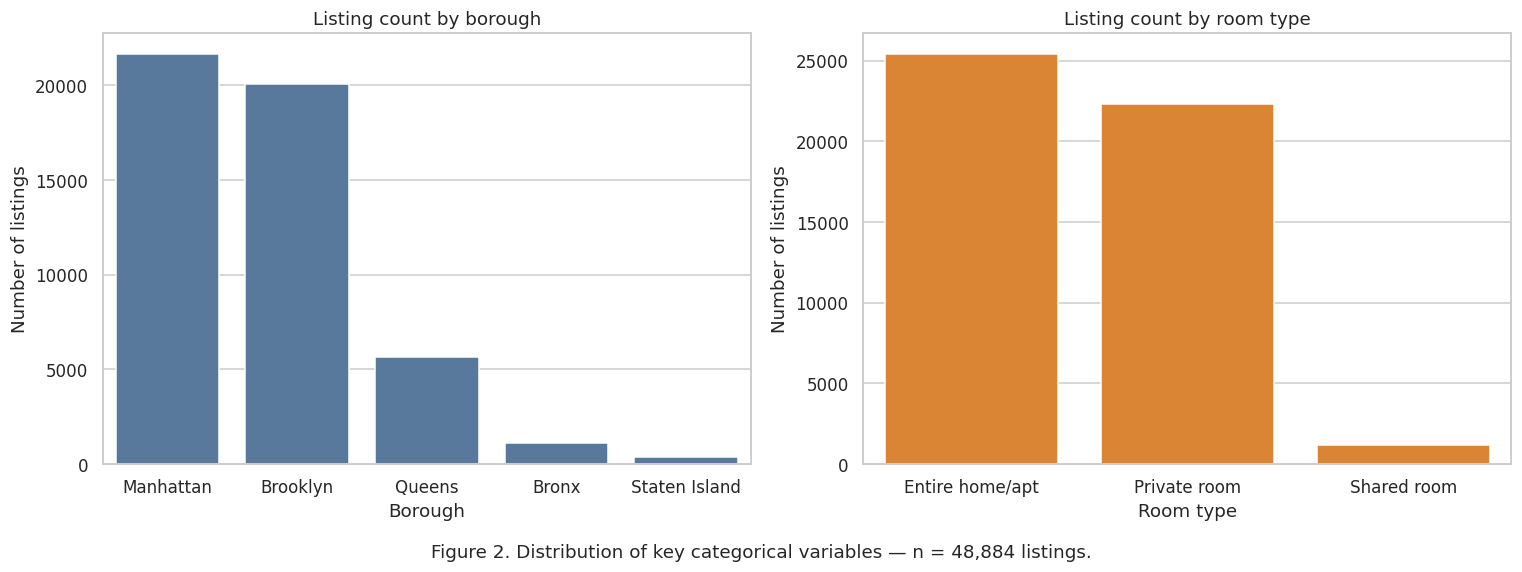

In [ ]:
# Cell 3 - EDA: Count plot cho hai biến phân loại quan trọng

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_viz,
    x="neighbourhood_group",
    order=df_viz["neighbourhood_group"].value_counts().index,
    color="#4C78A8",
    ax=axes[0]
)
axes[0].set_title("Listing count by borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Number of listings")
axes[0].tick_params(axis="x")
axes[0].set_ylim(bottom=0)

sns.countplot(
    data=df_viz,
    x="room_type",
    order=df_viz["room_type"].value_counts().index,
    color="#F58518",
    ax=axes[1]
)
axes[1].set_title("Listing count by room type")
axes[1].set_xlabel("Room type")
axes[1].set_ylabel("Number of listings")
axes[1].tick_params(axis="x")
axes[1].set_ylim(bottom=0)

fig.text(
    0.5, -0.03,
    f"Figure 2. Distribution of key categorical variables — n = {len(df_viz):,} listings.",
    ha="center"
)

plt.tight_layout()
plt.show()

cho thấy số lượng listing Airbnb phân bố không đồng đều giữa các khu vực. Manhattan và Brooklyn là hai borough có số listing áp đảo, chiếm phần lớn tổng số 48.884 listing trong bộ dữ liệu. Về loại hình lưu trú, thuê nguyên căn hộ (Entire home/apt) và phòng riêng (Private room) là hai lựa chọn phổ biến nhất, trong khi phòng ở chung (Shared room) chỉ chiếm một tỷ lệ rất nhỏ. Kết quả này phản ánh xu hướng khách hàng ưu tiên sự riêng tư khi sử dụng dịch vụ Airbnb và sự tập trung hoạt động cho thuê tại các khu vực trung tâm của thành phố.

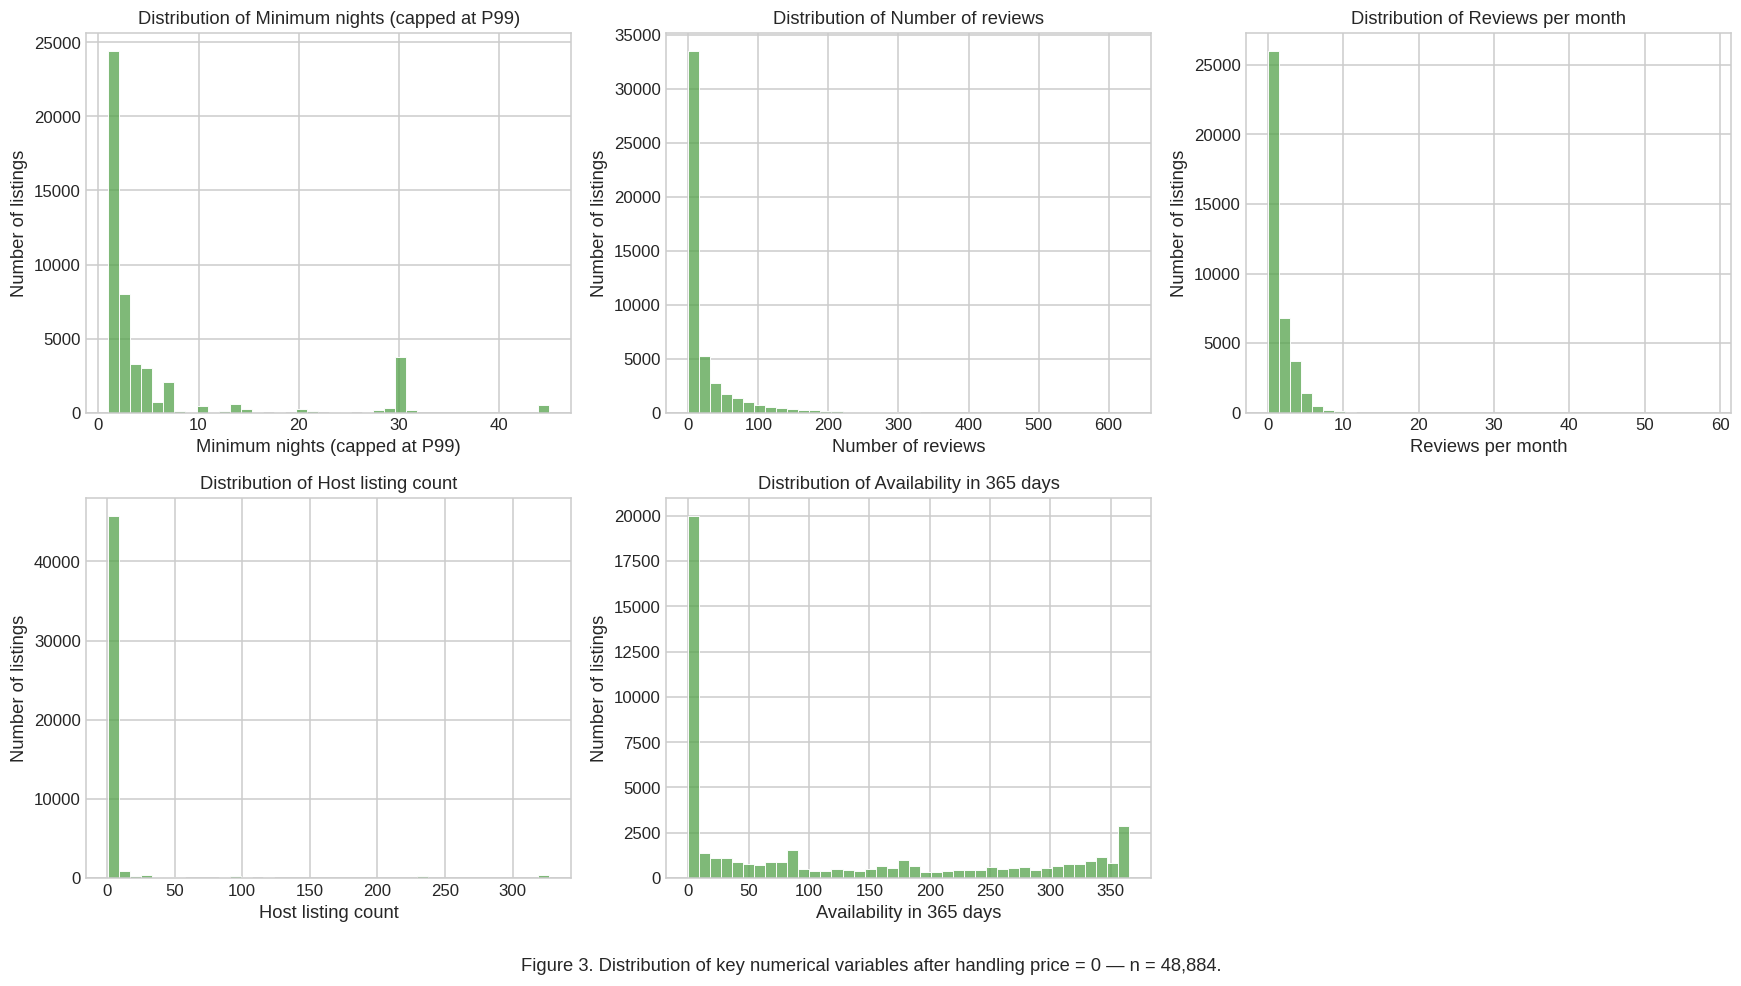

In [ ]:
# Cell 4 - EDA: Histogram các biến số quan trọng

eda_numeric_features = [
    "minimum_nights_capped",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

feature_labels = {
    "minimum_nights_capped": "Minimum nights (capped at P99)",
    "number_of_reviews": "Number of reviews",
    "reviews_per_month": "Reviews per month",
    "calculated_host_listings_count": "Host listing count",
    "availability_365": "Availability in 365 days"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, feature in zip(axes, eda_numeric_features):
    plot_data = df_viz[feature].dropna()

    sns.histplot(
        plot_data,
        bins=40,
        color="#54A24B",
        edgecolor="white",
        ax=ax
    )
    ax.set_title(f"Distribution of {feature_labels[feature]}")
    ax.set_xlabel(feature_labels[feature])
    ax.set_ylabel("Number of listings")

axes[-1].set_visible(False)

fig.text(
    0.5, 0.01,
    f"Figure 3. Distribution of key numerical variables after handling price = 0 — n = {len(df_viz):,}.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

cho thấy các biến định lượng chính của bộ dữ liệu Airbnb đều có phân phối lệch phải. Phần lớn listing có yêu cầu số đêm tối thiểu thấp, số lượng đánh giá ít và được quản lý bởi các host chỉ sở hữu một vài bất động sản. Ngoài ra, biến availability_365 cho thấy sự phân hóa rõ rệt giữa các listing có tỷ lệ lấp đầy cao và các listing còn trống trong phần lớn thời gian của năm. Điều này cho thấy dữ liệu tồn tại các giá trị ngoại lệ và không tuân theo phân phối chuẩn, cần cân nhắc sử dụng các thước đo bền vững như median hoặc thực hiện biến đổi log trong các bước phân tích tiếp theo.

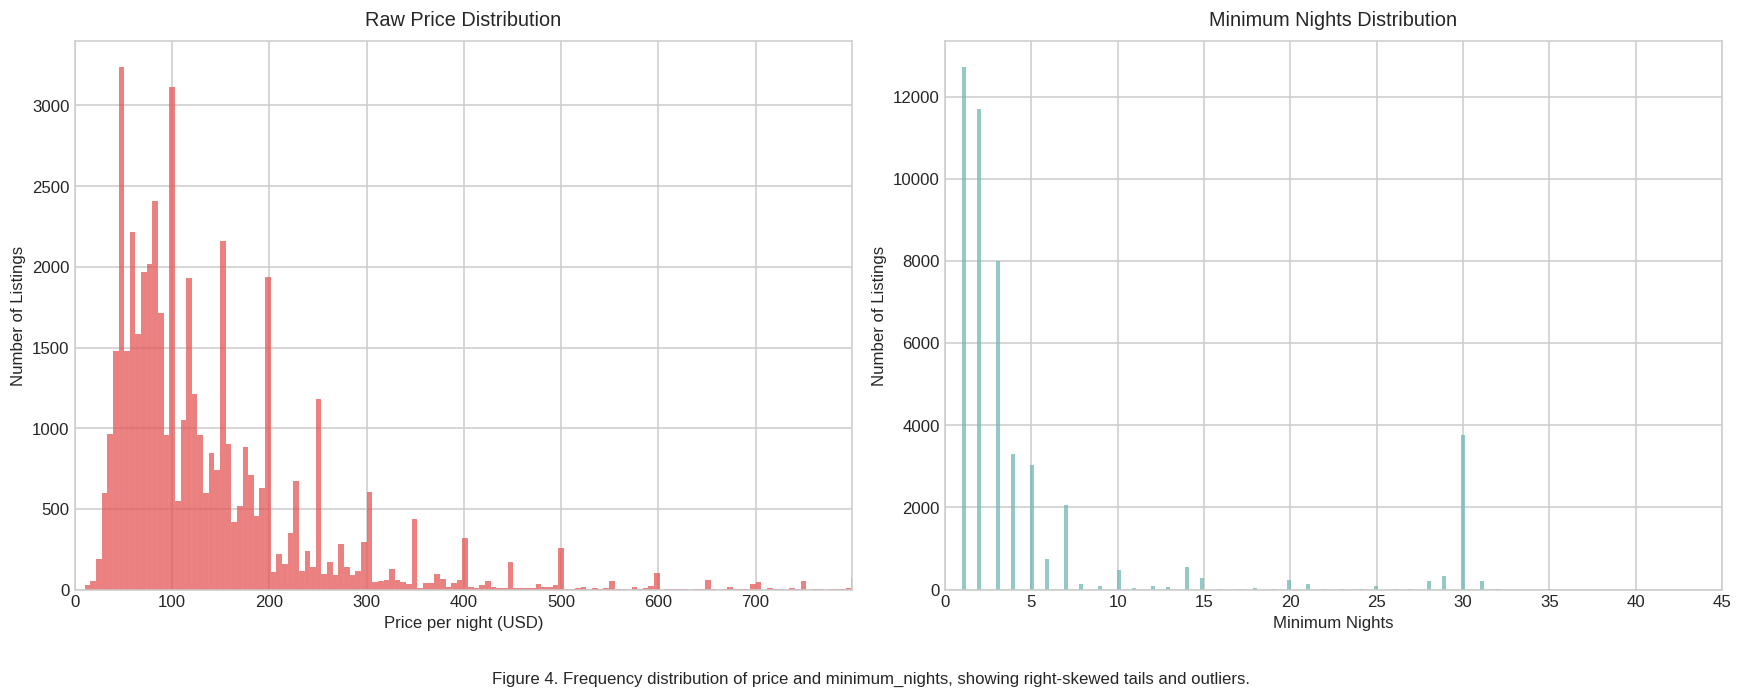

In [ ]:
# Cell 5 -  kiểm tra trực quan outlier của target và minimum_nights

plt.rcParams.update({
    'figure.dpi': 110,
    'figure.figsize': (16, 6)
})

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Price histogram
sns.histplot(
    data=df_viz,
    x="price",
    color="#E45756",
    ax=axes[0],
    kde=False,
    bins='auto'
)
axes[0].set_title("Raw Price Distribution", fontsize=13, pad=10)
axes[0].set_xlabel("Price per night (USD)", fontsize=11)
axes[0].set_ylabel("Number of Listings", fontsize=11)
axes[0].set_xlim(0, df_viz["price"].quantile(0.99))

# Minimum nights histogram
sns.histplot(
    data=df_viz,
    x="minimum_nights",
    color="#72B7B2",
    ax=axes[1],
    kde=False,
    bins='auto'
)
axes[1].set_title("Minimum Nights Distribution", fontsize=13, pad=10)
axes[1].set_xlabel("Minimum Nights", fontsize=11)
axes[1].set_ylabel("Number of Listings", fontsize=11)
axes[1].set_xlim(0, df_viz["minimum_nights"].quantile(0.99))

# Caption
fig.text(
    0.5, -0.05,
    "Figure 4. Frequency distribution of price and minimum_nights, showing right-skewed tails and outliers.",
    ha="center",
    fontsize=11
)

plt.tight_layout()
plt.show()

sử dụng histogram để kiểm tra sự hiện diện của ngoại lệ trong các biến price và minimum_nights. Kết quả cho thấy cả hai biến đều có phân phối lệch phải mạnh với số lượng lớn giá trị ngoại lệ nằm ở phía phải. Đặc biệt, một số listing có giá thuê lên tới gần 10.000 USD mỗi đêm và yêu cầu thời gian lưu trú tối thiểu vượt quá 1.000 đêm. Do đó, các thước đo bền vững như median và IQR phù hợp hơn mean và standard deviation khi mô tả các biến này. Đồng thời, các kỹ thuật như log transformation hoặc capping winsorization có thể được cân nhắc trong các bước phân tích và xây dựng mô hình tiếp theo.

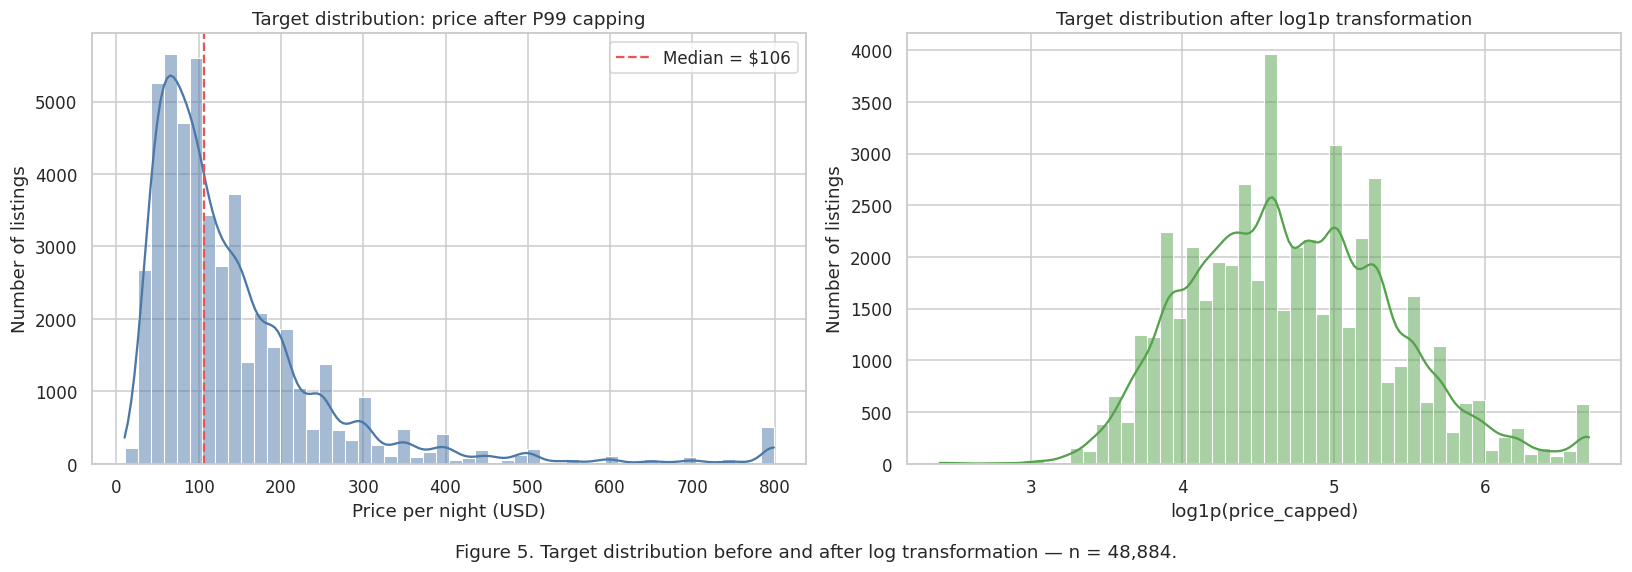

In [ ]:
# Cell 6 - Histogram / KDE của target
# Biểu đồ trái: price sau cap để đọc được phân phối điển hình.
# Biểu đồ phải: log1p(price_capped), hỗ trợ quyết định dùng log-transform cho regression.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df_viz,
    x="price_capped",
    bins=50,
    kde=True,
    color="#4C78A8",
    ax=axes[0]
)
axes[0].axvline(
    df_viz["price_capped"].median(),
    color="#E45756",
    linestyle="--",
    label=f"Median = ${df_viz['price_capped'].median():,.0f}"
)
axes[0].set_title("Target distribution: price after P99 capping")
axes[0].set_xlabel("Price per night (USD)")
axes[0].set_ylabel("Number of listings")
axes[0].legend()

sns.histplot(
    data=df_viz,
    x="log_price",
    bins=50,
    kde=True,
    color="#54A24B",
    ax=axes[1]
)
axes[1].set_title("Target distribution after log1p transformation")
axes[1].set_xlabel("log1p(price_capped)")
axes[1].set_ylabel("Number of listings")

fig.text(
    0.5, -0.03,
    f"Figure 5. Target distribution before and after log transformation — n = {len(df_viz):,}.",
    ha="center"
)

plt.tight_layout()
plt.show()

minh họa phân phối của biến mục tiêu price sau khi xử lý ngoại lệ bằng phương pháp P99 và sau khi áp dụng biến đổi log1p. Kết quả cho thấy giá thuê tập trung chủ yếu quanh mức trung vị 106 USD/đêm. Mặc dù P99 đã hạn chế tác động của các giá trị cực đoan, phân phối vẫn lệch phải. Sau phép biến đổi logarit, phân phối trở nên cân bằng và gần đối xứng hơn, góp phần giảm ảnh hưởng của ngoại lệ, ổn định phương sai và tạo điều kiện thuận lợi cho việc xây dựng các mô hình dự báo giá trong các bước tiếp theo.

/tmp/ipykernel_523/2757475392.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_523/2757475392.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


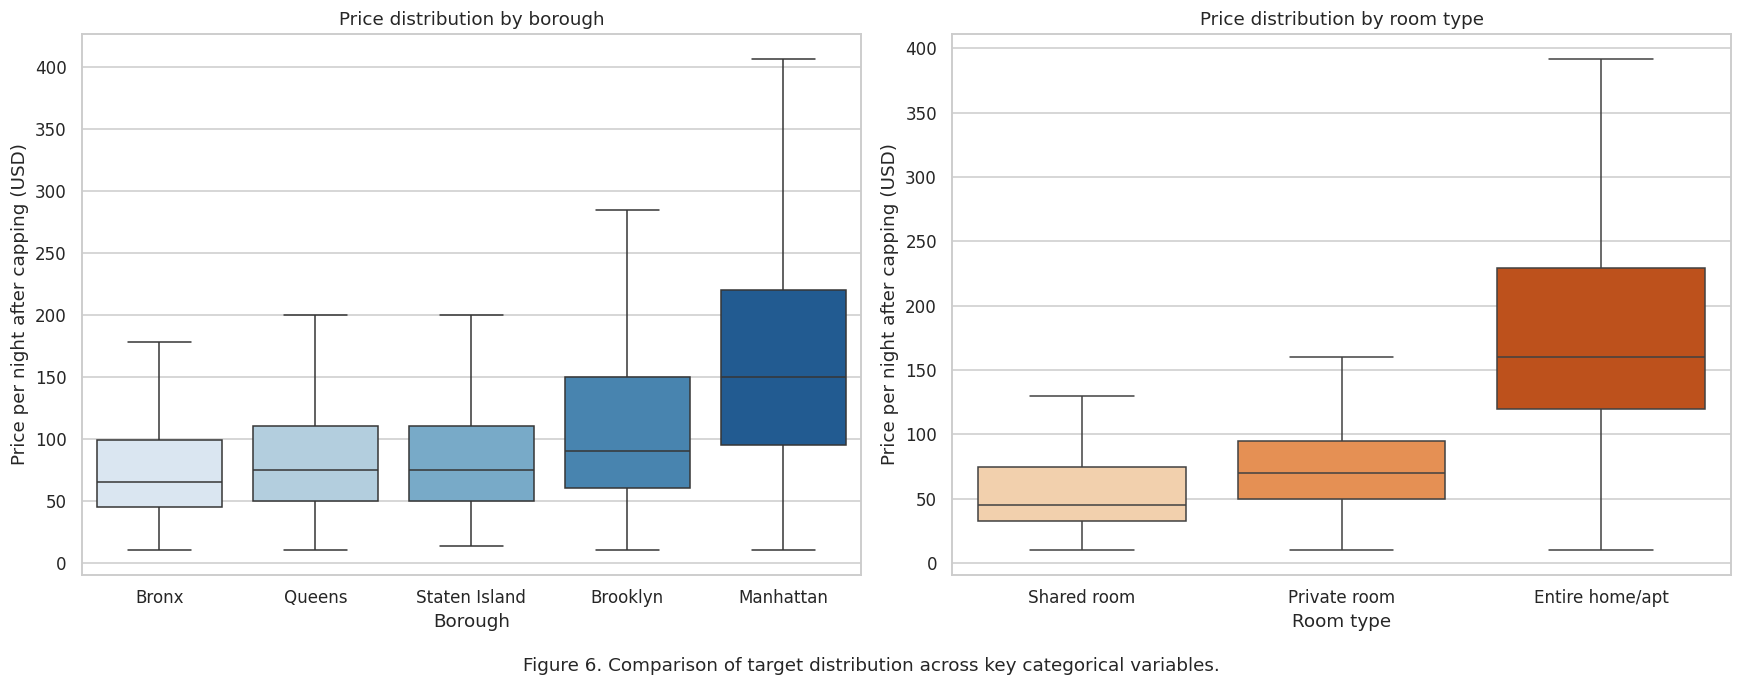

In [ ]:
# Cell 7 - Boxplot: biến phân loại vs target
# Dùng boxplot vì neighbourhood_group và room_type là categorical, không phù hợp scatter plot.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

borough_order = (
    df_viz.groupby("neighbourhood_group")["price_capped"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_viz,
    x="neighbourhood_group",
    y="price_capped",
    order=borough_order,
    showfliers=False,
    palette="Blues",
    ax=axes[0]
)
axes[0].set_title("Price distribution by borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Price per night after capping (USD)")
axes[0].tick_params(axis="x")

room_order = (
    df_viz.groupby("room_type")["price_capped"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df_viz,
    x="room_type",
    y="price_capped",
    order=room_order,
    showfliers=False,
    palette="Oranges",
    ax=axes[1]
)
axes[1].set_title("Price distribution by room type")
axes[1].set_xlabel("Room type")
axes[1].set_ylabel("Price per night after capping (USD)")
axes[1].tick_params(axis="x")

fig.text(
    0.5, -0.03,
    "Figure 6. Comparison of target distribution across key categorical variables.",
    ha="center"
)

plt.tight_layout()
plt.show()

cho thấy giá thuê Airbnb có sự khác biệt đáng kể giữa các borough và room type. Manhattan sở hữu mức giá trung vị cao nhất, tiếp theo là Brooklyn, trong khi Bronx có mức giá thấp nhất. Xét theo loại hình lưu trú, Entire home/apt có giá trung vị vượt trội so với Private room và Shared room. Kết quả này cho thấy vị trí địa lý và loại hình lưu trú là hai yếu tố quan trọng ảnh hưởng đến giá thuê, đồng thời là các biến dự báo có giá trị trong mô hình ước lượng giá Airbnb.

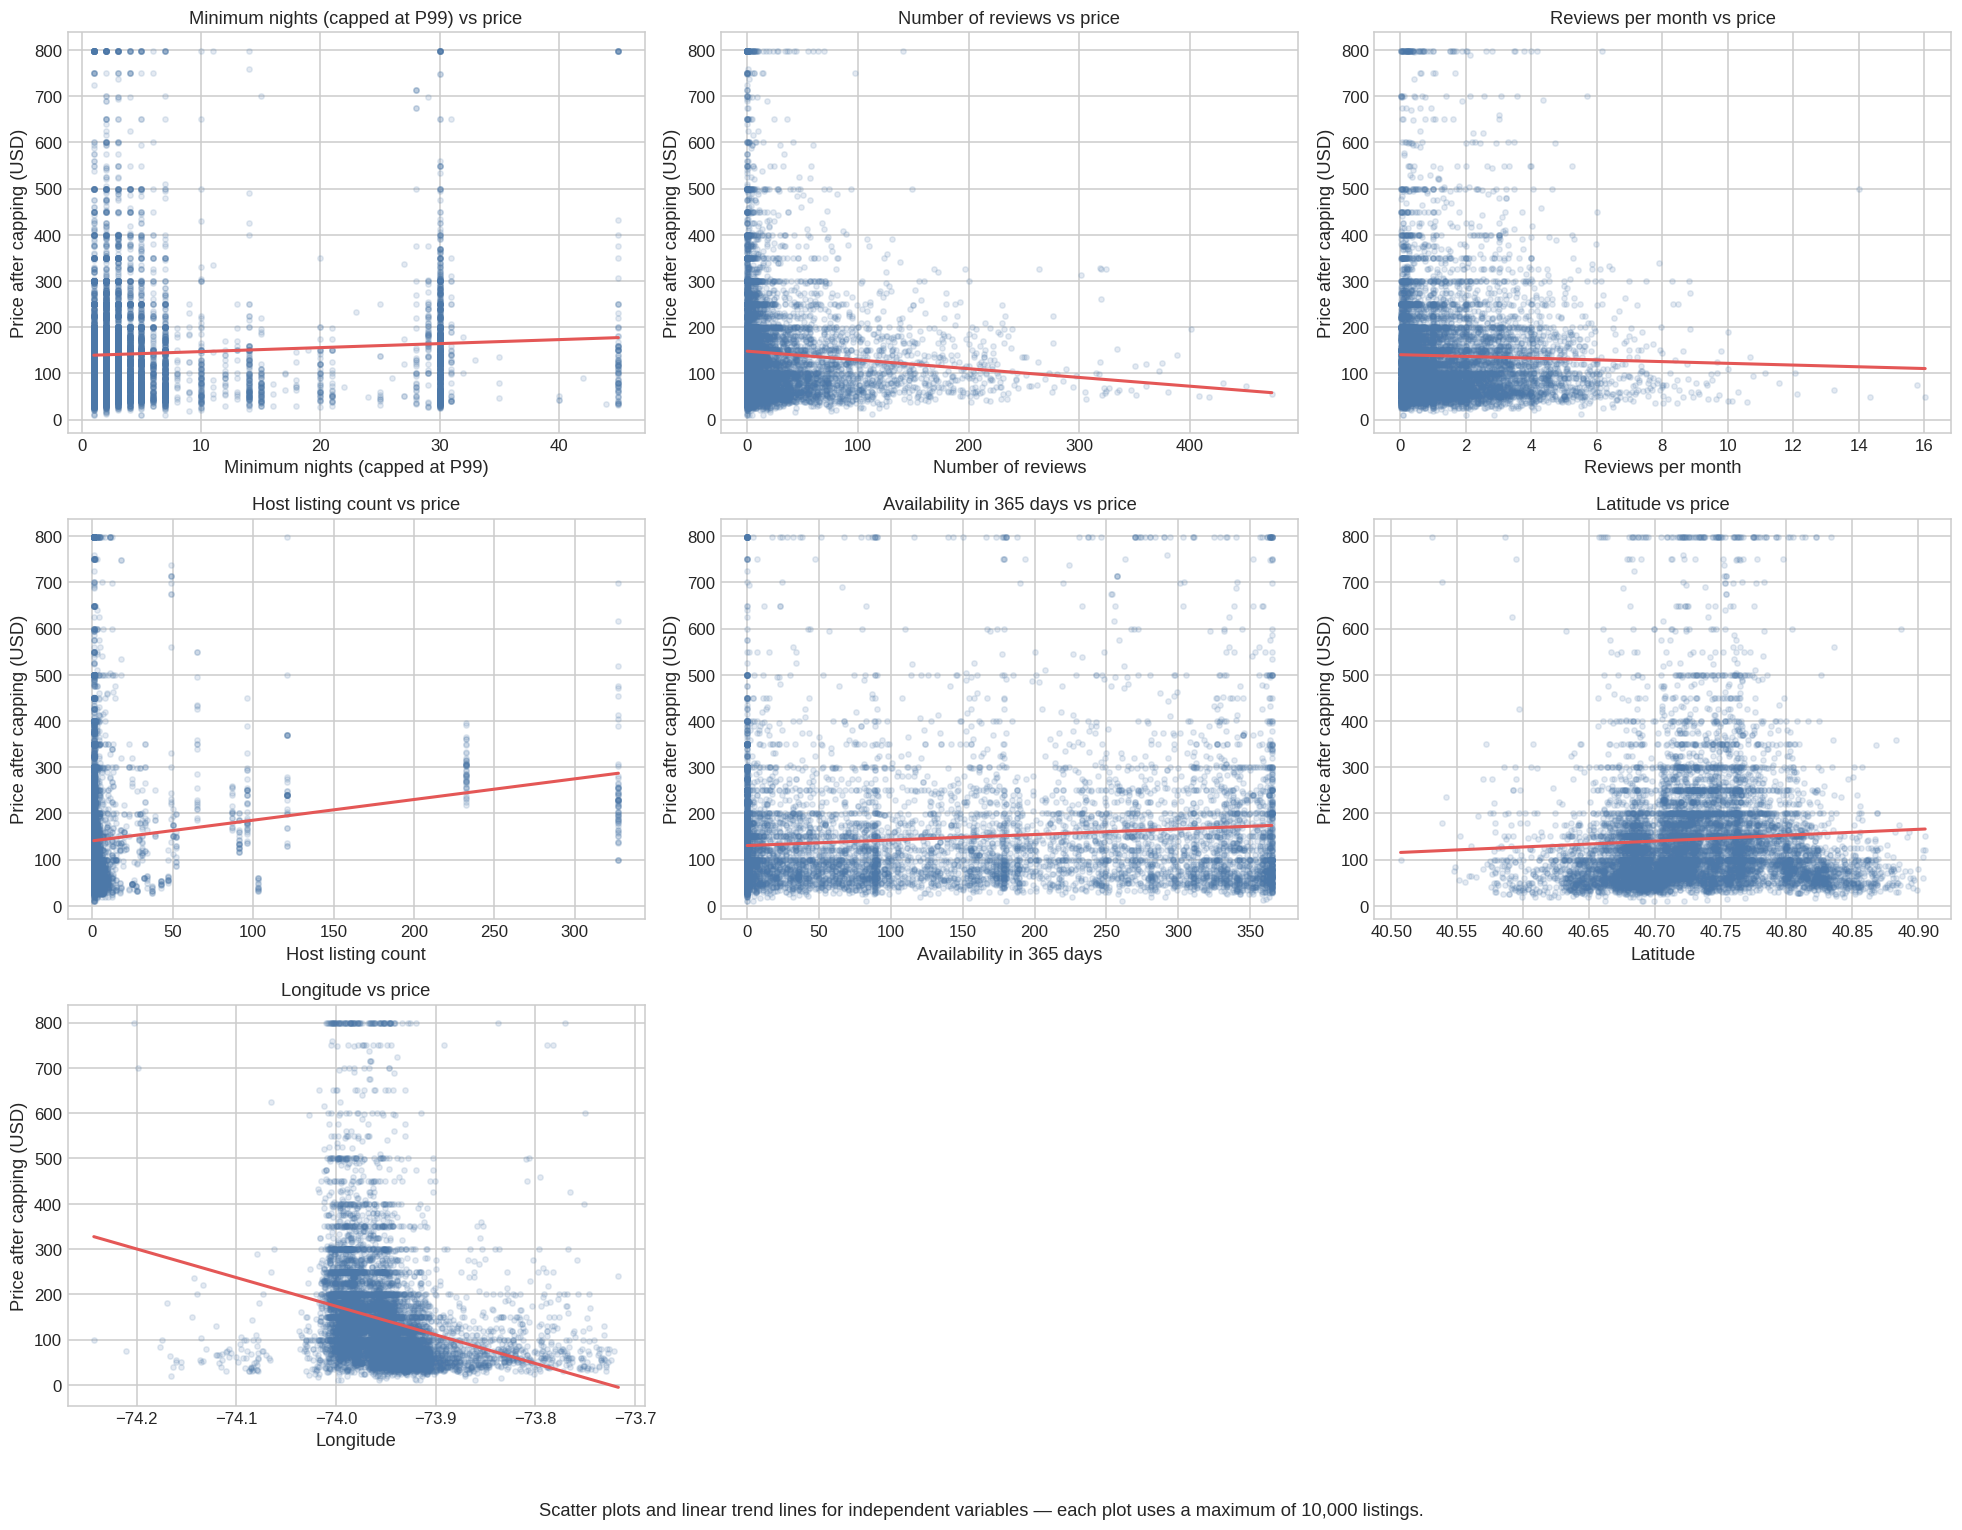

In [ ]:
# Cell 8 - Scatter plots: biến số độc lập vs target
# ID và host_id bị loại vì là định danh.
# name, host_name là text; neighbourhood/room_type là categorical nên đã dùng boxplot.
# availability_365 nên xem là exploratory feature vì có thể phản ánh hành vi đặt phòng/lịch mở.

scatter_features = [
    "minimum_nights_capped",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude"
]

scatter_labels = {
    "minimum_nights_capped": "Minimum nights (capped at P99)",
    "number_of_reviews": "Number of reviews",
    "reviews_per_month": "Reviews per month",
    "calculated_host_listings_count": "Host listing count",
    "availability_365": "Availability in 365 days",
    "latitude": "Latitude",
    "longitude": "Longitude"
}

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for ax, feature in zip(axes, scatter_features):
    scatter_data = df_viz[[feature, "price_capped"]].dropna()

    # Sample để giảm overplotting và tăng tốc độ render.
    if len(scatter_data) > 10000:
        scatter_data = scatter_data.sample(10000, random_state=SEED)

    sns.regplot(
        data=scatter_data,
        x=feature,
        y="price_capped",
        scatter_kws={"alpha": 0.15, "s": 12, "color": "#4C78A8"},
        line_kws={"color": "#E45756", "linewidth": 2},
        ci=None,
        ax=ax
    )

    ax.set_title(f"{scatter_labels[feature]} vs price")
    ax.set_xlabel(scatter_labels[feature])
    ax.set_ylabel("Price after capping (USD)")

for ax in axes[len(scatter_features):]:
    ax.set_visible(False)

fig.text(
    0.5, 0.01,
    "Scatter plots and linear trend lines for independent variables — each plot uses a maximum of 10,000 listings.",
    ha="center"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

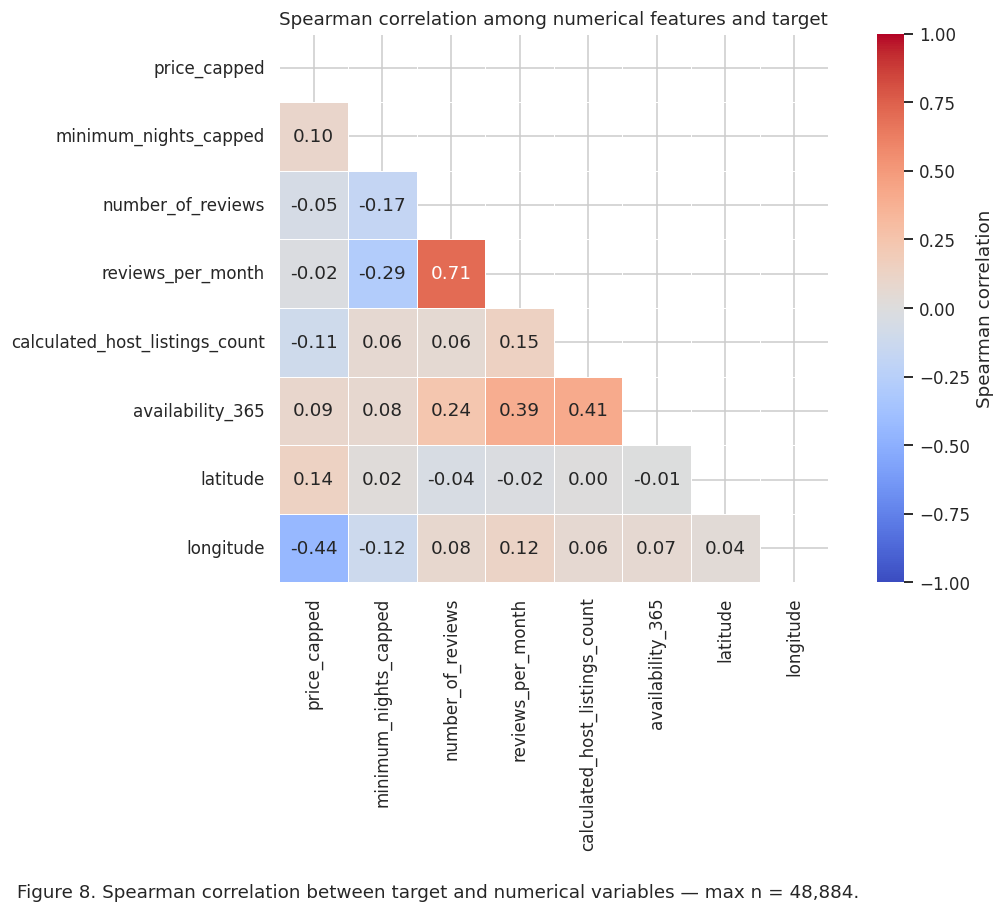

,spearman_corr_with_price
longitude,-0.437895
latitude,0.136048
calculated_host_listings_count,-0.105719
minimum_nights_capped,0.101317
availability_365,0.086181
number_of_reviews,-0.054881
reviews_per_month,-0.018486


In [ ]:
# Cell 9 - Correlation heatmap
# Dùng Spearman vì nhiều biến lệch phải, có outlier và có thể có quan hệ đơn điệu phi tuyến.

correlation_features = [
    "price_capped",
    "minimum_nights_capped",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude"
]

corr = df_viz[correlation_features].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"},
    ax=ax
)

ax.set_title("Spearman correlation among numerical features and target")
fig.text(
    0.5, -0.03,
    f"Figure 8. Spearman correlation between target and numerical variables — max n = {len(df_viz):,}.",
    ha="center"
)

plt.tight_layout()
plt.show()

# Bảng hỗ trợ viết insight: xếp hạng tương quan với price
target_correlations = (
    corr["price_capped"]
    .drop("price_capped")
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .rename("spearman_corr_with_price")
    .to_frame()
)

target_correlations

Biểu đồ cho thấy các biến số có tương quan đơn biến tương đối yếu với giá thuê. Trong số các biến được xem xét, longitude có mức tương quan Spearman lớn nhất với biến mục tiêu (ρ = -0.44), phản ánh vai trò quan trọng của vị trí địa lý đối với giá thuê Airbnb. Các biến còn lại như minimum_nights, availability_365, number_of_reviews và reviews_per_month chỉ thể hiện mối liên hệ yếu với giá. Ngoài ra, number_of_reviews và reviews_per_month có tương quan mạnh với nhau (ρ = 0.71), cho thấy khả năng tồn tại thông tin chồng lặp giữa hai biến này trong quá trình xây dựng mô hình.

Câu hỏi: Trong các neighbourhood có ít nhất 30 listing, 10 neighbourhood nào ở Manhattan và Brooklyn có giá thuê trung vị cao nhất, và chênh lệch giá giữa các neighbourhood này lớn đến mức nào?

In [ ]:
# Cell 1 - Chuẩn bị dữ liệu
# Giả sử df đã được đọc từ AB_NYC_2019.csv


BOROUGHS_TO_ANALYZE = ["Manhattan", "Brooklyn"]
MIN_LISTINGS = 30
TOP_N = 10

df_neighbourhood = df.loc[
    df["price"].notna()
    & (df["price"] > 0)
    & df["neighbourhood_group"].isin(BOROUGHS_TO_ANALYZE)
    & df["neighbourhood"].notna()
].copy()


# Tính giá trị phân vị thứ 99 (P99)
price_cap = df_neighbourhood["price"].quantile(0.99)

# Capping lại giá dựa trên ngưỡng P99
df_neighbourhood["price_capped"] = (
    df_neighbourhood["price"].clip(upper=price_cap)
)

print(f"Price cap theo P99: ${price_cap:,.0f}")
print(f"Số listing dùng để phân tích: {len(df_neighbourhood):,}")

Price cap theo P99: $800
Số listing dùng để phân tích: 41,755


In [ ]:
# Cell 2 - SQL DuckDB
# Xếp hạng theo median price; chỉ giữ neighbourhood có >= 30 listing.

sql_top_neighbourhoods = duckdb.sql(f"""
    WITH neighbourhood_summary AS (
        SELECT
            neighbourhood_group,
            neighbourhood,
            COUNT(*) AS n_listings,
            MEDIAN(price_capped) AS median_price_capped,
            AVG(price_capped) AS mean_price_capped
        FROM df_neighbourhood
        GROUP BY
            neighbourhood_group,
            neighbourhood
        HAVING COUNT(*) >= {MIN_LISTINGS}
    ),

    ranked_neighbourhoods AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY neighbourhood_group
                ORDER BY
                    median_price_capped DESC,
                    n_listings DESC
            ) AS price_rank
        FROM neighbourhood_summary
    )

    SELECT
        neighbourhood_group,
        price_rank,
        neighbourhood,
        n_listings,
        median_price_capped,
        mean_price_capped
    FROM ranked_neighbourhoods
    WHERE price_rank <= {TOP_N}
    ORDER BY
        neighbourhood_group,
        price_rank
""").df()

sql_top_neighbourhoods

,neighbourhood_group,price_rank,neighbourhood,n_listings,median_price_capped,mean_price_capped
0,Brooklyn,1,DUMBO,36,189.0,196.305556
1,Brooklyn,2,Vinegar Hill,34,175.0,187.176471
2,Brooklyn,3,Cobble Hill,99,156.0,200.313131
3,Brooklyn,4,Carroll Gardens,233,150.0,173.360515
4,Brooklyn,5,Boerum Hill,177,150.0,174.440678
5,Brooklyn,6,Brooklyn Heights,154,150.0,201.305195
6,Brooklyn,7,Park Slope,506,145.0,171.221344
7,Brooklyn,8,South Slope,284,135.0,146.725352
8,Brooklyn,9,Downtown Brooklyn,83,135.0,150.349398
9,Brooklyn,10,Columbia St,42,132.5,156.285714


In [ ]:
# Cell 3 - Python/pandas: logic tương đương SQL

python_top_neighbourhoods = (
    df_neighbourhood
    .groupby(
        ["neighbourhood_group", "neighbourhood"],
        as_index=False
    )
    .agg(
        n_listings=("price", "size"),
        median_price_capped=("price_capped", "median"),
        mean_price_capped=("price_capped", "mean")
    )
    .query("n_listings >= @MIN_LISTINGS")
    .sort_values(
        [
            "neighbourhood_group",
            "median_price_capped",
            "n_listings"
        ],
        ascending=[True, False, False]
    )
)

python_top_neighbourhoods["price_rank"] = (
    python_top_neighbourhoods
    .groupby("neighbourhood_group")
    .cumcount()
    .add(1)
)

python_top_neighbourhoods = (
    python_top_neighbourhoods
    .query("price_rank <= @TOP_N")
    .loc[
        :,
        [
            "neighbourhood_group",
            "price_rank",
            "neighbourhood",
            "n_listings",
            "median_price_capped",
            "mean_price_capped"
        ]
    ]
    .reset_index(drop=True)
)

python_top_neighbourhoods

,neighbourhood_group,price_rank,neighbourhood,n_listings,median_price_capped,mean_price_capped
0,Brooklyn,1,DUMBO,36,189.0,196.305556
1,Brooklyn,2,Vinegar Hill,34,175.0,187.176471
2,Brooklyn,3,Cobble Hill,99,156.0,200.313131
3,Brooklyn,4,Carroll Gardens,233,150.0,173.360515
4,Brooklyn,5,Boerum Hill,177,150.0,174.440678
5,Brooklyn,6,Brooklyn Heights,154,150.0,201.305195
6,Brooklyn,7,Park Slope,506,145.0,171.221344
7,Brooklyn,8,South Slope,284,135.0,146.725352
8,Brooklyn,9,Downtown Brooklyn,83,135.0,150.349398
9,Brooklyn,10,Columbia St,42,132.5,156.285714


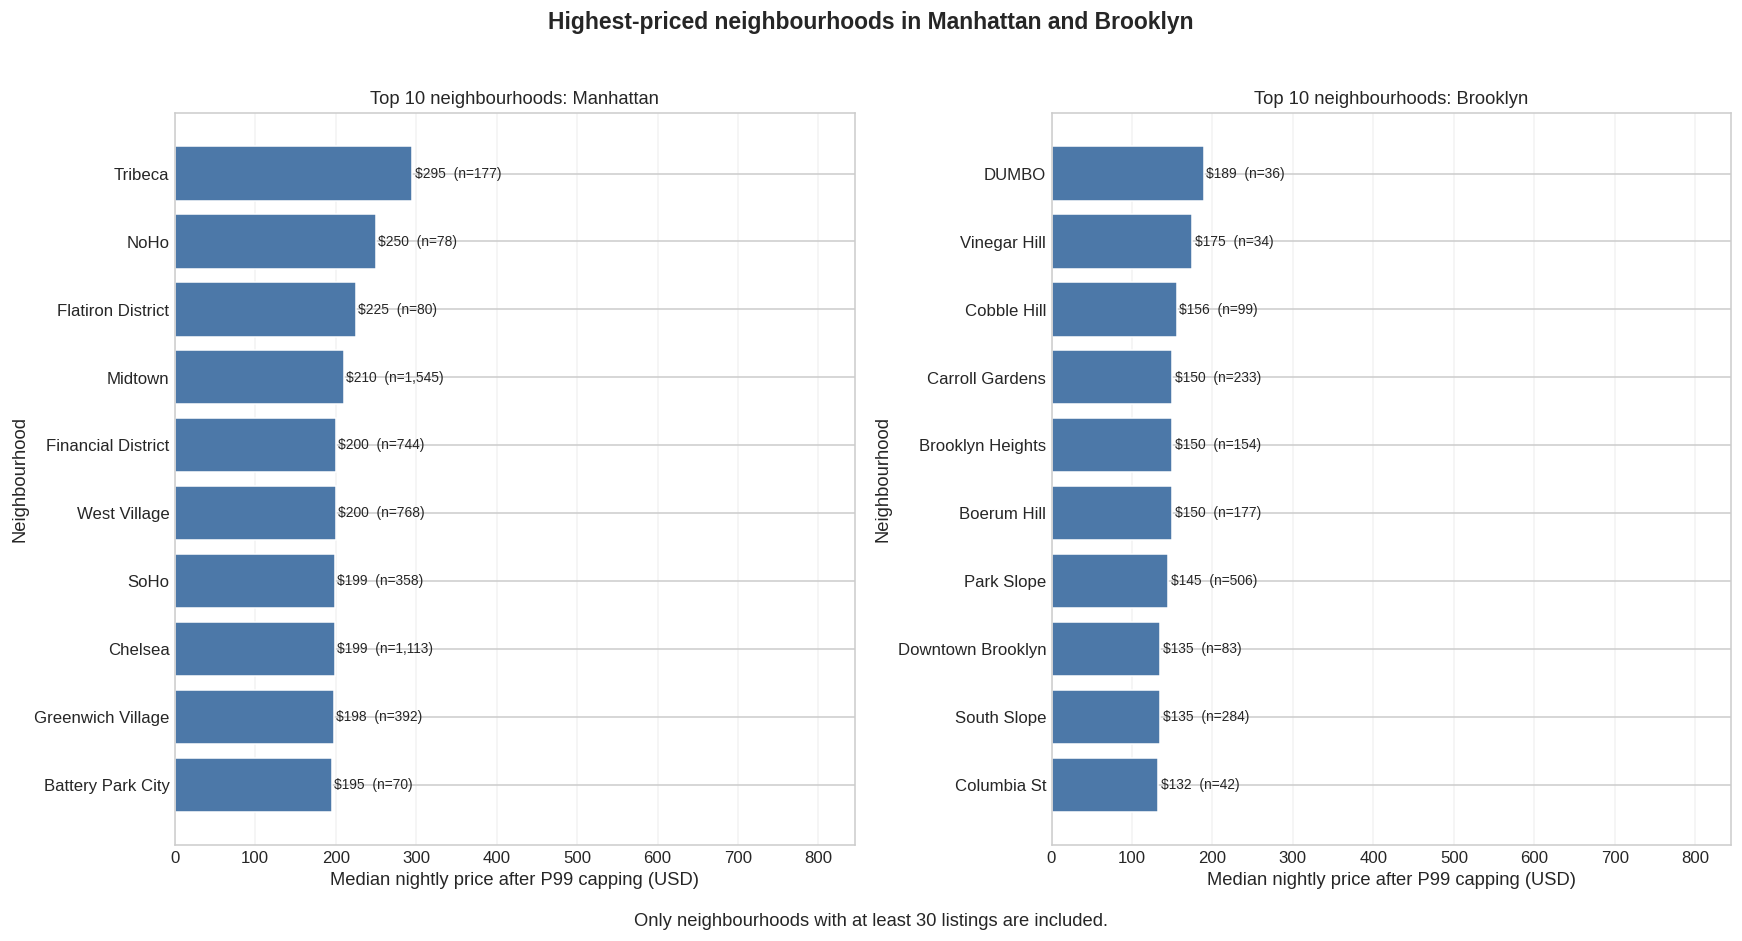

In [ ]:
# Cell 6 - Biểu đồ top 10 median price theo từng borough

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)

for ax, borough in zip(axes, BOROUGHS_TO_ANALYZE):
    plot_data = (
        python_top_neighbourhoods
        .query("neighbourhood_group == @borough")
        .sort_values("median_price_capped", ascending=True)
    )

    bars = ax.barh(
        plot_data["neighbourhood"],
        plot_data["median_price_capped"],
        color="#4C78A8"
    )

    for bar, median_price, n in zip(
        bars,
        plot_data["median_price_capped"],
        plot_data["n_listings"]
    ):
        ax.text(
            median_price + 3,
            bar.get_y() + bar.get_height() / 2,
            f"${median_price:,.0f}  (n={n:,})",
            va="center",
            fontsize=9
        )

    ax.set_title(f"Top {TOP_N} neighbourhoods: {borough}")
    ax.set_xlabel("Median nightly price after P99 capping (USD)")
    ax.set_ylabel("Neighbourhood")
    ax.set_xlim(0, price_cap + 45)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Highest-priced neighbourhoods in Manhattan and Brooklyn",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    -0.02,
    f"Only neighbourhoods with at least {MIN_LISTINGS} listings are included.",
    ha="center"
)

plt.tight_layout()
plt.show()

Kết quả thực tế từ dataset cho thấy:
- Manhattan có mức giá neighbourhood cao hơn rõ rệt. Tribeca đứng đầu với median price 295 trên 177 listing; neighbourhood thứ 10 là Battery Park City với 195. Chênh lệch trong top 10 Manhattan là $100/đêm.
- Brooklyn đứng đầu là DUMBO với 189 trên 36 listing, tiếp theo là Vinegar Hill 175 trên 34 listing. Neighbourhood thứ 10 là Columbia St với 132.50.
- DUMBO và Vinegar Hill chỉ vừa qua ngưỡng 30 listing, nên cần diễn giải thận trọng hơn Tribeca, Midtown hoặc Park Slope có số mẫu lớn.
- Ngay trong cùng borough, giá trung vị khác nhau đáng kể giữa các neighbourhood. Điều này là bằng chứng mô tả hợp lý để giữ neighbourhood trong model, thay vì chỉ dùng neighbourhood_group.

Câu hỏi: Trong cùng một khu vực và loại phòng, mức giá cao hơn hoặc thấp hơn giá trung vị có liên quan như thế nào đến số ngày có thể đặt phòng và tình trạng không còn ngày trống?

In [ ]:
# Cell 1 - Chuẩn bị dữ liệu
# Giả sử df đã được đọc từ CSV và duckdb đã được cài/import.

df_rq3 = df.loc[
    df["price"].notna()
    & (df["price"] > 0)
    & df["availability_365"].notna()
    & df["neighbourhood_group"].notna()
    & df["room_type"].notna()
].copy()

price_upper_cap = df_rq3["price"].quantile(0.99)
df_rq3["price_capped"] = df_rq3["price"].clip(upper=price_upper_cap)

print(f"Price cap: ${price_upper_cap:,.0f}")
print(f"Số listing price = 0 đã loại: {(df['price'] == 0).sum():,}")
print(f"Tỷ lệ availability_365 = 0: {(df_rq3['availability_365'] == 0).mean() * 100:.1f}%")

Price cap: $799
Số listing price = 0 đã loại: 0
Tỷ lệ availability_365 = 0: 35.9%


In [ ]:
# Bước 1: Xác định ngưỡng trung vị giá theo Khu vực × Loại phòng
# Giá cao/thấp được xác định tương đối trong cùng 1 nhóm, KHÔNG dùng ngưỡng chung
duckdb.sql("""
    SELECT
        neighbourhood_group,
        room_type,
        COUNT(*) AS n_listings,
        ROUND(MEDIAN(price), 2) AS group_median_price
    FROM df_rq3
    GROUP BY neighbourhood_group, room_type
    ORDER BY neighbourhood_group, room_type
""").df()

,neighbourhood_group,room_type,n_listings,group_median_price
0,Bronx,Entire home/apt,379,100.0
1,Bronx,Private room,651,54.0
2,Bronx,Shared room,60,40.0
3,Brooklyn,Entire home/apt,9558,145.0
4,Brooklyn,Private room,10126,65.0
5,Brooklyn,Shared room,411,36.0
6,Manhattan,Entire home/apt,13198,191.0
7,Manhattan,Private room,7982,90.0
8,Manhattan,Shared room,480,69.0
9,Queens,Entire home/apt,2096,120.0


In [ ]:
# Bước 2: Gán nhãn Giá thấp / Giá cao dựa trên trung vị của nhóm
duckdb.sql("""
    WITH group_medians AS (
        SELECT
            neighbourhood_group,
            room_type,
            MEDIAN(price) AS group_median_price
        FROM df_rq3
        GROUP BY neighbourhood_group, room_type
    )
    SELECT
        d.neighbourhood_group,
        d.room_type,
        d.price,
        m.group_median_price,
        CASE
            WHEN d.price <= m.group_median_price THEN 'Low price (<= group median)'
            ELSE 'High price (> group median)'
        END AS price_band
    FROM df_rq3 AS d
    INNER JOIN group_medians AS m
        ON d.neighbourhood_group = m.neighbourhood_group
       AND d.room_type = m.room_type
    LIMIT 10  -- Xem 10 dòng ví dụ
""").df()

,neighbourhood_group,room_type,price,group_median_price,price_band
0,Brooklyn,Private room,149,65.0,High price (> group median)
1,Manhattan,Entire home/apt,225,191.0,High price (> group median)
2,Manhattan,Private room,150,90.0,High price (> group median)
3,Brooklyn,Entire home/apt,89,145.0,Low price (<= group median)
4,Manhattan,Entire home/apt,80,191.0,Low price (<= group median)
5,Manhattan,Entire home/apt,200,191.0,High price (> group median)
6,Brooklyn,Private room,60,65.0,Low price (<= group median)
7,Manhattan,Private room,79,90.0,Low price (<= group median)
8,Manhattan,Private room,79,90.0,Low price (<= group median)
9,Manhattan,Entire home/apt,150,191.0,Low price (<= group median)


In [ ]:
# Bước 3: Tổng hợp số lượng tin theo mức giá trong từng nhóm
duckdb.sql("""
    WITH group_medians AS (
        SELECT
            neighbourhood_group,
            room_type,
            MEDIAN(price) AS group_median_price
        FROM df_rq3
        GROUP BY neighbourhood_group, room_type
    ),
    price_bands AS (
        SELECT
            d.*,
            CASE
                WHEN d.price <= m.group_median_price THEN 'Low price (<= group median)'
                ELSE 'High price (> group median)'
            END AS price_band,
            CASE
                WHEN d.price <= m.group_median_price THEN 1 ELSE 2
            END AS price_band_order
        FROM df_rq3 AS d
        INNER JOIN group_medians AS m
            ON d.neighbourhood_group = m.neighbourhood_group
           AND d.room_type = m.room_type
    )
    SELECT
        neighbourhood_group,
        room_type,
        price_band,
        COUNT(*) AS n_listings,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY neighbourhood_group, room_type), 1) AS pct_of_group
    FROM price_bands
    GROUP BY neighbourhood_group, room_type, price_band, price_band_order
    ORDER BY neighbourhood_group, room_type, price_band_order
""").df()

,neighbourhood_group,room_type,price_band,n_listings,pct_of_group
0,Bronx,Entire home/apt,Low price (<= group median),199,52.5
1,Bronx,Entire home/apt,High price (> group median),180,47.5
2,Bronx,Private room,Low price (<= group median),327,50.2
3,Bronx,Private room,High price (> group median),324,49.8
4,Bronx,Shared room,Low price (<= group median),32,53.3
5,Bronx,Shared room,High price (> group median),28,46.7
6,Brooklyn,Entire home/apt,Low price (<= group median),4798,50.2
7,Brooklyn,Entire home/apt,High price (> group median),4760,49.8
8,Brooklyn,Private room,Low price (<= group median),5621,55.5
9,Brooklyn,Private room,High price (> group median),4505,44.5


In [ ]:
# Cell 2 - SQL DuckDB
# Giá cao/thấp được xác định tương đối trong cùng neighbourhood_group × room_type.

sql_rq3 = duckdb.sql("""
    WITH group_medians AS (
        SELECT
            neighbourhood_group,
            room_type,
            MEDIAN(price) AS group_median_price
        FROM df_rq3
        GROUP BY neighbourhood_group, room_type
    ),

    price_bands AS (
        SELECT
            d.*,
            m.group_median_price,
            CASE
                WHEN d.price <= m.group_median_price
                    THEN 'Low price (<= group median)'
                ELSE 'High price (> group median)'
            END AS price_band,
            CASE
                WHEN d.price <= m.group_median_price THEN 1
                ELSE 2
            END AS price_band_order
        FROM df_rq3 AS d
        INNER JOIN group_medians AS m
            ON d.neighbourhood_group = m.neighbourhood_group
            AND d.room_type = m.room_type
    )

    SELECT
        neighbourhood_group,
        room_type,
        price_band,
        COUNT(*) AS n_listings,
        ROUND(MAX(group_median_price), 2) AS group_median_price,
        ROUND(AVG(price_capped), 2) AS capped_mean_price,
        ROUND(MEDIAN(price), 2) AS observed_median_price,
        ROUND(AVG(availability_365), 2) AS avg_availability_365,
        ROUND(MEDIAN(availability_365), 2) AS median_availability_365,
        ROUND(
            100.0 * AVG(
                CASE WHEN availability_365 = 0 THEN 1 ELSE 0 END
            ),
            2
        ) AS zero_availability_pct,
        ROUND(
            AVG(CASE WHEN availability_365 > 0 THEN availability_365 END),
            2
        ) AS avg_availability_when_active
    FROM price_bands
    GROUP BY
        neighbourhood_group,
        room_type,
        price_band,
        price_band_order
    ORDER BY
        neighbourhood_group,
        room_type,
        price_band_order
""").df()

sql_rq3

,neighbourhood_group,room_type,price_band,n_listings,group_median_price,capped_mean_price,observed_median_price,avg_availability_365,median_availability_365,zero_availability_pct,avg_availability_when_active
0,Bronx,Entire home/apt,Low price (<= group median),199,100.0,78.85,80.0,140.75,107.0,18.59,172.90
1,Bronx,Entire home/apt,High price (> group median),180,100.0,180.18,143.5,177.07,167.0,13.33,204.31
2,Bronx,Private room,Low price (<= group median),327,54.0,40.93,40.0,157.05,148.0,17.74,190.91
3,Bronx,Private room,High price (> group median),324,54.0,87.85,70.0,185.89,174.0,14.81,218.21
4,Bronx,Shared room,Low price (<= group median),32,40.0,27.88,28.0,125.81,83.0,12.50,143.79
5,Bronx,Shared room,High price (> group median),28,40.0,96.25,58.5,186.68,168.5,21.43,237.59
6,Brooklyn,Entire home/apt,Low price (<= group median),4798,145.0,105.27,105.0,82.33,14.0,40.56,138.51
7,Brooklyn,Entire home/apt,High price (> group median),4760,145.0,236.41,199.0,112.20,48.5,32.37,165.92
8,Brooklyn,Private room,Low price (<= group median),5621,65.0,50.18,50.0,90.75,10.0,45.72,167.19
9,Brooklyn,Private room,High price (> group median),4505,65.0,103.54,85.0,111.35,49.0,37.29,177.57


In [ ]:
# Cell 3 - Python/pandas: logic tương đương SQL

df_rq3["group_median_price"] = (
    df_rq3.groupby(["neighbourhood_group", "room_type"])["price"]
    .transform("median")
)

df_rq3["price_band"] = np.where(
    df_rq3["price"] <= df_rq3["group_median_price"],
    "Low price (<= group median)",
    "High price (> group median)"
)

df_rq3["price_band_order"] = np.where(
    df_rq3["price_band"] == "Low price (<= group median)",
    1,
    2
)

python_rq3 = (
    df_rq3.groupby(
        ["neighbourhood_group", "room_type", "price_band", "price_band_order"],
        as_index=False
    )
    .agg(
        n_listings=("price", "size"),
        group_median_price=("group_median_price", "first"),
        capped_mean_price=("price_capped", "mean"),
        observed_median_price=("price", "median"),
        avg_availability_365=("availability_365", "mean"),
        median_availability_365=("availability_365", "median"),
        zero_availability_pct=(
            "availability_365",
            lambda x: 100 * x.eq(0).mean()
        ),
        avg_availability_when_active=(
            "availability_365",
            lambda x: x[x.gt(0)].mean()
        )
    )
    .sort_values(
        ["neighbourhood_group", "room_type", "price_band_order"]
    )
    .drop(columns="price_band_order")
    .reset_index(drop=True)
    .round(2)
)

python_rq3

,neighbourhood_group,room_type,price_band,n_listings,group_median_price,capped_mean_price,observed_median_price,avg_availability_365,median_availability_365,zero_availability_pct,avg_availability_when_active
0,Bronx,Entire home/apt,Low price (<= group median),199,100.0,78.85,80.0,140.75,107.0,18.59,172.90
1,Bronx,Entire home/apt,High price (> group median),180,100.0,180.18,143.5,177.07,167.0,13.33,204.31
2,Bronx,Private room,Low price (<= group median),327,54.0,40.93,40.0,157.05,148.0,17.74,190.91
3,Bronx,Private room,High price (> group median),324,54.0,87.85,70.0,185.89,174.0,14.81,218.21
4,Bronx,Shared room,Low price (<= group median),32,40.0,27.88,28.0,125.81,83.0,12.50,143.79
5,Bronx,Shared room,High price (> group median),28,40.0,96.25,58.5,186.68,168.5,21.43,237.59
6,Brooklyn,Entire home/apt,Low price (<= group median),4798,145.0,105.27,105.0,82.33,14.0,40.56,138.51
7,Brooklyn,Entire home/apt,High price (> group median),4760,145.0,236.41,199.0,112.20,48.5,32.37,165.92
8,Brooklyn,Private room,Low price (<= group median),5621,65.0,50.18,50.0,90.75,10.0,45.72,167.19
9,Brooklyn,Private room,High price (> group median),4505,65.0,103.54,85.0,111.35,49.0,37.29,177.57


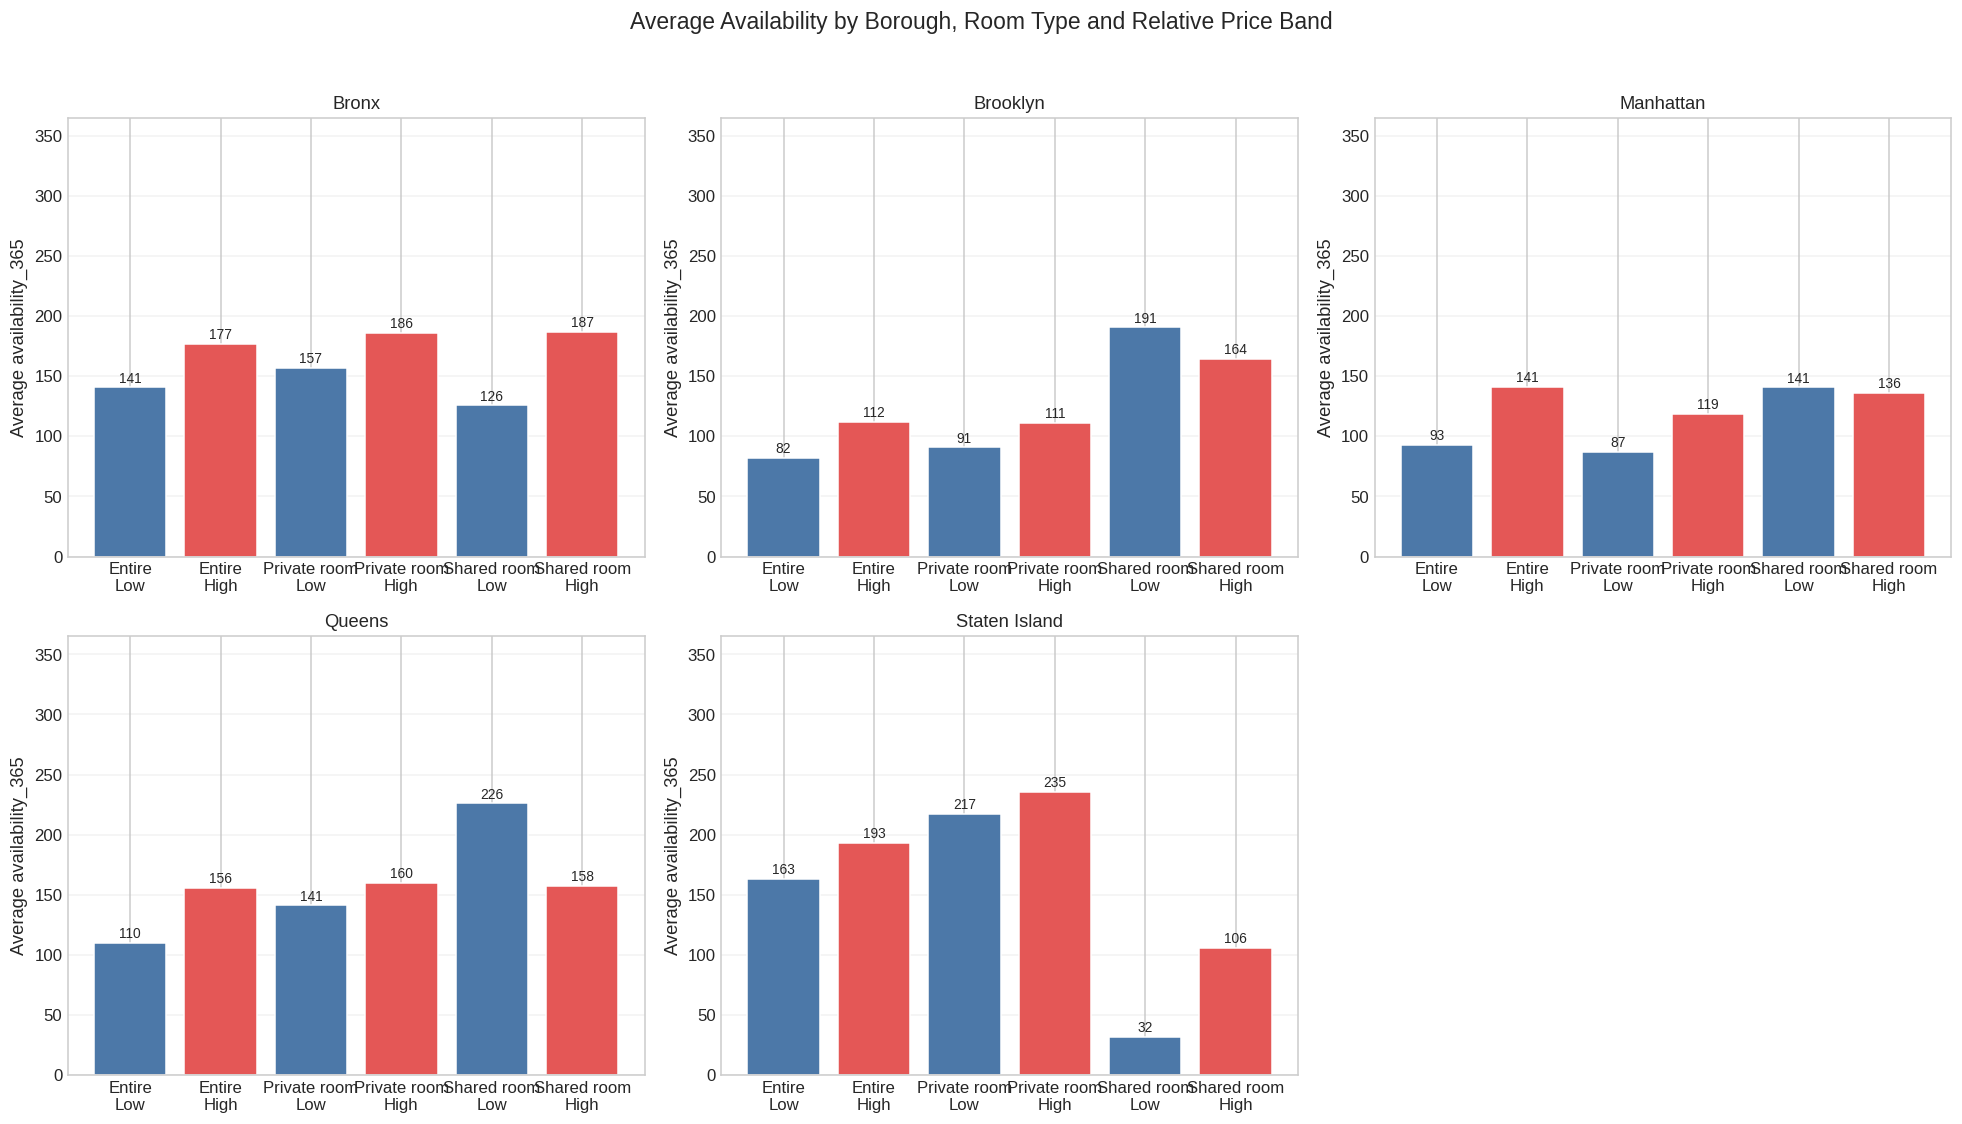

In [ ]:
# Cell 5 - Biểu đồ availability trung bình theo borough, room type và price band

plot_df = python_rq3.copy()

boroughs = plot_df["neighbourhood_group"].unique()
colors = {
    "Low price (<= group median)": "#4C78A8",
    "High price (> group median)": "#E45756"
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, borough in zip(axes, boroughs):
    subset = plot_df[plot_df["neighbourhood_group"] == borough].copy()

    labels = [
        f"{room.replace('Entire home/apt', 'Entire')}\n"
        f"{'Low' if 'Low' in band else 'High'}"
        for room, band in zip(subset["room_type"], subset["price_band"])
    ]

    bars = ax.bar(
        labels,
        subset["avg_availability_365"],
        color=[colors[x] for x in subset["price_band"]]
    )

    for bar, value in zip(bars, subset["avg_availability_365"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 4,
            f"{value:.0f}",
            ha="center",
            fontsize=9
        )

    ax.set_title(borough)
    ax.set_ylabel("Average availability_365")
    ax.set_ylim(0, 365)
    ax.grid(axis="y", alpha=0.25)

# Ẩn subplot thừa vì chỉ có 5 borough
for ax in axes[len(boroughs):]:
    ax.set_visible(False)

fig.suptitle(
    "Average Availability by Borough, Room Type and Relative Price Band",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

High price có availability trung bình cao hơn rõ rệt trong cùng khu vực và loại phòng: đây là một tín hiệu có thể của định giá cao hoặc nhu cầu yếu.

Low price có availability thấp: có thể là giá hấp dẫn và booking tốt, nhưng cũng có thể host chủ động khóa lịch.

zero_availability_pct cao: không thể mặc định là “đã kín lịch”; nên đưa đây vào phần hạn chế của phân tích.

Không nên dùng bảng này để nói khu vực “nổi tiếng” hay không. availability_365 là lịch còn mở, không phải số booking thật.

Câu hỏi: Trong cùng một khu vực và loại phòng, các listing có số lượt review trung bình mỗi tháng khác nhau có mức giá cao hơn hoặc thấp hơn so với mặt bằng chung như thế nào?

In [ ]:
# Cell 1 - Chuẩn bị dữ liệu và tạo review groups

# Loại price = 0 vì không phù hợp để phân tích premium
df_review = df.loc[
    df["price"].notna()
    & (df["price"] > 0)
    & df["neighbourhood_group"].notna()
    & df["room_type"].notna()
].copy()

price_cap = df_review["price"].quantile(0.99)
df_review["price_capped"] = df_review["price"].clip(upper=price_cap)

# Chia 3 nhóm review rate theo phân vị 33% và 67%
# Chỉ dùng listing có reviews_per_month > 0 để tính ngưỡng.
rpm_positive = df_review.loc[
    df_review["reviews_per_month"] > 0,
    "reviews_per_month"
]

rpm_low_cut, rpm_high_cut = rpm_positive.quantile([1/3, 2/3])

review_group_order = [
    "No reviews / missing rate",
    f"Low (>0-{rpm_low_cut:.2f})",
    f"Medium ({rpm_low_cut:.2f}-{rpm_high_cut:.2f})",
    f"High (>{rpm_high_cut:.2f})"
]

df_review["review_group"] = np.select(
    [
        df_review["reviews_per_month"].isna()
        | (df_review["reviews_per_month"] <= 0),

        (df_review["reviews_per_month"] > 0)
        & (df_review["reviews_per_month"] <= rpm_low_cut),

        (df_review["reviews_per_month"] > rpm_low_cut)
        & (df_review["reviews_per_month"] <= rpm_high_cut)
    ],
    [
        review_group_order[0],
        review_group_order[1],
        review_group_order[2]
    ],
    default=review_group_order[3]
)

df_review["review_group"] = pd.Categorical(
    df_review["review_group"],
    categories=review_group_order,
    ordered=True
)

# Benchmark giá trong cùng borough × room type
df_review["peer_median_price"] = (
    df_review.groupby(["neighbourhood_group", "room_type"])["price_capped"]
    .transform("median")
)

# Premium dương: giá cao hơn peer median
# Premium âm: giá thấp hơn peer median
df_review["price_premium_pct"] = (
    100
    * (df_review["price_capped"] - df_review["peer_median_price"])
    / df_review["peer_median_price"]
)

print(f"Price cap theo IQR: ${price_cap:,.0f}")
print(f"Ngưỡng Low review rate: <= {rpm_low_cut:.2f} reviews/month")
print(f"Ngưỡng High review rate: > {rpm_high_cut:.2f} reviews/month")
print(f"Số listing dùng để phân tích: {len(df_review):,}")

Price cap theo IQR: $799
Ngưỡng Low review rate: <= 0.30 reviews/month
Ngưỡng High review rate: > 1.46 reviews/month
Số listing dùng để phân tích: 48,884


In [ ]:
# Cell 2 - Kiểm tra nhóm No reviews / missing rate

review_missing_check = pd.crosstab(
    df_review["reviews_per_month"].isna(),
    df_review["number_of_reviews"].eq(0),
    margins=True
)

review_missing_check

number_of_reviews,False,True,All
reviews_per_month,,,
False,38833,0,38833
True,0,10051,10051
All,38833,10051,48884


In [ ]:
# Cell 2: Kiểm tra phân bố số lượng theo nhóm đánh giá
df_review.groupby("review_group", observed=False).size().reset_index(name="n_listings")

,review_group,n_listings
0,No reviews / missing rate,10051
1,Low (>0-0.30),12945
2,Medium (0.30-1.46),13009
3,High (>1.46),12879


In [ ]:
# Cell 3 - SQL DuckDB
# Câu hỏi: Trong từng borough × room type, review rate có liên hệ với price premium không?

# Cell 3 - SQL DuckDB
# Không ROUND() trong SQL để tránh khác biệt làm tròn với pandas.

sql_review_result = duckdb.sql("""
    SELECT
        neighbourhood_group,
        room_type,
        review_group,
        COUNT(*) AS n_listings,
        MAX(peer_median_price) AS peer_median_price,
        AVG(reviews_per_month) AS mean_reviews_per_month,
        MEDIAN(reviews_per_month) AS median_reviews_per_month,
        AVG(price_capped) AS mean_price_capped,
        MEDIAN(price_capped) AS median_price_capped,
        AVG(price_premium_pct) AS mean_price_premium_pct,
        MEDIAN(price_premium_pct) AS median_price_premium_pct
    FROM df_review
    GROUP BY
        neighbourhood_group,
        room_type,
        review_group
    ORDER BY
        neighbourhood_group,
        room_type,
        review_group
""").df()

In [ ]:
# Cell 4 - Python/pandas: logic tương đương SQL

# Cell 4 - Python/pandas
# Không .round(2) ở đây.

python_review_result = (
    df_review.groupby(
        ["neighbourhood_group", "room_type", "review_group"],
        observed=True,
        as_index=False
    )
    .agg(
        n_listings=("price", "size"),
        peer_median_price=("peer_median_price", "first"),
        mean_reviews_per_month=("reviews_per_month", "mean"),
        median_reviews_per_month=("reviews_per_month", "median"),
        mean_price_capped=("price_capped", "mean"),
        median_price_capped=("price_capped", "median"),
        mean_price_premium_pct=("price_premium_pct", "mean"),
        median_price_premium_pct=("price_premium_pct", "median")
    )
    .sort_values(
        ["neighbourhood_group", "room_type", "review_group"]
    )
    .reset_index(drop=True)
)


In [ ]:
# Cell 6 - Chỉ format 2 chữ số khi hiển thị, không làm thay đổi giá trị tính toán

format_map = {
    "n_listings": "{:,.0f}",
    "peer_median_price": "${:,.2f}",
    "mean_reviews_per_month": "{:.2f}",
    "median_reviews_per_month": "{:.2f}",
    "mean_price_capped": "${:,.2f}",
    "median_price_capped": "${:,.2f}",
    "mean_price_premium_pct": "{:+.2f}%",
    "median_price_premium_pct": "{:+.2f}%"
}

print("Kết quả SQL")
display(sql_review_result.style.format(format_map, na_rep="—"))

print("Kết quả Python")
display(python_review_result.style.format(format_map, na_rep="—"))

Kết quả SQL


,neighbourhood_group,room_type,review_group,n_listings,peer_median_price,mean_reviews_per_month,median_reviews_per_month,mean_price_capped,median_price_capped,mean_price_premium_pct,median_price_premium_pct
0,Bronx,Entire home/apt,No reviews / missing rate,70,$100.00,—,—,$154.29,$110.00,+54.29%,+10.00%
1,Bronx,Entire home/apt,Low (>0-0.30),44,$100.00,0.15,0.16,$126.64,$105.00,+26.64%,+5.00%
2,Bronx,Entire home/apt,Medium (0.30-1.46),89,$100.00,0.84,0.82,$136.91,$105.00,+36.91%,+5.00%
3,Bronx,Entire home/apt,High (>1.46),176,$100.00,3.47,3.10,$111.18,$99.00,+11.18%,-1.00%
4,Bronx,Private room,No reviews / missing rate,128,$54.00,—,—,$93.19,$65.00,+72.57%,+20.37%
5,Bronx,Private room,Low (>0-0.30),106,$54.00,0.16,0.16,$61.77,$60.00,+14.40%,+11.11%
6,Bronx,Private room,Medium (0.30-1.46),188,$54.00,0.81,0.79,$56.02,$50.00,+3.73%,-7.41%
7,Bronx,Private room,High (>1.46),229,$54.00,3.00,2.65,$56.06,$50.00,+3.82%,-7.41%
8,Bronx,Shared room,No reviews / missing rate,17,$40.00,—,—,$67.06,$55.00,+67.65%,+37.50%
9,Bronx,Shared room,Low (>0-0.30),8,$40.00,0.15,0.15,$144.00,$53.00,+260.00%,+32.50%


Kết quả Python


,neighbourhood_group,room_type,review_group,n_listings,peer_median_price,mean_reviews_per_month,median_reviews_per_month,mean_price_capped,median_price_capped,mean_price_premium_pct,median_price_premium_pct
0,Bronx,Entire home/apt,No reviews / missing rate,70,$100.00,—,—,$154.29,$110.00,+54.29%,+10.00%
1,Bronx,Entire home/apt,Low (>0-0.30),44,$100.00,0.15,0.16,$126.64,$105.00,+26.64%,+5.00%
2,Bronx,Entire home/apt,Medium (0.30-1.46),89,$100.00,0.84,0.82,$136.91,$105.00,+36.91%,+5.00%
3,Bronx,Entire home/apt,High (>1.46),176,$100.00,3.47,3.10,$111.18,$99.00,+11.18%,-1.00%
4,Bronx,Private room,No reviews / missing rate,128,$54.00,—,—,$93.19,$65.00,+72.57%,+20.37%
5,Bronx,Private room,Low (>0-0.30),106,$54.00,0.16,0.16,$61.77,$60.00,+14.40%,+11.11%
6,Bronx,Private room,Medium (0.30-1.46),188,$54.00,0.81,0.79,$56.02,$50.00,+3.73%,-7.41%
7,Bronx,Private room,High (>1.46),229,$54.00,3.00,2.65,$56.06,$50.00,+3.82%,-7.41%
8,Bronx,Shared room,No reviews / missing rate,17,$40.00,—,—,$67.06,$55.00,+67.65%,+37.50%
9,Bronx,Shared room,Low (>0-0.30),8,$40.00,0.15,0.15,$144.00,$53.00,+260.00%,+32.50%


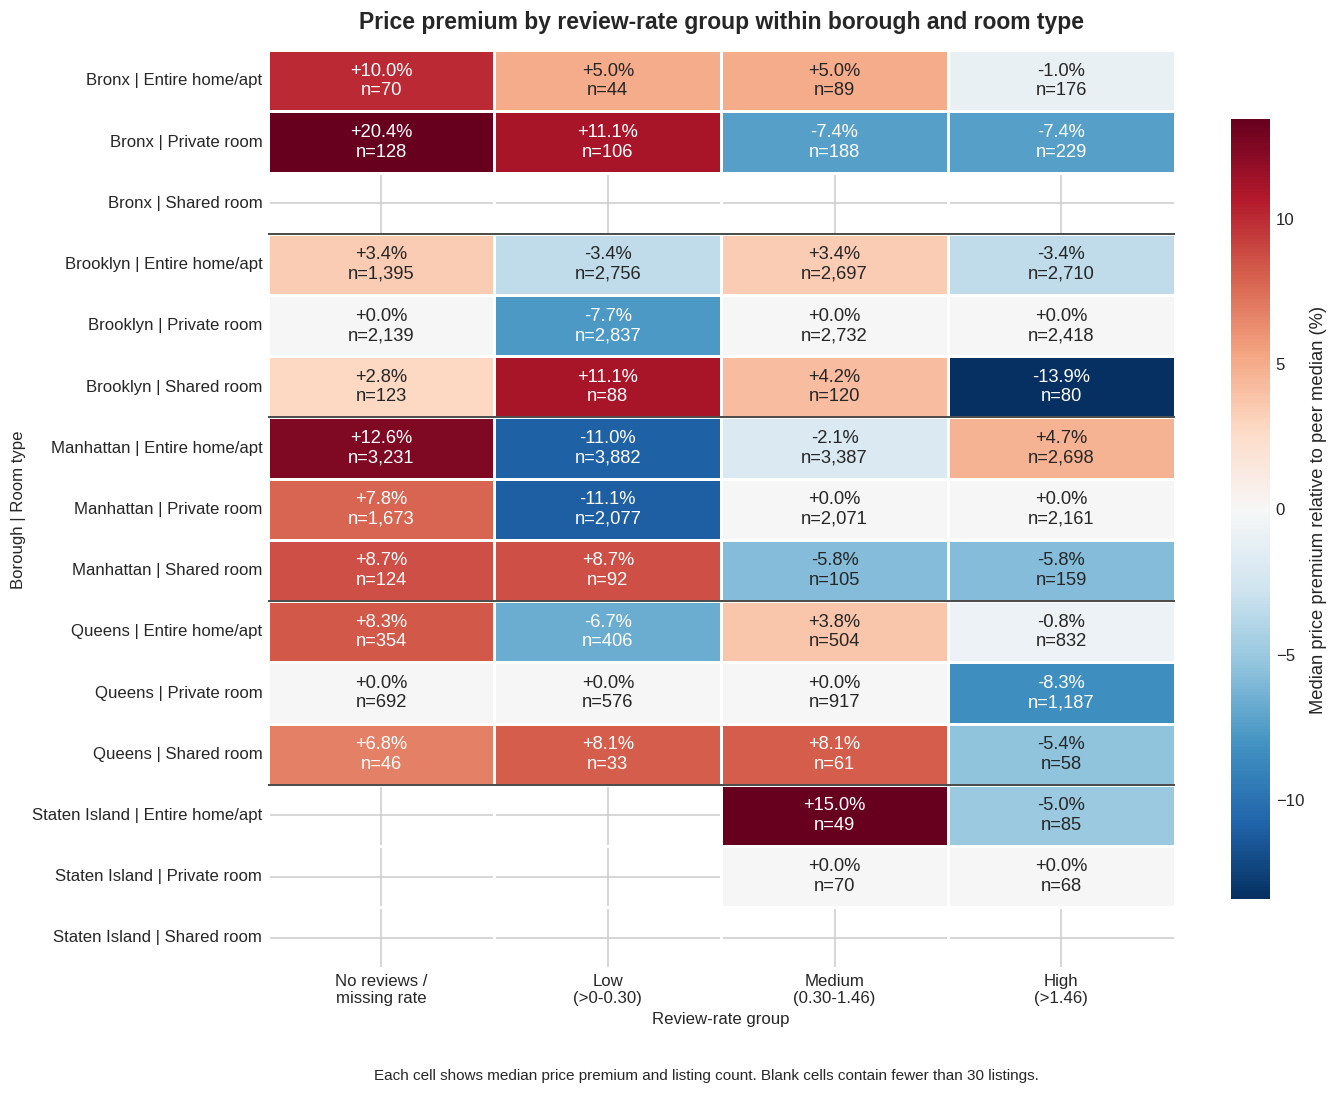

In [ ]:
# Cell 8 - Biểu đồ chi tiết theo borough × room type
# Chỉ giữ nhóm có ít nhất 30 listing trên biểu đồ để giảm kết luận từ mẫu quá nhỏ.
# Bảng SQL/Python phía trên vẫn giữ toàn bộ nhóm.

# Cell 7 - Heatmap price premium theo borough × room type × review group

MIN_LISTINGS_FOR_PLOT = 30

borough_order = [
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island"
]

room_type_order = [
    "Entire home/apt",
    "Private room",
    "Shared room"
]

row_order = [
    f"{borough} | {room_type}"
    for borough in borough_order
    for room_type in room_type_order
]

plot_heatmap = python_review_result.copy()

plot_heatmap["borough_room_type"] = (
    plot_heatmap["neighbourhood_group"]
    + " | "
    + plot_heatmap["room_type"]
)

premium_matrix = (
    plot_heatmap.pivot(
        index="borough_room_type",
        columns="review_group",
        values="median_price_premium_pct"
    )
    .reindex(index=row_order, columns=review_group_order)
)

count_matrix = (
    plot_heatmap.pivot(
        index="borough_room_type",
        columns="review_group",
        values="n_listings"
    )
    .reindex(index=row_order, columns=review_group_order)
)

# Không hiển thị các nhóm có ít hơn 30 listing.
mask = count_matrix.isna() | count_matrix.lt(MIN_LISTINGS_FOR_PLOT)

annotation_matrix = premium_matrix.copy().astype(object)

for row in premium_matrix.index:
    for col in premium_matrix.columns:
        if not mask.loc[row, col]:
            premium = premium_matrix.loc[row, col]
            n = int(count_matrix.loc[row, col])
            annotation_matrix.loc[row, col] = f"{premium:+.1f}%\nn={n:,}"
        else:
            annotation_matrix.loc[row, col] = ""

# Cố định thang màu đối xứng quanh 0 để so sánh premium và discount công bằng.
valid_values = premium_matrix.mask(mask).to_numpy().flatten()
valid_values = valid_values[~np.isnan(valid_values)]

color_limit = np.percentile(np.abs(valid_values), 95)
color_limit = max(color_limit, 10)

display_labels = {
    review_group_order[0]: "No reviews /\nmissing rate",
    review_group_order[1]: f"Low\n(>0-{rpm_low_cut:.2f})",
    review_group_order[2]: f"Medium\n({rpm_low_cut:.2f}-{rpm_high_cut:.2f})",
    review_group_order[3]: f"High\n(>{rpm_high_cut:.2f})"
}

premium_matrix_plot = premium_matrix.rename(columns=display_labels)
mask_plot = mask.rename(columns=display_labels)
annotation_matrix_plot = annotation_matrix.rename(columns=display_labels)

fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    premium_matrix_plot,
    mask=mask_plot,
    annot=annotation_matrix_plot,
    fmt="",
    cmap="RdBu_r",
    center=0,
    vmin=-color_limit,
    vmax=color_limit,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Median price premium relative to peer median (%)",
        "shrink": 0.85
    },
    ax=ax
)

# Phân tách trực quan từng borough, mỗi borough có 3 room types.
for boundary in [3, 6, 9, 12]:
    ax.hlines(
        boundary,
        *ax.get_xlim(),
        colors="#4D4D4D",
        linewidth=1.3
    )

ax.set_title(
    "Price premium by review-rate group within borough and room type",
    fontsize=15,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Review-rate group", fontsize=11)
ax.set_ylabel("Borough | Room type", fontsize=11)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

fig.text(
    0.5,
    0.01,
    "Each cell shows median price premium and listing count. "
    f"Blank cells contain fewer than {MIN_LISTINGS_FOR_PLOT} listings.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

Heatmap cho thấy mối liên hệ giữa review rate và price premium không đồng nhất giữa các borough và room type. Vì vậy, không thể kết luận đơn giản rằng listing có nhiều review mỗi tháng luôn duy trì giá premium cao hơn.

Chỉ các ô có ít nhất 30 listing được hiển thị để tránh diễn giải các nhóm nhỏ, đặc biệt là Shared room tại Bronx và Staten Island. Các ô màu đỏ biểu thị giá trung vị cao hơn peer median, trong khi ô màu xanh biểu thị discount tương đối so với các listing cùng borough và room type.

Ở Manhattan, Entire home/apt có review rate cao có median premium dương, trong khi nhóm review rate thấp có premium âm. Tuy vậy, pattern này không xuất hiện nhất quán ở mọi borough và loại phòng, nên review rate nên được xem là một feature có khả năng tương tác với location và room type trong mô hình dự báo giá.

Kết quả phân tích: Manhattan đắt nhất ở cả 3 room_type, nhưng chênh lệch lớn nhất ở "Entire home/apt" (gần gấp đôi Bronx), chênh lệch nhỏ hơn ở "Shared room".
Kết luận: Vị trí quyết định giá mạnh nhất khi thuê nguyên căn, yếu hơn khi thuê phòng chung.

In [ ]:
n_before = len(df)
df = df[df['price'] > 0].copy()
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

price_p99 = df['price'].quantile(0.99)
df['price_capped'] = df['price'].clip(upper=price_p99)

n_after = len(df)
print(f"Số dòng trước: {n_before}, sau: {n_after}, loại: {n_before - n_after}")
print(f"Ngưỡng cap P99: ${price_p99:.0f}")

Số dòng trước: 48884, sau: 48884, loại: 0
Ngưỡng cap P99: $799


RQ1: Khu vực (neighbourhood_group), loại phòng (room_type) và số lượng review (number_of_reviews) có tương quan như thế nào với giá niêm yết (price)?

In [ ]:
rq1_sql = duckdb.sql("""
    SELECT
        neighbourhood_group, room_type,
        COUNT(*) AS n_listings,
        ROUND(AVG(price_capped), 2) AS avg_price,
        ROUND(AVG(number_of_reviews), 2) AS avg_reviews,
        ROUND(CORR(number_of_reviews, price_capped), 4) AS corr_reviews_price,
        RANK() OVER (PARTITION BY room_type ORDER BY AVG(price_capped) DESC) AS rank_in_type
    FROM df
    GROUP BY neighbourhood_group, room_type
    ORDER BY room_type, rank_in_type
""").df()
rq1_sql

,neighbourhood_group,room_type,n_listings,avg_price,avg_reviews,corr_reviews_price,rank_in_type
0,Manhattan,Entire home/apt,13198,229.88,17.82,-0.0532,1
1,Brooklyn,Entire home/apt,9558,170.58,27.95,-0.0594,2
2,Staten Island,Entire home/apt,176,146.27,33.28,-0.2095,3
3,Queens,Entire home/apt,2096,143.64,28.93,-0.1233,4
4,Bronx,Entire home/apt,379,126.98,30.68,-0.1265,5
5,Manhattan,Private room,7982,111.06,26.20,-0.0675,1
6,Brooklyn,Private room,10126,73.92,21.07,-0.0095,2
7,Queens,Private room,3372,68.63,27.75,-0.0639,3
8,Bronx,Private room,651,64.28,24.97,-0.1059,4
9,Staten Island,Private room,188,62.29,30.16,-0.1498,5


In [ ]:
rq1_pandas = (
    df.groupby(['room_type', 'neighbourhood_group'])
      .apply(lambda g: pd.Series({
          'n_listings': len(g),
          'avg_price': round(g['price_capped'].mean(), 2),
          'avg_reviews': round(g['number_of_reviews'].mean(), 2),
          'corr_reviews_price': round(g['number_of_reviews'].corr(g['price_capped']), 4)
      }), include_groups=False)
      .reset_index()
)
rq1_pandas['rank_in_type'] = rq1_pandas.groupby('room_type')['avg_price'] \
                                        .rank(method='min', ascending=False).astype(int)
rq1_pandas = rq1_pandas.sort_values(['room_type','rank_in_type'])
rq1_pandas

,room_type,neighbourhood_group,n_listings,avg_price,avg_reviews,corr_reviews_price,rank_in_type
2,Entire home/apt,Manhattan,13198.0,229.88,17.82,-0.0532,1
1,Entire home/apt,Brooklyn,9558.0,170.58,27.95,-0.0594,2
4,Entire home/apt,Staten Island,176.0,146.27,33.28,-0.2095,3
3,Entire home/apt,Queens,2096.0,143.64,28.93,-0.1233,4
0,Entire home/apt,Bronx,379.0,126.98,30.68,-0.1265,5
7,Private room,Manhattan,7982.0,111.06,26.20,-0.0675,1
6,Private room,Brooklyn,10126.0,73.92,21.07,-0.0095,2
8,Private room,Queens,3372.0,68.63,27.75,-0.0639,3
5,Private room,Bronx,651.0,64.28,24.97,-0.1059,4
9,Private room,Staten Island,188.0,62.29,30.16,-0.1498,5


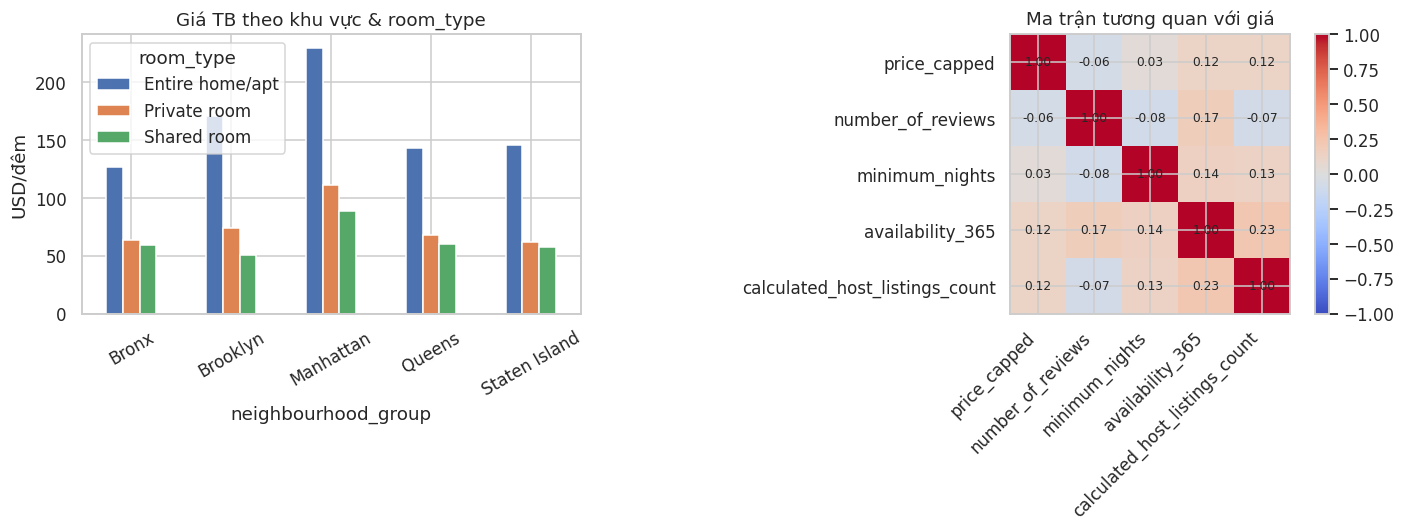

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

pivot1 = rq1_sql.pivot(index='neighbourhood_group', columns='room_type', values='avg_price')
pivot1.plot(kind='bar', ax=axes[0])
axes[0].set_title('Giá TB theo khu vực & room_type')
axes[0].set_ylabel('USD/đêm')
axes[0].tick_params(axis='x', rotation=30)

numeric_cols = ['price_capped', 'number_of_reviews', 'minimum_nights',
                'availability_365', 'calculated_host_listings_count']
corr_matrix = df[numeric_cols].corr()
im = axes[1].imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(numeric_cols))); axes[1].set_xticklabels(numeric_cols, rotation=45, ha='right')
axes[1].set_yticks(range(len(numeric_cols))); axes[1].set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        axes[1].text(j, i, f"{corr_matrix.iloc[i,j]:.2f}", ha='center', va='center', fontsize=8)
axes[1].set_title('Ma trận tương quan với giá')
plt.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

Kết luận: Manhattan có giá trung bình cao nhất ở cả 3 room_type, cách biệt rõ nhất ở "Entire home/apt". Tương quan giữa số lượng review và giá yếu và âm nhẹ (-0.06); giữa số lượng listing của host và giá yếu và dương nhẹ (0.12). Do các hệ số tương quan đều yếu (|r|<0.2)

## RQ2: Các đặc trưng dự đoán giá (khu vực, room_type, minimum_nights, số review, reviews_per_month, số listing của host, availability_365) có phân phối khác nhau thế nào giữa các loại phòng?

In [ ]:
rq2_sql = duckdb.sql("""
    SELECT
        room_type, COUNT(*) AS n_listings,
        ROUND(AVG(minimum_nights), 2) AS avg_min_nights,
        ROUND(AVG(number_of_reviews), 2) AS avg_reviews,
        ROUND(AVG(calculated_host_listings_count), 2) AS avg_host_listings,
        ROUND(AVG(availability_365), 2) AS avg_availability
    FROM df
    GROUP BY room_type
    ORDER BY room_type
""").df()
rq2_sql

,room_type,n_listings,avg_min_nights,avg_reviews,avg_host_listings,avg_availability
0,Entire home/apt,25407,8.51,22.84,10.70,111.93
1,Private room,22319,5.38,24.10,3.23,111.20
2,Shared room,1158,6.43,16.62,4.66,161.87


In [ ]:
rq2_pandas = (
    df.groupby('room_type')
      .agg(n_listings=('room_type','size'),
           avg_min_nights=('minimum_nights','mean'),
           avg_reviews=('number_of_reviews','mean'),
           avg_host_listings=('calculated_host_listings_count','mean'),
           avg_availability=('availability_365','mean'))
      .round(2)
      .reset_index()
)
rq2_pandas

,room_type,n_listings,avg_min_nights,avg_reviews,avg_host_listings,avg_availability
0,Entire home/apt,25407,8.51,22.84,10.70,111.93
1,Private room,22319,5.38,24.10,3.23,111.20
2,Shared room,1158,6.43,16.62,4.66,161.87


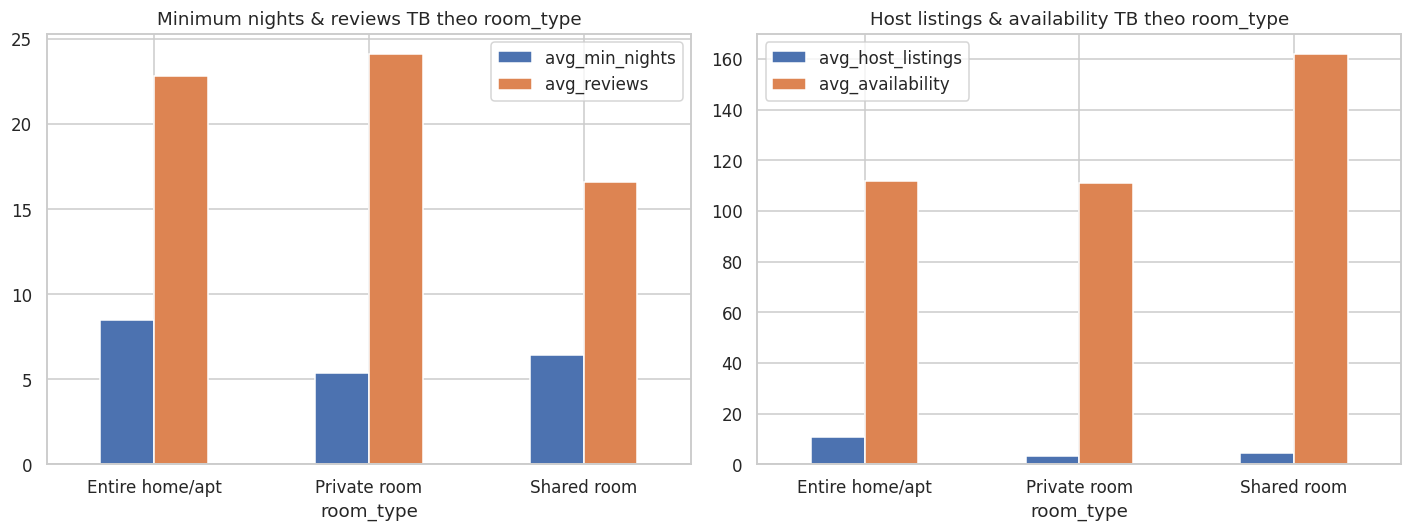

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

rq2_sql.plot(x='room_type', y=['avg_min_nights','avg_reviews'], kind='bar', ax=axes[0])
axes[0].set_title('Minimum nights & reviews TB theo room_type')
axes[0].tick_params(axis='x', rotation=0)

rq2_sql.plot(x='room_type', y=['avg_host_listings','avg_availability'], kind='bar', ax=axes[1])
axes[1].set_title('Host listings & availability TB theo room_type')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

Entire home/apt" có số lượng listing của host trung bình cao hơn hẳn "Private room" và "Shared room"; minimum_nights và availability_365 cũng khác biệt rõ theo từng loại phòng — cho thấy các loại phòng có đặc điểm vận hành khác nhau, không chỉ khác giá.

Giá thực tế của từng listing lệch bao nhiêu so với giá trung bình của nhóm cùng khu vực và loại phòng, và nhóm nào có độ phân tán giá lớn nhất?

In [ ]:
group_baseline_sql = duckdb.sql("""
    SELECT neighbourhood_group, room_type, ROUND(AVG(price_capped),2) AS group_avg_price
    FROM df GROUP BY neighbourhood_group, room_type
""").df()

rq3_sql = duckdb.sql("""
    WITH joined AS (
        SELECT d.*, g.group_avg_price, (d.price_capped - g.group_avg_price) AS deviation
        FROM df d
        JOIN group_baseline_sql g
          ON d.neighbourhood_group = g.neighbourhood_group AND d.room_type = g.room_type
    )
    SELECT neighbourhood_group, room_type, COUNT(*) AS n_listings, group_avg_price,
           ROUND(AVG(ABS(deviation)), 2) AS avg_abs_deviation,
           ROUND(STDDEV_SAMP(deviation), 2) AS std_deviation
    FROM joined
    GROUP BY neighbourhood_group, room_type, group_avg_price
    ORDER BY std_deviation DESC
""").df()
rq3_sql

,neighbourhood_group,room_type,n_listings,group_avg_price,avg_abs_deviation,std_deviation
0,Manhattan,Entire home/apt,13198,229.88,98.57,144.41
1,Staten Island,Entire home/apt,176,146.27,78.87,134.25
2,Brooklyn,Entire home/apt,9558,170.58,70.30,109.32
3,Queens,Shared room,198,60.67,40.98,102.94
4,Bronx,Shared room,60,59.78,38.37,101.68
5,Manhattan,Private room,7982,111.06,50.64,93.47
6,Bronx,Entire home/apt,379,126.98,55.14,90.60
7,Queens,Entire home/apt,2096,143.64,58.81,90.23
8,Manhattan,Shared room,480,88.55,46.32,88.63
9,Bronx,Private room,651,64.28,25.17,56.32


In [ ]:
group_baseline_pandas = df.groupby(['neighbourhood_group','room_type'])['price_capped'] \
                           .mean().round(2).reset_index()
group_baseline_pandas.columns = ['neighbourhood_group','room_type','group_avg_price']

merged = df.merge(group_baseline_pandas, on=['neighbourhood_group','room_type'])
merged['deviation'] = merged['price_capped'] - merged['group_avg_price']

rq3_pandas = (
    merged.groupby(['neighbourhood_group','room_type'])
          .agg(n_listings=('deviation','size'),
               group_avg_price=('group_avg_price','first'),
               avg_abs_deviation=('deviation', lambda x: round(x.abs().mean(), 2)),
               std_deviation=('deviation', lambda x: round(x.std(), 2)))
          .reset_index()
          .sort_values('std_deviation', ascending=False)
)
rq3_pandas

,neighbourhood_group,room_type,n_listings,group_avg_price,avg_abs_deviation,std_deviation
6,Manhattan,Entire home/apt,13198,229.88,98.57,144.41
12,Staten Island,Entire home/apt,176,146.27,78.87,134.25
3,Brooklyn,Entire home/apt,9558,170.58,70.30,109.32
11,Queens,Shared room,198,60.67,40.98,102.94
2,Bronx,Shared room,60,59.78,38.37,101.68
7,Manhattan,Private room,7982,111.06,50.64,93.47
0,Bronx,Entire home/apt,379,126.98,55.14,90.60
9,Queens,Entire home/apt,2096,143.64,58.81,90.23
8,Manhattan,Shared room,480,88.55,46.32,88.63
1,Bronx,Private room,651,64.28,25.17,56.32


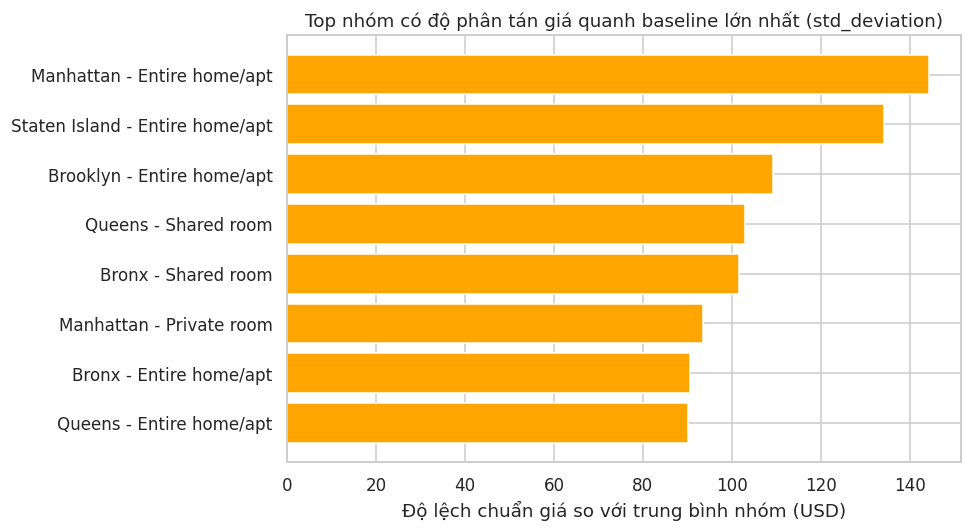

In [ ]:
top_std = rq3_sql.sort_values('std_deviation', ascending=False).head(8).copy()
top_std['label'] = top_std['neighbourhood_group'] + ' - ' + top_std['room_type']

plt.figure(figsize=(9,5))
plt.barh(top_std['label'], top_std['std_deviation'], color='orange')
plt.title('Top nhóm có độ phân tán giá quanh baseline lớn nhất (std_deviation)')
plt.xlabel('Độ lệch chuẩn giá so với trung bình nhóm (USD)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Nhóm "Entire home/apt" ở Manhattan, Brooklyn, Queens có độ phân tán giá lớn nhất so với trung bình nhóm — giá giữa các listing cùng khu vực và loại phòng dao động mạnh, cho thấy sự khác biệt rõ rệt trong cách định giá ngay trong cùng một phân khúc.

In [ ]:
# ================== 1. LOAD & LOẠI PRICE=0 ==================
df = df[df['price'] > 0].reset_index(drop=True)
df["is_unavailable"] = (df["availability_365"] == 0).astype(int)
df["has_review"] = (df["number_of_reviews"] > 0).astype(int)

In [ ]:
df_clean = df.copy()

In [ ]:
# ================== 2. SPLIT: chỉ tách test, phần còn lại dùng CV ==================
price_bins = pd.qcut(df['price'], q=10, labels=False, duplicates='drop')
train_full, test = train_test_split(
    df, test_size=0.15, random_state=42, stratify=price_bins
)
train_full = train_full.reset_index(drop=True)
test = test.reset_index(drop=True)
print(train_full.shape, test.shape)   # ~41.5k / ~7.3k

(41551, 19) (7333, 19)


In [ ]:
# ================== 3. K-FOLD (stratify theo price bin) ==================
strat_bins = pd.qcut(train_full['price'], q=10, labels=False, duplicates='drop')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
SEEDS = [42, 1, 7, 123, 2024]
TIMES_SQUARE = (40.75636, -73.98644)
WALL_STREET = (40.7074, -74.0113)
FIXED_REF_DATE = pd.Timestamp('2019-12-31')

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

In [ ]:
KEYWORDS = ['luxury', 'penthouse', 'loft', 'townhouse', 'duplex', 'cozy', 'bunk', 'hostel']

def bedrooms_from_name(s):
    s = str(s).lower()
    if 'studio' in s:
        return 0
    m = re.search(r'(\d+)\s*(?:br\b|bd\b|bed(?:room)?s?\b)', s)
    if m and int(m.group(1)) < 10:
        return int(m.group(1))
    return np.nan

def add_name_features(d):
    d = d.copy()
    d['n_bed_name'] = d['name'].map(bedrooms_from_name)
    d['n_bed_name_missing'] = d['n_bed_name'].isna().astype(int)
    d['n_bed_name'] = d['n_bed_name'].fillna(-1)  # -1 = "không trích được", để model tự học
    for kw in KEYWORDS:
        d[f'kw_{kw}'] = d['name'].astype(str).str.lower().str.contains(kw, na=False).astype(int)
    return d

NAME_FEATURE_COLS = ['n_bed_name', 'n_bed_name_missing'] + [f'kw_{kw}' for kw in KEYWORDS]



In [ ]:
# ============================================================
# FIX 1 — SENTINEL CỐ ĐỊNH TỪ TRAIN (không tính riêng mỗi partition)
# ============================================================
def preprocess_base(d, p99_price, p99_min_nights, scaler_latlon, fit_scaler, drop_first, date_sentinel):
    d = d.copy()
    d['price_capped'] = d['price'].clip(upper=p99_price)
    d['price_log'] = np.log1p(d['price_capped'])

    d = pd.get_dummies(d, columns=['neighbourhood_group', 'room_type'], prefix=['ng', 'room'], drop_first=drop_first)

    if fit_scaler:
        scaler_latlon.fit(d[['latitude', 'longitude']])
    d[['latitude_scaled', 'longitude_scaled']] = scaler_latlon.transform(d[['latitude', 'longitude']])

    d['number_of_reviews_log'] = np.log1p(d['number_of_reviews'])
    d['reviews_per_month'] = d['reviews_per_month'].fillna(0)
    d['reviews_per_month_log'] = np.log1p(d['reviews_per_month'])
    d['has_review'] = (d['number_of_reviews'] > 0).astype(int)

    # --- sentinel giờ là THAM SỐ cố định (tính từ train, truyền vào cho cả train/val/test) ---
    last_review_dt = pd.to_datetime(d['last_review'])
    d['days_since_last_review'] = (FIXED_REF_DATE - last_review_dt).dt.days
    d['days_since_last_review'] = d['days_since_last_review'].fillna(date_sentinel)

    d['minimum_nights_capped'] = d['minimum_nights'].clip(upper=p99_min_nights)
    d['minimum_nights_log'] = np.log1p(d['minimum_nights_capped'])
    d['is_unavailable'] = (d['availability_365'] == 0).astype(int)
    d['host_listings_log'] = np.log1p(d['calculated_host_listings_count'])

    d['dist_times_square'] = haversine(d['latitude'], d['longitude'], *TIMES_SQUARE)
    d['dist_wall_street'] = haversine(d['latitude'], d['longitude'], *WALL_STREET)

    d = add_name_features(d)
    return d

def prepare_fold_fixed(tr_raw, va_raw, drop_first=False, use_name_features=True):
    p99_price = tr_raw['price'].quantile(0.99)
    p99_min_nights = tr_raw['minimum_nights'].quantile(0.99)
    scaler = StandardScaler()

    # --- sentinel tính 1 LẦN DUY NHẤT từ train, dùng chung cho cả train lẫn val/test ---
    tr_recency = (FIXED_REF_DATE - pd.to_datetime(tr_raw['last_review'])).dt.days
    date_sentinel = tr_recency.max() + 1 if tr_recency.notna().any() else 9999

    tr_p = preprocess_base(tr_raw, p99_price, p99_min_nights, scaler, fit_scaler=True, drop_first=drop_first, date_sentinel=date_sentinel)
    va_p = preprocess_base(va_raw, p99_price, p99_min_nights, scaler, fit_scaler=False, drop_first=drop_first, date_sentinel=date_sentinel)

    te = TargetEncoder(target_type='continuous', smooth='auto', cv=5, random_state=42)
    tr_p['neighbourhood_target_enc'] = te.fit_transform(tr_raw[['neighbourhood']], tr_p['price_log']).ravel()
    va_p['neighbourhood_target_enc'] = te.transform(va_raw[['neighbourhood']]).ravel()

    cols = [c for c in tr_p.columns if c.startswith(('ng_', 'room_'))] + [
        'latitude_scaled', 'longitude_scaled', 'number_of_reviews_log',
        'reviews_per_month_log', 'has_review', 'days_since_last_review',
        'minimum_nights_log', 'availability_365', 'is_unavailable', 'host_listings_log',
        'neighbourhood_target_enc', 'dist_times_square', 'dist_wall_street',
    ]
    if use_name_features:
        cols += NAME_FEATURE_COLS

    X_tr = tr_p.reindex(columns=cols, fill_value=0)
    X_va = va_p.reindex(columns=cols, fill_value=0)
    return X_tr, tr_p['price_log'], X_va, va_p['price_log'], va_raw['price'].values

In [ ]:
def cv_score_for_params(model_fn, use_name_features=True):
    mae_scores, rmse_scores, r2_scores = [], [], []
    for tr_idx, va_idx in skf.split(train_full, strat_bins):
        X_tr, y_tr, X_va, y_va, price_va_raw = prepare_fold_fixed(
            train_full.iloc[tr_idx], train_full.iloc[va_idx], use_name_features=use_name_features
        )
        model = model_fn()
        model.fit(X_tr, y_tr)
        pred_usd = np.maximum(np.expm1(model.predict(X_va)), 0)
        mae_scores.append(mean_absolute_error(price_va_raw, pred_usd))
        rmse_scores.append(np.sqrt(mean_squared_error(price_va_raw, pred_usd)))
        r2_scores.append(r2_score(price_va_raw, pred_usd))
    return {'mae_mean': np.mean(mae_scores), 'mae_std': np.std(mae_scores),
            'rmse_mean': np.mean(rmse_scores), 'rmse_std': np.std(rmse_scores),
            'r2_mean': np.mean(r2_scores), 'r2_std': np.std(r2_scores)}

In [ ]:
def cv_score_for_params_linear_mae(model_fn, use_name_features=True):
    mae_scores, rmse_scores, r2_scores = [], [], []
    for tr_idx, va_idx in skf.split(train_full, strat_bins):
        X_tr, y_tr, X_va, y_va, price_va_raw = prepare_fold_fixed(
            train_full.iloc[tr_idx], train_full.iloc[va_idx], drop_first = True, use_name_features=use_name_features
        )
        model = model_fn()
        model.fit(X_tr, y_tr)
        pred_usd = np.maximum(np.expm1(model.predict(X_va)), 0)
        mae_scores.append(mean_absolute_error(price_va_raw, pred_usd))
        rmse_scores.append(np.sqrt(mean_squared_error(price_va_raw, pred_usd)))
        r2_scores.append(r2_score(price_va_raw, pred_usd))
    return {'mae_mean': np.mean(mae_scores), 'mae_std': np.std(mae_scores),
            'rmse_mean': np.mean(rmse_scores), 'rmse_std': np.std(rmse_scores),
            'r2_mean': np.mean(r2_scores), 'r2_std': np.std(r2_scores)}

Model 1: Linear Regression

In [ ]:
cv_score_for_params_linear_mae(LinearRegression)

{'mae_mean': np.float64(55.86462693831521),
 'mae_std': np.float64(1.9904287079093788),
 'rmse_mean': np.float64(213.52115689324052),
 'rmse_std': np.float64(30.28722191691885),
 'r2_mean': np.float64(0.15382383776188302),
 'r2_std': np.float64(0.034662554431198485)}

Model 2, 3: Ridge và Lasso (biến thể của Linear Regression)

In [ ]:
# ================== GRID SEARCH: alpha là tham số chính ==================
alphas = np.logspace(-4, 2, 25)  # 0.0001 -> 100
alphas_lasso = np.logspace(-6, 1, 30)  # 0.000001 -> 10

def tune_linear(model_class, alphas, max_iter=50000):
    results = []
    t0 = time.time()
    for a in alphas:
        if model_class is Lasso:
            model = Lasso(alpha=a, random_state=42, max_iter=max_iter)
        else:
            model = Ridge(alpha=a)  # Ridge có closed-form, không cần max_iter
        model_fn = lambda m=model: Pipeline([
            ('scaler', StandardScaler()),
            ('model', m)
        ])
        scores = cv_score_for_params_linear_mae(model_fn)
        results.append({'alpha': a, **scores})
        print(f"alpha={a:.6f} MAE={scores['mae_mean']:.2f} | R²={scores['r2_mean']:.4f} | "
              f"({time.time()-t0:.1f}s)")

    return pd.DataFrame(results).sort_values('mae_mean')

In [ ]:
print('--- Tuning Ridge ---')
results_ridge_df = tune_linear(Ridge, alphas)
best_alpha_ridge = results_ridge_df.iloc[0]['alpha']
print('Best alpha Ridge:', best_alpha_ridge)

--- Tuning Ridge ---
alpha=0.000100 MAE=55.87 | R²=0.1539 | (2.4s)
alpha=0.000178 MAE=55.87 | R²=0.1539 | (5.0s)
alpha=0.000316 MAE=55.87 | R²=0.1539 | (8.1s)
alpha=0.000562 MAE=55.87 | R²=0.1539 | (10.3s)
alpha=0.001000 MAE=55.87 | R²=0.1539 | (12.9s)
alpha=0.001778 MAE=55.87 | R²=0.1539 | (15.3s)
alpha=0.003162 MAE=55.87 | R²=0.1539 | (18.6s)
alpha=0.005623 MAE=55.87 | R²=0.1539 | (21.7s)
alpha=0.010000 MAE=55.87 | R²=0.1539 | (24.9s)
alpha=0.017783 MAE=55.87 | R²=0.1539 | (27.4s)
alpha=0.031623 MAE=55.87 | R²=0.1539 | (29.9s)
alpha=0.056234 MAE=55.87 | R²=0.1539 | (32.9s)
alpha=0.100000 MAE=55.87 | R²=0.1539 | (35.2s)
alpha=0.177828 MAE=55.87 | R²=0.1539 | (37.3s)
alpha=0.316228 MAE=55.87 | R²=0.1539 | (39.6s)
alpha=0.562341 MAE=55.87 | R²=0.1539 | (42.7s)
alpha=1.000000 MAE=55.87 | R²=0.1539 | (45.5s)
alpha=1.778279 MAE=55.87 | R²=0.1539 | (48.0s)
alpha=3.162278 MAE=55.87 | R²=0.1539 | (50.0s)
alpha=5.623413 MAE=55.87 | R²=0.1538 | (52.4s)
alpha=10.000000 MAE=55.87 | R²=0.1538 | (5

In [ ]:
print('--- Tuning Lasso (max_iter tăng) ---')
results_lasso_df = tune_linear(Lasso, alphas_lasso, max_iter=50000)
best_alpha_lasso = results_lasso_df.iloc[0]['alpha']
print('Best alpha Lasso:', best_alpha_lasso)

--- Tuning Lasso (max_iter tăng) ---
alpha=0.000001 MAE=55.87 | R²=0.1539 | (2.7s)
alpha=0.000002 MAE=55.87 | R²=0.1539 | (5.3s)
alpha=0.000003 MAE=55.87 | R²=0.1539 | (7.8s)
alpha=0.000005 MAE=55.87 | R²=0.1539 | (11.7s)
alpha=0.000009 MAE=55.87 | R²=0.1539 | (14.3s)
alpha=0.000016 MAE=55.87 | R²=0.1539 | (16.8s)
alpha=0.000028 MAE=55.87 | R²=0.1538 | (19.7s)
alpha=0.000049 MAE=55.87 | R²=0.1538 | (23.3s)
alpha=0.000085 MAE=55.87 | R²=0.1537 | (25.6s)
alpha=0.000149 MAE=55.87 | R²=0.1536 | (28.4s)
alpha=0.000259 MAE=55.87 | R²=0.1535 | (30.7s)
alpha=0.000452 MAE=55.87 | R²=0.1532 | (34.2s)
alpha=0.000788 MAE=55.88 | R²=0.1527 | (38.9s)
alpha=0.001374 MAE=55.89 | R²=0.1519 | (44.0s)
alpha=0.002395 MAE=55.93 | R²=0.1503 | (47.2s)
alpha=0.004175 MAE=56.01 | R²=0.1476 | (49.6s)
alpha=0.007279 MAE=56.24 | R²=0.1424 | (52.0s)
alpha=0.012690 MAE=56.86 | R²=0.1329 | (54.4s)
alpha=0.022122 MAE=58.44 | R²=0.1153 | (56.8s)
alpha=0.038566 MAE=60.20 | R²=0.0963 | (59.8s)
alpha=0.067234 MAE=62.15 |

Model 4: Random Forest

In [ ]:
# ================== GRID SEARCH (nhỏ, chạy đủ nhanh) ==================
param_grid_rf = {
    'n_estimators': [300, 500],
    'max_depth': [8, 10, 12, 15, 18],        # mở thêm phía trên
    'min_samples_leaf': [1, 3, 5, 10, 20],   # mở thêm phía dưới, vẫn giữ 10/20 để so sánh
    'max_features': ['sqrt', 0.5, 0.7],
}

grid = list(ParameterSampler(param_grid_rf, n_iter=25, random_state=42))

results_rf = []
for i, params in enumerate(grid, 1):   # `sampled` = ParameterSampler cũ, giữ nguyên
    model_fn = lambda p=params: RandomForestRegressor(**p, n_jobs=-1, random_state=42)
    scores = cv_score_for_params(model_fn)
    results_rf.append({**params, **scores})
    print(f"[{i}/{len(grid)}] MAE={scores['mae_mean']:.2f} | R2={scores['r2_mean']:.4f}")
results_rf_df = pd.DataFrame(results_rf).sort_values('mae_mean')
best_params_rf = results_rf_df.iloc[0][list(param_grid_rf.keys())].to_dict()
print('Best Random Forests:', best_params_rf)

[1/25] MAE=52.94 | R2=0.1648
[2/25] MAE=55.51 | R2=0.1382
[3/25] MAE=53.88 | R2=0.1560
[4/25] MAE=54.06 | R2=0.1523
[5/25] MAE=53.49 | R2=0.1585
[6/25] MAE=55.38 | R2=0.1385
[7/25] MAE=54.54 | R2=0.1454
[8/25] MAE=52.22 | R2=0.1789
[9/25] MAE=55.42 | R2=0.1353
[10/25] MAE=52.82 | R2=0.1667
[11/25] MAE=52.34 | R2=0.1759
[12/25] MAE=55.26 | R2=0.1413
[13/25] MAE=55.69 | R2=0.1335
[14/25] MAE=57.12 | R2=0.1200
[15/25] MAE=55.51 | R2=0.1382
[16/25] MAE=53.95 | R2=0.1549
[17/25] MAE=52.65 | R2=0.1682
[18/25] MAE=55.42 | R2=0.1354
[19/25] MAE=53.74 | R2=0.1574
[20/25] MAE=52.33 | R2=0.1729
[21/25] MAE=55.33 | R2=0.1413
[22/25] MAE=54.19 | R2=0.1473
[23/25] MAE=55.18 | R2=0.1433
[24/25] MAE=55.03 | R2=0.1387
[25/25] MAE=52.15 | R2=0.1778
Best Random Forests: {'n_estimators': 500, 'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.5}


Model 5: XGBoost

In [ ]:
# ================== RANDOM SEARCH CHO XGBOOST ==================
param_dist_xgb = {
    'n_estimators': [300, 500, 700, 1000],
    'max_depth': [6, 8, 10, 12],          # mở rộng lên, bỏ các depth nhỏ ít tiềm năng
    'learning_rate': [0.01, 0.03, 0.05],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'reg_lambda': [1, 2, 5],
}

sampled = list(ParameterSampler(param_dist_xgb, n_iter=25, random_state=42))
results_xgb = []
for i, params in enumerate(sampled, 1):   # `sampled` = ParameterSampler cũ, giữ nguyên
    model_fn = lambda p=params: XGBRegressor(**p, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
    scores = cv_score_for_params(model_fn)
    results_xgb.append({**params, **scores})
    print(f"[{i}/{len(sampled)}] MAE={scores['mae_mean']:.2f} | R2={scores['r2_mean']:.4f}")
results_xgb_df = pd.DataFrame(results_xgb).sort_values('mae_mean')
best_params_xgb = results_xgb_df.iloc[0][list(param_dist_xgb.keys())].to_dict()
print('Best XGBoost:', best_params_xgb)

[1/25] MAE=51.64 | R2=0.1886
[2/25] MAE=51.47 | R2=0.1948
[3/25] MAE=51.57 | R2=0.1991
[4/25] MAE=52.37 | R2=0.1979
[5/25] MAE=51.35 | R2=0.1997
[6/25] MAE=51.56 | R2=0.1984
[7/25] MAE=52.46 | R2=0.2003
[8/25] MAE=51.55 | R2=0.1953
[9/25] MAE=51.44 | R2=0.1905
[10/25] MAE=51.51 | R2=0.1960
[11/25] MAE=51.30 | R2=0.1956
[12/25] MAE=51.76 | R2=0.1954
[13/25] MAE=52.87 | R2=0.1581
[14/25] MAE=53.30 | R2=0.1564
[15/25] MAE=51.73 | R2=0.1971
[16/25] MAE=51.67 | R2=0.2003
[17/25] MAE=51.51 | R2=0.1902
[18/25] MAE=52.35 | R2=0.1695
[19/25] MAE=52.75 | R2=0.1999
[20/25] MAE=51.66 | R2=0.1848
[21/25] MAE=51.63 | R2=0.1932
[22/25] MAE=52.54 | R2=0.1920
[23/25] MAE=51.44 | R2=0.1936
[24/25] MAE=51.66 | R2=0.1980
[25/25] MAE=52.59 | R2=0.1654
Best XGBoost: {'n_estimators': 1000.0, 'max_depth': 6.0, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.6, 'min_child_weight': 1.0, 'reg_lambda': 5.0}


Model 6: Gradient Boosting

In [ ]:
# ================== RANDOM SEARCH CHO GRADIENT BOOSTING ==================
param_dist_gbm = {
    'n_estimators': [100, 150, 200, 300],
    'max_depth': [3, 4, 5, 6, 8],      # mở rộng lên, theo đúng pattern RF/XGBoost
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'min_samples_leaf': [5, 10, 20, 50],  # thêm 5 để không bỏ sót vùng ít regularize hơn
}

sampled_gbm = list(ParameterSampler(param_dist_gbm, n_iter=25, random_state=42))

results_gbm = []
for i, params in enumerate(sampled_gbm, 1):   # `sampled` = ParameterSampler cũ, giữ nguyên
    model_fn = lambda p=params: GradientBoostingRegressor(**p, random_state=42)
    scores = cv_score_for_params(model_fn)
    results_gbm.append({**params, **scores})
    print(f"[{i}/{len(sampled_gbm)}] MAE={scores['mae_mean']:.2f} | R2={scores['r2_mean']:.4f}")
results_gbm_df = pd.DataFrame(results_gbm).sort_values('mae_mean')
best_params_gbm = results_gbm_df.iloc[0][list(param_dist_gbm.keys())].to_dict()
print('Best Gradient Boosting:', best_params_gbm)

[1/25] MAE=52.13 | R2=0.1828
[2/25] MAE=52.24 | R2=0.1794
[3/25] MAE=55.14 | R2=0.1373
[4/25] MAE=52.10 | R2=0.1824
[5/25] MAE=51.80 | R2=0.1967
[6/25] MAE=54.37 | R2=0.1522
[7/25] MAE=53.10 | R2=0.1614
[8/25] MAE=53.51 | R2=0.1627
[9/25] MAE=63.05 | R2=0.0703
[10/25] MAE=52.23 | R2=0.1806
[11/25] MAE=53.57 | R2=0.1601
[12/25] MAE=58.19 | R2=0.1074
[13/25] MAE=60.43 | R2=0.0937
[14/25] MAE=52.01 | R2=0.1880
[15/25] MAE=52.63 | R2=0.1761
[16/25] MAE=54.66 | R2=0.1444
[17/25] MAE=59.74 | R2=0.0947
[18/25] MAE=52.11 | R2=0.1802
[19/25] MAE=52.91 | R2=0.1715
[20/25] MAE=52.11 | R2=0.1839
[21/25] MAE=51.90 | R2=0.1873
[22/25] MAE=62.10 | R2=0.0780
[23/25] MAE=53.66 | R2=0.1643
[24/25] MAE=53.25 | R2=0.1655
[25/25] MAE=54.23 | R2=0.1553
Best Gradient Boosting: {'n_estimators': 300.0, 'max_depth': 8.0, 'learning_rate': 0.1, 'subsample': 1.0, 'min_samples_leaf': 5.0}


Research Question 2:

In [ ]:
# ================== 1. CHUẨN BỊ DỮ LIỆU (1 LẦN DUY NHẤT CHO TEST) ==================
# Tree-based: one-hot đầy đủ (drop_first=False)
X_full_tree, y_full, X_te_tree, y_te, price_te_raw = prepare_fold_fixed(
    train_full, test, drop_first=False
)
# Linear: one-hot drop_first=True (tránh multicollinearity)
X_full_lin, y_full_lin, X_te_lin, y_te_lin, _ = prepare_fold_fixed(
    train_full, test, drop_first=True
)

actual_usd = price_te_raw  # giống nhau giữa 2 bộ, chỉ lấy 1 lần

In [ ]:
# ================== 2. BEST PARAMS ĐÃ TUNE TỪ CÁC BƯỚC TRƯỚC ==================
# (thay bằng giá trị thật bạn đã in ra ở từng bước tuning)
best_params_rf   = {'n_estimators': 500, 'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.5}
# từ bước tune RF: {'n_estimators': 500, 'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 0.5}
best_params_xgb  = {'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.6, 'min_child_weight': 1.0, 'reg_lambda': 5.0}
# từ bước tune XGBoost: {'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.6, 'min_child_weight': 1.0, 'reg_lambda': 5.0}
best_params_gbm  = {'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.1, 'subsample': 1.0, 'min_samples_leaf': 5}
# từ bước tune GBM: {'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.1, 'subsample': 1.0, 'min_samples_leaf': 5, 'max_features': None}

In [ ]:
# ============================================================
# FIX 2 — CHỌN FINAL MODEL THEO CV MAE, KHÔNG PHẢI MEAN TEST MAE
# ============================================================
LINEAR_MODELS = {'Linear Regression', 'Ridge', 'Lasso'}
best_alpha_lasso = 0.0001  # nằm giữa vùng phẳng (1e-6 đến ~5e-4), tránh chọn đúng điểm biên
best_alpha_ridge = 1.0     # không đổi — đường cong vẫn phẳng hoàn toàn như trước

def build_model_fn(name):
    if name == 'Linear Regression':
        return lambda: Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
    if name == 'Ridge':
        return lambda: Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=best_alpha_ridge))])
    if name == 'Lasso':
        return lambda: Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=best_alpha_lasso, random_state=42, max_iter=50000))])
    if name == 'Random Forest':
        return lambda: RandomForestRegressor(**best_params_rf, n_jobs=-1, random_state=42)
    if name == 'XGBoost':
        return lambda: XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
    if name == 'Gradient Boosting':
        return lambda: GradientBoostingRegressor(**best_params_gbm, random_state=42)

def cv_mae_for_model(model_name, train_full, skf, strat_bins):
    """CV MAE trên TRAIN (không đụng test) — dùng để CHỌN model, không phải tiêu chí báo cáo cuối."""
    drop_first = model_name in LINEAR_MODELS
    mae_scores = []
    for tr_idx, va_idx in skf.split(train_full, strat_bins):
        X_tr, y_tr, X_va, y_va, price_va_raw = prepare_fold_fixed(
            train_full.iloc[tr_idx], train_full.iloc[va_idx], drop_first=drop_first, use_name_features=True
        )
        model = build_model_fn(model_name)()
        model.fit(X_tr, y_tr)
        pred_raw = np.maximum(np.expm1(model.predict(X_va)), 0)
        mae_scores.append(mean_absolute_error(price_va_raw, pred_raw))
    return np.mean(mae_scores), np.std(mae_scores)

In [ ]:
# ============================================================
# 1. BẢNG 6 MODEL — 5 SEED (bảng chính thức cho RQ2)
# ============================================================
def evaluate_once(model, X_tr, y_tr, X_te, price_te_raw, p99_price_train):
    model.fit(X_tr, y_tr)
    pred_log = model.predict(X_te)
    pred_raw = np.maximum(np.expm1(pred_log), 0)
    mae = mean_absolute_error(price_te_raw, pred_raw)
    rmse = np.sqrt(mean_squared_error(price_te_raw, pred_raw))
    r2_log = r2_score(np.log1p(price_te_raw), pred_log)
    r2_raw = r2_score(price_te_raw, pred_raw)
    actual_capped = np.minimum(price_te_raw, p99_price_train)
    pred_capped = np.minimum(pred_raw, p99_price_train)
    r2_capped = r2_score(actual_capped, pred_capped)
    return mae, rmse, r2_log, r2_capped, r2_raw

all_results = []
for seed in SEEDS:
    price_bins = pd.qcut(df_clean['price'], q=10, labels=False, duplicates='drop')
    train_full, test = train_test_split(df_clean, test_size=0.15, random_state=seed, stratify=price_bins)
    p99_price_train = train_full['price'].quantile(0.99)

    for model_name in ['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'XGBoost', 'Gradient Boosting']:
        drop_first = model_name in LINEAR_MODELS
        X_tr, y_tr, X_te, y_te, price_te_raw = prepare_fold_fixed(train_full, test, drop_first=drop_first, use_name_features=True)
        model = build_model_fn(model_name)()
        mae, rmse, r2_log, r2_capped, r2_raw = evaluate_once(model, X_tr, y_tr, X_te, price_te_raw, p99_price_train)
        all_results.append({'model': model_name, 'seed': seed, 'mae': mae, 'rmse': rmse,
                             'r2_log': r2_log, 'r2_capped': r2_capped, 'r2_raw': r2_raw})
    print(f'Xong seed {seed}')

all_results_df = pd.DataFrame(all_results)
summary = all_results_df.groupby('model')[['mae','rmse','r2_log','r2_capped','r2_raw']].agg(['mean','std'])
summary = summary.sort_values(('mae','mean'))
print(summary)

Xong seed 42
Xong seed 1
Xong seed 7
Xong seed 123
Xong seed 2024
                         mae                  rmse               r2_log  \
                        mean       std        mean        std      mean   
model                                                                     
XGBoost            51.553516  1.556301  224.162899  25.001605  0.659917   
Gradient Boosting  51.855397  1.663953  224.258266  24.691260  0.654386   
Random Forest      52.183632  1.580161  225.777529  24.710709  0.647229   
Linear Regression  56.310042  1.416108  228.329789  25.075641  0.597141   
Ridge              56.310081  1.416105  228.330219  25.075648  0.597141   
Lasso              56.310438  1.416391  228.344505  25.078480  0.597137   

                            r2_capped              r2_raw            
                        std      mean       std      mean       std  
model                                                                
XGBoost            0.005825  0.523072  0.008612 

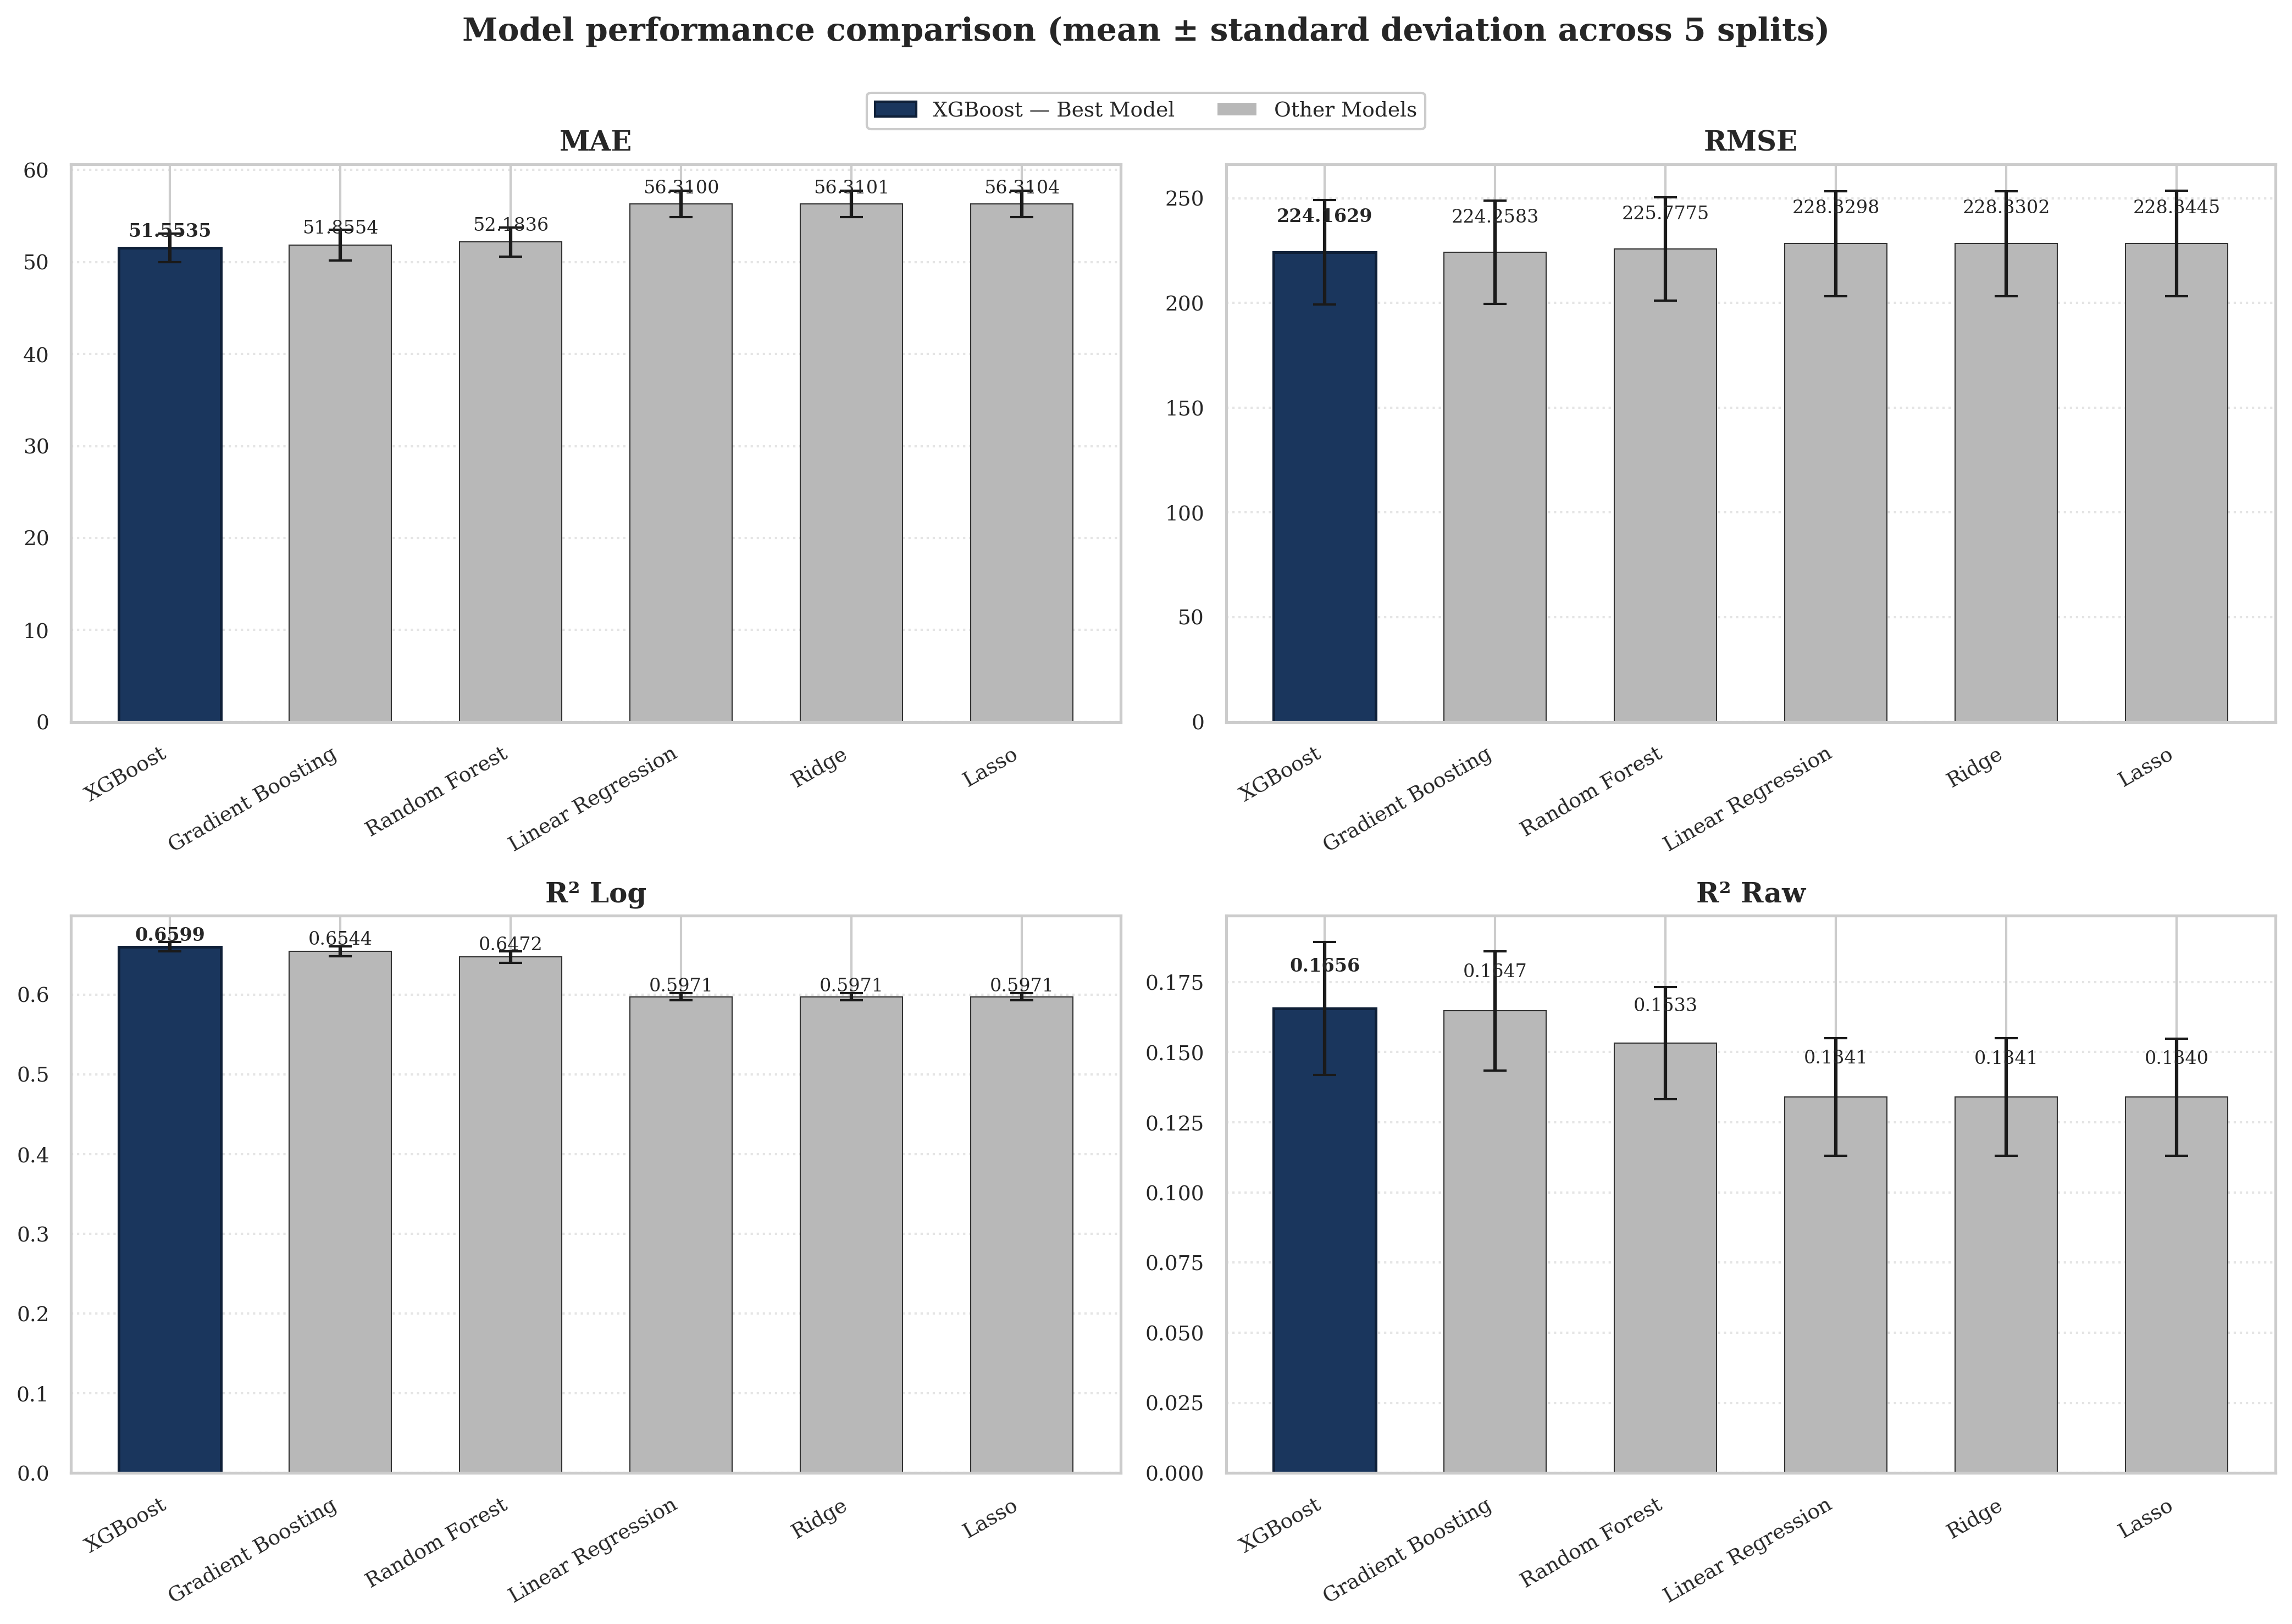

=== Bảng tóm tắt hiệu năng ===


,model,mae_mean,rmse_mean,r2_log_mean,r2_raw_mean
0,XGBoost,51.5535,224.1629,0.6599,0.1656
1,Gradient Boosting,51.8554,224.2583,0.6544,0.1647
2,Random Forest,52.1836,225.7775,0.6472,0.1533
3,Linear Regression,56.3100,228.3298,0.5971,0.1341
4,Ridge,56.3101,228.3302,0.5971,0.1341
5,Lasso,56.3104,228.3445,0.5971,0.1340


In [ ]:
# === Tính summary từ dữ liệu gốc ===
summary = all_results_df.groupby('model')[['mae','rmse','r2_log','r2_capped','r2_raw']].agg(['mean','std'])
summary = summary.sort_values(('mae','mean'))  # Sắp xếp theo MAE tăng dần
summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
summary = summary.reset_index()

# Định nghĩa thứ tự hiển thị và màu sắc
model_order = ['XGBoost', 'Gradient Boosting', 'Random Forest',
               'Linear Regression', 'Ridge', 'Lasso']
summary['model'] = pd.Categorical(summary['model'], categories=model_order, ordered=True)
summary = summary.sort_values('model')

# Màu: XGBoost nổi bật, các model khác cùng màu xám
colors = ['#1a365d' if m == 'XGBoost' else '#b8b8b8' for m in summary['model']]

# === Cấu hình biểu đồ ===
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
})

# Tạo figure với 4 chỉ số
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
metrics = [
    ('mae_mean', 'mae_std', 'MAE'),
    ('rmse_mean', 'rmse_std', 'RMSE'),
    ('r2_log_mean', 'r2_log_std', 'R² Log'),
    ('r2_raw_mean', 'r2_raw_std', 'R² Raw'),
]

x = np.arange(len(summary))
width = 0.6

for idx, (mean_col, std_col, title) in enumerate(metrics):
    ax = axes[idx]
    bars = ax.bar(x, summary[mean_col], width,
                  yerr=summary[std_col], capsize=5,
                  color=colors, edgecolor='#333333', linewidth=0.5)

    # Đánh dấu XGBoost rõ hơn
    bars[0].set_edgecolor('#0f2038')
    bars[0].set_linewidth(1.2)

    ax.set_title(title, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(summary['model'], rotation=30, ha='right')
    ax.grid(axis='y', linestyle=':', alpha=0.5)

    # In giá trị trên cột
    for i, v in enumerate(summary[mean_col]):
        ax.text(i, v + (summary[std_col][i] * 0.5), f'{v:.4f}',
                ha='center', va='bottom', fontsize=8,
                fontweight='bold' if summary['model'][i] == 'XGBoost' else 'normal')

# Thêm ghi chú
fig.suptitle('Model performance comparison (mean ± standard deviation across 5 splits)',
             fontsize=14, fontweight='bold', y=0.98)
legend_elements = [Patch(facecolor='#1a365d', edgecolor='#0f2038', label='XGBoost — Best Model'),
                   Patch(facecolor='#b8b8b8', label='Other Models')]
fig.legend(handles=legend_elements, loc='upper center', ncol=2,
           bbox_to_anchor=(0.5, 0.94), framealpha=1.0)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# In bảng tóm tắt số liệu
print("=== Bảng tóm tắt hiệu năng ===")
display(summary[['model', 'mae_mean', 'rmse_mean', 'r2_log_mean', 'r2_raw_mean']].round(4))

In [ ]:

# ============================================================
# RQ2 — PAIRED MODEL COMPARISON ACROSS 5 SEEDS
# XGBoost vs Gradient Boosting
# XGBoost vs Random Forest
#
# Metric chính: MAE trên thang giá gốc (USD)
# Không train lại mô hình
# ============================================================

# ---------- 1. Cấu hình cặp so sánh ----------
pairs = [
    ('XGBoost', 'Gradient Boosting'),
    ('XGBoost', 'Random Forest')
]

# Kiểm tra dữ liệu
required_cols = {'model', 'seed', 'mae'}
missing_cols = required_cols - set(all_results_df.columns)

if missing_cols:
    raise ValueError(f"Thiếu các cột: {missing_cols}")

# Chỉ giữ các mô hình cần so sánh
models_needed = {'XGBoost', 'Gradient Boosting', 'Random Forest'}
df_pair = all_results_df[
    all_results_df['model'].isin(models_needed)
].copy()

# Mỗi model-seed phải có đúng một dòng
if df_pair.duplicated(['model', 'seed']).any():
    raise ValueError("Có nhiều dòng cho cùng một model và seed.")

# ---------- 2. Chuyển bảng sang dạng một dòng mỗi seed ----------
mae_wide = df_pair.pivot(
    index='seed',
    columns='model',
    values='mae'
)

expected_models = ['XGBoost', 'Gradient Boosting', 'Random Forest']
missing_models = set(expected_models) - set(mae_wide.columns)

if missing_models:
    raise ValueError(f"Thiếu kết quả cho mô hình: {missing_models}")

if mae_wide[expected_models].isna().any().any():
    raise ValueError("Có MAE bị thiếu ở một hoặc nhiều seed.")

mae_wide = mae_wide.sort_index()

print("=== MAE theo từng seed (USD) ===")
print(mae_wide.round(2).to_string())

# ---------- 3. Tính chênh lệch theo từng seed ----------
pair_rows = []

for winner_model, competitor_model in pairs:
    # Positive => XGBoost has lower MAE
    # Negative => competitor has lower MAE
    delta = (
        mae_wide[competitor_model] - mae_wide[winner_model]
    )

    # Phần trăm MAE giảm so với mô hình đối chiếu
    improvement_pct = (
        delta / mae_wide[competitor_model] * 100
    )

    for seed in mae_wide.index:
        pair_rows.append({
            'comparison': f'{winner_model} vs {competitor_model}',
            'seed': seed,
            'mae_xgboost': mae_wide.loc[seed, 'XGBoost'],
            'mae_competitor': mae_wide.loc[seed, competitor_model],
            'delta_mae_comp_minus_xgb': delta.loc[seed],
            'xgb_mae_improvement_pct': improvement_pct.loc[seed]
        })

pair_results_df = pd.DataFrame(pair_rows)

print("\n=== CHÊNH LỆCH MAE THEO TỪNG SEED ===")
print(
    pair_results_df.to_string(
        index=False,
        formatters={
            'mae_xgboost': '{:.2f}'.format,
            'mae_competitor': '{:.2f}'.format,
            'delta_mae_comp_minus_xgb': '{:+.2f}'.format,
            'xgb_mae_improvement_pct': '{:+.2f}%'.format
        }
    )
)


=== MAE theo từng seed (USD) ===
model  Gradient Boosting  Random Forest  XGBoost
seed                                            
1                  50.19          50.75    49.96
7                  50.62          51.11    50.45
42                 54.42          54.76    53.93
123                52.27          52.43    52.07
2024               51.77          51.88    51.36

=== CHÊNH LỆCH MAE THEO TỪNG SEED ===
                  comparison  seed mae_xgboost mae_competitor delta_mae_comp_minus_xgb xgb_mae_improvement_pct
XGBoost vs Gradient Boosting     1       49.96          50.19                    +0.23                  +0.45%
XGBoost vs Gradient Boosting     7       50.45          50.62                    +0.17                  +0.34%
XGBoost vs Gradient Boosting    42       53.93          54.42                    +0.50                  +0.91%
XGBoost vs Gradient Boosting   123       52.07          52.27                    +0.20                  +0.39%
XGBoost vs Gradient Boosting  

In [ ]:
# ---------- 4. Tổng hợp qua 5 seed ----------
summary_rows = []

for winner_model, competitor_model in pairs:
    sub = pair_results_df[
        pair_results_df['comparison']
        == f'{winner_model} vs {competitor_model}'
    ]

    delta = sub['delta_mae_comp_minus_xgb']
    improvement = sub['xgb_mae_improvement_pct']

    summary_rows.append({
        'comparison': f'{winner_model} vs {competitor_model}',
        'n_seeds': len(sub),
        'mean_mae_xgb': sub['mae_xgboost'].mean(),
        'mean_mae_competitor': sub['mae_competitor'].mean(),
        'mean_delta_mae': delta.mean(),
        'std_delta_mae': delta.std(ddof=1),
        'mean_improvement_pct': improvement.mean(),
        'seeds_xgb_better': int((delta > 0).sum()),
        'seeds_tied': int((delta == 0).sum()),
        'seeds_xgb_worse': int((delta < 0).sum())
    })

pair_summary_df = pd.DataFrame(summary_rows)

print("\n=== SUMMARY: PAIRED MAE COMPARISON ===")
print(
    pair_summary_df.to_string(
        index=False,
        formatters={
            'mean_mae_xgb': '{:.2f}'.format,
            'mean_mae_competitor': '{:.2f}'.format,
            'mean_delta_mae': '{:+.2f}'.format,
            'std_delta_mae': '{:.2f}'.format,
            'mean_improvement_pct': '{:+.2f}%'.format
        }
    )
)


=== SUMMARY: PAIRED MAE COMPARISON ===
                  comparison  n_seeds mean_mae_xgb mean_mae_competitor mean_delta_mae std_delta_mae mean_improvement_pct  seeds_xgb_better  seeds_tied  seeds_xgb_worse
XGBoost vs Gradient Boosting        5        51.55               51.86          +0.30          0.14               +0.58%                 5           0                0
    XGBoost vs Random Forest        5        51.55               52.18          +0.63          0.19               +1.21%                 5           0                0


In [ ]:
# ============================================================
# 2. OVERFITTING DIAGNOSTIC — dùng seed=42 làm đại diện (đủ cho mục đích diễn giải)
# ============================================================
seed = 42
price_bins = pd.qcut(df_clean['price'], q=10, labels=False, duplicates='drop')
train_full, test = train_test_split(df_clean, test_size=0.15, random_state=seed, stratify=price_bins)

overfit_rows = []
for model_name in ['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'XGBoost', 'Gradient Boosting']:
    drop_first = model_name in LINEAR_MODELS
    X_tr, y_tr, X_te, y_te, price_te_raw = prepare_fold_fixed(train_full, test, drop_first=drop_first, use_name_features=True)
    model = build_model_fn(model_name)()
    model.fit(X_tr, y_tr)

    pred_train_raw = np.maximum(np.expm1(model.predict(X_tr)), 0)
    pred_test_raw = np.maximum(np.expm1(model.predict(X_te)), 0)
    train_r2 = r2_score(train_full['price'].values, pred_train_raw)
    test_r2 = r2_score(price_te_raw, pred_test_raw)
    overfit_rows.append({'model': model_name, 'train_r2': train_r2, 'test_r2': test_r2, 'gap': train_r2 - test_r2})

print(pd.DataFrame(overfit_rows).sort_values('gap', ascending=False))

               model  train_r2   test_r2       gap
3      Random Forest  0.319129  0.125572  0.193557
5  Gradient Boosting  0.296222  0.134911  0.161311
4            XGBoost  0.237673  0.134503  0.103170
0  Linear Regression  0.146639  0.106493  0.040146
1              Ridge  0.146635  0.106490  0.040145
2              Lasso  0.146512  0.106375  0.040137


In [ ]:
# ============================================================
# CHUẨN BỊ: 5 split cố định (đúng 5 seed đã dùng cho Bảng 8), fit XGBoost với
# best_params_xgb HIỆN TẠI (không tune lại) cho từng split
# ============================================================
SEEDS = [42, 1, 7, 123, 2024]
split_models = {}   # seed -> (model, X_te, test_df, pred_log_te, price_te_raw)

for seed in SEEDS:
    price_bins = pd.qcut(df_clean['price'], q=10, labels=False, duplicates='drop')
    train_full, test = train_test_split(df_clean, test_size=0.15, random_state=seed, stratify=price_bins)
    X_tr, y_tr, X_te, y_te, price_te_raw = prepare_fold_fixed(train_full, test, drop_first=False, use_name_features=True)

    model = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=seed)
    model.fit(X_tr, y_tr)
    pred_log_te = model.predict(X_te)

    split_models[seed] = {
        'model': model, 'train_full': train_full, 'test': test,
        'pred_log': pred_log_te, 'price_te_raw': price_te_raw,
    }
    print(f'Xong seed {seed}')

Xong seed 42
Xong seed 1
Xong seed 7
Xong seed 123
Xong seed 2024


In [ ]:
# Smearing factor — tính từ out-of-fold residual trên TRAIN của split đầu tiên (seed=42),
# dùng xuyên suốt cho cả Calibration lẫn optional mean-comparison
seed0 = SEEDS[0]
train_full0 = split_models[seed0]['train_full']
price_bins0 = pd.qcut(train_full0['price'], q=10, labels=False, duplicates='drop')
skf0 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

residuals_oof = []
for tr_idx, va_idx in skf0.split(train_full0, price_bins0):
    X_tr_f, y_tr_f, X_va_f, y_va_f, _ = prepare_fold_fixed(train_full0.iloc[tr_idx], train_full0.iloc[va_idx], use_name_features=True)
    m = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
    m.fit(X_tr_f, y_tr_f)
    residuals_oof.append(y_va_f.values - m.predict(X_va_f))
residuals_oof = np.concatenate(residuals_oof)
smearing_factor = np.mean(np.exp(residuals_oof))
print(f'\nSmearing factor S = {smearing_factor:.4f}')


Smearing factor S = 1.0872


In [ ]:
# ============================================================
# VIỆC 5 — GROUPKFOLD vs STRATIFIEDKFOLD, dùng đúng best_params_xgb hiện tại
# ============================================================
mae_strat = []
for tr_idx, va_idx in skf0.split(train_full0, price_bins0):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = prepare_fold_fixed(train_full0.iloc[tr_idx], train_full0.iloc[va_idx], use_name_features=True)
    m = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
    m.fit(X_tr_f, y_tr_f)
    pred_f = np.maximum(np.expm1(m.predict(X_va_f)), 0)
    mae_strat.append(mean_absolute_error(price_va_raw_f, pred_f))

gkf = GroupKFold(n_splits=5)
mae_group = []
for tr_idx, va_idx in gkf.split(train_full0, groups=train_full0['host_id']):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = prepare_fold_fixed(train_full0.iloc[tr_idx], train_full0.iloc[va_idx], use_name_features=True)
    m = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
    m.fit(X_tr_f, y_tr_f)
    pred_f = np.maximum(np.expm1(m.predict(X_va_f)), 0)
    mae_group.append(mean_absolute_error(price_va_raw_f, pred_f))

print('\n=== VIỆC 5: StratifiedKFold vs GroupKFold (host_id), cùng best_params_xgb ===')
print(f'StratifiedKFold MAE: {np.mean(mae_strat):.2f} ± {np.std(mae_strat):.2f}')
print(f'GroupKFold MAE:      {np.mean(mae_group):.2f} ± {np.std(mae_group):.2f}')


=== VIỆC 5: StratifiedKFold vs GroupKFold (host_id), cùng best_params_xgb ===
StratifiedKFold MAE: 51.30 ± 1.71
GroupKFold MAE:      53.99 ± 3.79


In [ ]:

# ============================================================
# GROUPKFOLD vs STRATIFIEDKFOLD — RANDOM FOREST
# Dùng đúng best_params_rf hiện tại
# ============================================================

# ----- StratifiedKFold -----
mae_strat_rf = []

for tr_idx, va_idx in skf0.split(train_full0, price_bins0):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = (
        prepare_fold_fixed(
            train_full0.iloc[tr_idx],
            train_full0.iloc[va_idx],
            use_name_features=True
        )
    )

    model = RandomForestRegressor(
        **best_params_rf,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_tr_f, y_tr_f)

    pred_f = np.maximum(
        np.expm1(model.predict(X_va_f)), 0
    )

    mae_strat_rf.append(
        mean_absolute_error(price_va_raw_f, pred_f)
    )


# ----- GroupKFold theo host_id -----
gkf_rf = GroupKFold(n_splits=5)
mae_group_rf = []

for tr_idx, va_idx in gkf_rf.split(
    train_full0,
    groups=train_full0['host_id']
):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = (
        prepare_fold_fixed(
            train_full0.iloc[tr_idx],
            train_full0.iloc[va_idx],
            use_name_features=True
        )
    )

    model = RandomForestRegressor(
        **best_params_rf,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_tr_f, y_tr_f)

    pred_f = np.maximum(
        np.expm1(model.predict(X_va_f)), 0
    )

    mae_group_rf.append(
        mean_absolute_error(price_va_raw_f, pred_f)
    )


# ----- Kết quả -----
print('\n=== RANDOM FOREST: StratifiedKFold vs GroupKFold ===')
print(
    f'StratifiedKFold MAE: '
    f'{np.mean(mae_strat_rf):.2f} ± {np.std(mae_strat_rf):.2f}'
)
print(
    f'GroupKFold MAE:      '
    f'{np.mean(mae_group_rf):.2f} ± {np.std(mae_group_rf):.2f}'
)



=== RANDOM FOREST: StratifiedKFold vs GroupKFold ===
StratifiedKFold MAE: 52.15 ± 1.72
GroupKFold MAE:      54.63 ± 3.45


In [ ]:

# ============================================================
# GROUPKFOLD vs STRATIFIEDKFOLD — GRADIENT BOOSTING
# Dùng đúng best_params_gbm hiện tại
# ============================================================

# ----- StratifiedKFold -----
mae_strat_gbm = []

for tr_idx, va_idx in skf0.split(train_full0, price_bins0):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = (
        prepare_fold_fixed(
            train_full0.iloc[tr_idx],
            train_full0.iloc[va_idx],
            use_name_features=True
        )
    )

    model = GradientBoostingRegressor(
        **best_params_gbm,
        random_state=42
    )

    model.fit(X_tr_f, y_tr_f)

    pred_f = np.maximum(
        np.expm1(model.predict(X_va_f)), 0
    )

    mae_strat_gbm.append(
        mean_absolute_error(price_va_raw_f, pred_f)
    )


# ----- GroupKFold theo host_id -----
gkf_gbm = GroupKFold(n_splits=5)
mae_group_gbm = []

for tr_idx, va_idx in gkf_gbm.split(
    train_full0,
    groups=train_full0['host_id']
):
    X_tr_f, y_tr_f, X_va_f, y_va_f, price_va_raw_f = (
        prepare_fold_fixed(
            train_full0.iloc[tr_idx],
            train_full0.iloc[va_idx],
            use_name_features=True
        )
    )

    model = GradientBoostingRegressor(
        **best_params_gbm,
        random_state=42
    )

    model.fit(X_tr_f, y_tr_f)

    pred_f = np.maximum(
        np.expm1(model.predict(X_va_f)), 0
    )

    mae_group_gbm.append(
        mean_absolute_error(price_va_raw_f, pred_f)
    )


# ----- Kết quả -----
print('\n=== GRADIENT BOOSTING: StratifiedKFold vs GroupKFold ===')
print(
    f'StratifiedKFold MAE: '
    f'{np.mean(mae_strat_gbm):.2f} ± {np.std(mae_strat_gbm):.2f}'
)
print(
    f'GroupKFold MAE:      '
    f'{np.mean(mae_group_gbm):.2f} ± {np.std(mae_group_gbm):.2f}'
)



=== GRADIENT BOOSTING: StratifiedKFold vs GroupKFold ===
StratifiedKFold MAE: 51.81 ± 1.66
GroupKFold MAE:      55.09 ± 3.75


In [ ]:

# ============================================================
# SUMMARY: GROUPKFOLD vs STRATIFIEDKFOLD — 3 TREE ENSEMBLES
# ============================================================

groupkfold_summary = pd.DataFrame([
    {
        'Model': 'Random Forest',
        'StratifiedKFold_MAE_mean': np.mean(mae_strat_rf),
        'StratifiedKFold_MAE_sd': np.std(mae_strat_rf),
        'GroupKFold_MAE_mean': np.mean(mae_group_rf),
        'GroupKFold_MAE_sd': np.std(mae_group_rf),
    },
    {
        'Model': 'XGBoost',
        'StratifiedKFold_MAE_mean': np.mean(mae_strat),
        'StratifiedKFold_MAE_sd': np.std(mae_strat),
        'GroupKFold_MAE_mean': np.mean(mae_group),
        'GroupKFold_MAE_sd': np.std(mae_group),
    },
    {
        'Model': 'Gradient Boosting',
        'StratifiedKFold_MAE_mean': np.mean(mae_strat_gbm),
        'StratifiedKFold_MAE_sd': np.std(mae_strat_gbm),
        'GroupKFold_MAE_mean': np.mean(mae_group_gbm),
        'GroupKFold_MAE_sd': np.std(mae_group_gbm),
    }
])

groupkfold_summary['MAE_change'] = (
    groupkfold_summary['GroupKFold_MAE_mean']
    - groupkfold_summary['StratifiedKFold_MAE_mean']
)

print(groupkfold_summary.round(2).to_string(index=False))


            Model  StratifiedKFold_MAE_mean  StratifiedKFold_MAE_sd  GroupKFold_MAE_mean  GroupKFold_MAE_sd  MAE_change
    Random Forest                     52.15                    1.72                54.63               3.45        2.47
          XGBoost                     51.30                    1.71                53.99               3.79        2.70
Gradient Boosting                     51.81                    1.66                55.09               3.75        3.29


Research Question 3:

In [ ]:
# Dùng 1 split cố định (seed đầu tiên trong SEEDS) chỉ để lấy train_full cho bước CV-chọn-model này —
# test của split này KHÔNG được xem ở bước này, chỉ dùng train_full để chạy CV nội bộ.
price_bins_sel = pd.qcut(df_clean['price'], q=10, labels=False, duplicates='drop')
train_full_sel, _ = train_test_split(df_clean, test_size=0.15, random_state=SEEDS[0], stratify=price_bins_sel)
strat_bins_sel = pd.qcut(train_full_sel['price'], q=10, labels=False, duplicates='drop')
skf_sel = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_selection_results = []
for model_name in ['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'XGBoost', 'Gradient Boosting']:
    mean_mae, std_mae = cv_mae_for_model(model_name, train_full_sel, skf_sel, strat_bins_sel)
    cv_selection_results.append({'model': model_name, 'cv_mae_mean': mean_mae, 'cv_mae_std': std_mae})
    print(f'{model_name}: CV MAE = {mean_mae:.2f} ± {std_mae:.2f}')

cv_selection_df = pd.DataFrame(cv_selection_results).sort_values('cv_mae_mean')
FINAL_MODEL_NAME = cv_selection_df.iloc[0]['model']
print(f'\n=> Final model được chọn theo CV MAE (KHÔNG dùng test): {FINAL_MODEL_NAME}')
print(cv_selection_df.to_string(index=False))

Linear Regression: CV MAE = 55.86 ± 1.99
Ridge: CV MAE = 55.86 ± 1.99
Lasso: CV MAE = 55.87 ± 1.99
Random Forest: CV MAE = 52.15 ± 1.72
XGBoost: CV MAE = 51.30 ± 1.71
Gradient Boosting: CV MAE = 51.81 ± 1.66

=> Final model được chọn theo CV MAE (KHÔNG dùng test): XGBoost
            model  cv_mae_mean  cv_mae_std
          XGBoost    51.295209    1.706885
Gradient Boosting    51.805560    1.655918
    Random Forest    52.151984    1.720689
Linear Regression    55.864627    1.990429
            Ridge    55.864710    1.990475
            Lasso    55.865339    1.991588


In [ ]:
# ============================================================
# B. TRAIN MODEL CUỐI CÙNG (dùng cho RQ2 + RQ3)
# ============================================================
train_full, test = split_models[42]['train_full'], split_models[42]['test']
X_full, y_full, X_te, y_te, price_te_raw = prepare_fold_fixed(train_full, test, use_name_features=True)
final_xgb = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42)
final_xgb.fit(X_full, y_full)
pred_log = final_xgb.predict(X_te)
pred_usd = np.maximum(np.expm1(pred_log), 0)   # dùng CHO CẢ RQ2 (MAE) và RQ3 (log-ratio) — không cần smearing nữa

print('Test MAE:', mean_absolute_error(price_te_raw, pred_usd))
print('Test R2 (raw):', r2_score(price_te_raw, pred_usd))
r2_capped_final = r2_score(np.minimum(price_te_raw, train_full['price'].quantile(0.99)),
                             np.minimum(pred_usd, train_full['price'].quantile(0.99)))
print('Test R2 (capped p99):', r2_capped_final)

Test MAE: 53.92639923095703
Test R2 (raw): 0.13450336456298828
Test R2 (capped p99): 0.5229009161411748


In [ ]:
# ============================================================
# RQ3 — HOST-CLUSTER BOOTSTRAP
# Estimand: median(D_segment) - median(D_overall)
# Bootstrap toàn bộ test set để tính lại cả hai median
# ============================================================

B_BOOT = 4000
MIN_SEGMENT_N = 25
PRACTICAL_THRESHOLD = np.log(1.05)
MIN_VALID_BOOTSTRAP_RATE = 0.99


def cluster_bootstrap_segment_gap(
    df,
    segment_mask,
    value_col="D",
    group_col="host_id",
    B=4000,
    seed=42,
):
    """
    Bootstrap theo host trên TOÀN BỘ test set.

    Trong mỗi lần bootstrap:
      1. Resample host_id có hoàn lại.
      2. Tính lại median D toàn bộ test set.
      3. Tính lại median D của phân khúc.
      4. Tính theta* = median_segment* - median_overall*.

    Trả về:
      theta_hat: chênh lệch median quan sát
      boot_theta: phân phối bootstrap của chênh lệch
      valid_rate: tỷ lệ bootstrap replicate hợp lệ
      n_hosts: số host duy nhất trong test set
    """
    rng = np.random.default_rng(seed)

    required = [value_col, group_col]
    if any(c not in df.columns for c in required):
        raise ValueError(f"Thiếu cột cần thiết: {required}")

    if df[group_col].isna().any():
        raise ValueError(
            f"{group_col} có giá trị thiếu. "
            "Cần xử lý host_id thiếu trước khi bootstrap."
        )

    values = df[value_col].to_numpy(dtype=float)
    mask = np.asarray(segment_mask, dtype=bool)

    if len(mask) != len(df):
        raise ValueError("segment_mask không cùng độ dài với df.")

    if not np.isfinite(values).all():
        raise ValueError(f"{value_col} chứa NaN hoặc giá trị vô hạn.")

    if mask.sum() == 0:
        raise ValueError("Phân khúc không có quan sát.")

    theta_hat = (
        np.median(values[mask])
        - np.median(values)
    )

    # Giữ nguyên toàn bộ listing thuộc mỗi host.
    # Nếu host được chọn nhiều lần, listing của host đó cũng
    # xuất hiện nhiều lần trong bootstrap sample.
    host_indices = [
        np.flatnonzero(df[group_col].to_numpy() == host)
        for host in pd.unique(df[group_col])
    ]

    n_hosts = len(host_indices)
    if n_hosts < 2:
        raise ValueError("Không đủ host duy nhất để bootstrap.")

    boot_theta = np.full(B, np.nan)

    for b in range(B):
        sampled_hosts = rng.integers(
            low=0,
            high=n_hosts,
            size=n_hosts,
        )

        sampled_indices = np.concatenate([
            host_indices[j] for j in sampled_hosts
        ])

        sampled_values = values[sampled_indices]
        sampled_mask = mask[sampled_indices]

        # Phân khúc có thể vắng mặt trong một replicate,
        # đặc biệt khi số host đại diện cho phân khúc rất ít.
        if not sampled_mask.any():
            continue

        median_overall_b = np.median(sampled_values)
        median_segment_b = np.median(
            sampled_values[sampled_mask]
        )

        boot_theta[b] = median_segment_b - median_overall_b

    valid = np.isfinite(boot_theta)
    valid_rate = valid.mean()
    boot_theta = boot_theta[valid]

    return theta_hat, boot_theta, valid_rate, n_hosts


def basic_bootstrap_ci_and_pvalue(
    theta_hat,
    boot_theta,
    alpha=0.05,
):
    """
    Basic bootstrap CI và p-value xấp xỉ dựa trên
    phân phối sai số bootstrap đã centering.

    CI basic:
      [2*theta_hat - q_(1-alpha/2),
       2*theta_hat - q_(alpha/2)]

    P-value:
      so sánh |theta_hat| với |theta* - theta_hat|.

    Đây là phép suy luận bootstrap xấp xỉ, không phải
    bảo đảm kiểm định chính xác hữu hạn mẫu.
    """
    boot_theta = np.asarray(boot_theta, dtype=float)
    boot_theta = boot_theta[np.isfinite(boot_theta)]

    if boot_theta.size < 100:
        return np.nan, np.nan, np.nan

    q_low, q_high = np.quantile(
        boot_theta,
        [alpha / 2, 1 - alpha / 2],
    )

    ci_low = 2 * theta_hat - q_high
    ci_high = 2 * theta_hat - q_low

    # Phân phối sai số bootstrap quanh estimate quan sát
    bootstrap_errors = boot_theta - theta_hat

    # Monte Carlo correction để tránh p-value bằng 0
    p_value = (
        1 + np.sum(
            np.abs(bootstrap_errors) >= abs(theta_hat)
        )
    ) / (len(bootstrap_errors) + 1)

    return float(ci_low), float(ci_high), float(p_value)



In [ ]:
# ============================================================
# VÒNG LẶP CHÍNH — 5 SPLITS
# ============================================================

all_split_segment_results = []

for split_idx, seed in enumerate(SEEDS):
    test_s = split_models[seed]["test"]

    price_te_raw = np.asarray(
        split_models[seed]["price_te_raw"]
    ).reshape(-1)

    pred_log = np.asarray(
        split_models[seed]["pred_log"]
    ).reshape(-1)

    if not (
        len(test_s) == len(price_te_raw) == len(pred_log)
    ):
        raise ValueError(
            f"Seed {seed}: số dòng test và prediction không khớp."
        )

    pred_naive = np.maximum(np.expm1(pred_log), 0)

    gap_df = test_s[
        ["neighbourhood_group", "room_type", "host_id"]
    ].copy().reset_index(drop=True)

    gap_df["actual_price"] = price_te_raw
    gap_df["predicted_price"] = pred_naive

    gap_df["D"] = np.log(
        gap_df["actual_price"].clip(lower=1)
        / gap_df["predicted_price"].clip(lower=1)
    )

    if not np.isfinite(gap_df["D"]).all():
        raise ValueError(f"Seed {seed}: D chứa NaN hoặc vô hạn.")

    overall_median = gap_df["D"].median()
    gap_df["D_centered"] = gap_df["D"] - overall_median

    seg_rows = []

    for (ng, rt), sub in gap_df.groupby(
        ["neighbourhood_group", "room_type"],
        sort=True,
    ):
        n = len(sub)

        if n < MIN_SEGMENT_N:
            continue

        # Mask theo đúng thứ tự dòng của gap_df
        segment_mask = (
            (gap_df["neighbourhood_group"].to_numpy() == ng)
            & (gap_df["room_type"].to_numpy() == rt)
        )

        # Theta quan sát trên D:
        # median(D_segment) - median(D_overall)
        # Tương đương median(D_centered_segment).
        theta_hat, boot_theta, valid_rate, n_hosts = (
            cluster_bootstrap_segment_gap(
                df=gap_df,
                segment_mask=segment_mask,
                value_col="D",
                group_col="host_id",
                B=B_BOOT,
                # Seed riêng, tái lập được cho mỗi split/segment
                seed=42 + split_idx * 1000 + len(seg_rows),
            )
        )

        if valid_rate < MIN_VALID_BOOTSTRAP_RATE:
            # Không đưa p-value không đáng tin cậy vào Holm.
            # Ghi lại tình trạng để kiểm tra sau.
            ci_low = ci_high = p_value = np.nan
            inference_status = "too_many_invalid_bootstrap_replicates"
        else:
            ci_low, ci_high, p_value = (
                basic_bootstrap_ci_and_pvalue(
                    theta_hat=theta_hat,
                    boot_theta=boot_theta,
                    alpha=0.05,
                )
            )
            inference_status = "ok"

        seg_rows.append({
            "seed": seed,
            "neighbourhood_group": ng,
            "room_type": rt,
            "n": n,
            "n_hosts": n_hosts,
            "overall_median": overall_median,
            "median_centered": theta_hat,
            "ci_low": ci_low,
            "ci_high": ci_high,
            "p_value": p_value,
            "valid_bootstrap_rate": valid_rate,
            "inference_status": inference_status,
        })

    seg_df = pd.DataFrame(seg_rows)

    # Holm trong từng split: chỉ kiểm định các p-value hợp lệ.
    seg_df["p_holm"] = np.nan
    seg_df["significant_holm"] = False

    valid_p = (
        seg_df["p_value"].notna()
        & np.isfinite(seg_df["p_value"])
    )

    if valid_p.any():
        reject, p_holm, _, _ = multipletests(
            seg_df.loc[valid_p, "p_value"].to_numpy(),
            alpha=0.05,
            method="holm",
        )

        seg_df.loc[valid_p, "p_holm"] = p_holm
        seg_df.loc[valid_p, "significant_holm"] = reject

    seg_df["passes_practical_threshold"] = (
        seg_df["median_centered"].abs()
        >= PRACTICAL_THRESHOLD
    )

    seg_df["below_model"] = (
        seg_df["significant_holm"]
        & seg_df["passes_practical_threshold"]
        & (seg_df["median_centered"] < 0)
    )

    seg_df["above_model"] = (
        seg_df["significant_holm"]
        & seg_df["passes_practical_threshold"]
        & (seg_df["median_centered"] > 0)
    )

    all_split_segment_results.append(seg_df)

    print(
        f"Seed {seed}: overall median D = {overall_median:.4f}; "
        f"valid segments = {len(seg_df)}; "
        f"invalid inference = "
        f"{(seg_df['inference_status'] != 'ok').sum()}"
    )

Seed 42: overall median D = -0.0261; valid segments = 13; invalid inference = 0
Seed 1: overall median D = -0.0241; valid segments = 12; invalid inference = 0
Seed 7: overall median D = -0.0225; valid segments = 12; invalid inference = 0
Seed 123: overall median D = -0.0260; valid segments = 12; invalid inference = 0
Seed 2024: overall median D = -0.0229; valid segments = 12; invalid inference = 0


In [ ]:
# ============================================================
# KẾT QUẢ CHI TIẾT
# ============================================================

full_segment_df = pd.concat(
    all_split_segment_results,
    ignore_index=True,
)

print("\n===== RQ3: KẾT QUẢ THEO SPLIT =====")
print(
    full_segment_df.sort_values(
        ["seed", "neighbourhood_group", "room_type"]
    ).to_string(index=False)
)


===== RQ3: KẾT QUẢ THEO SPLIT =====
 seed neighbourhood_group       room_type    n  n_hosts  overall_median  median_centered    ci_low   ci_high  p_value  valid_bootstrap_rate inference_status   p_holm  significant_holm  passes_practical_threshold  below_model  above_model
    1               Bronx Entire home/apt   72     6668       -0.024075         0.023152 -0.100440  0.129324 0.664334                   1.0               ok 1.000000             False                       False        False        False
    1               Bronx    Private room  104     6668       -0.024075        -0.013407 -0.098715  0.046985 0.704824                   1.0               ok 1.000000             False                       False        False        False
    1            Brooklyn Entire home/apt 1456     6668       -0.024075        -0.012607 -0.032586  0.001195 0.133967                   1.0               ok 1.000000             False                       False        False        False
    1      

In [ ]:
# ============================================================
# TỔNG HỢP 5 SPLITS
# Split không có kết quả hợp lệ được tính là KHÔNG ĐẠT.
# ============================================================

segments = full_segment_df[
    ["neighbourhood_group", "room_type"]
].drop_duplicates()

split_grid = segments.merge(
    pd.DataFrame({"seed": list(SEEDS)}),
    how="cross",
)

split_grid = split_grid.merge(
    full_segment_df,
    on=["seed", "neighbourhood_group", "room_type"],
    how="left",
    validate="one_to_one",
)

for col in [
    "significant_holm",
    "passes_practical_threshold",
    "below_model",
    "above_model",
]:
    split_grid[col] = (
        split_grid[col]
        .astype("boolean")
        .fillna(False)
        .astype(bool)
    )

split_grid["both_conditions"] = (
    split_grid["significant_holm"]
    & split_grid["passes_practical_threshold"]
)

summary = split_grid.groupby(
    ["neighbourhood_group", "room_type"],
    as_index=False,
).agg(
    n_splits_present=("n", "count"),
    median_n=("n", "median"),
    mean_median_centered=("median_centered", "mean"),
    n_holm=("significant_holm", "sum"),
    n_practical=("passes_practical_threshold", "sum"),
    n_both=("both_conditions", "sum"),
    n_below=("below_model", "sum"),
    n_above=("above_model", "sum"),
)

summary["stable_below_model"] = summary["n_below"] >= 3
summary["stable_above_model"] = summary["n_above"] >= 3

print("\n===== RQ3: TỔNG HỢP 5 SPLITS =====")
print(
    summary.sort_values("mean_median_centered").to_string(index=False)
)


===== RQ3: TỔNG HỢP 5 SPLITS =====
neighbourhood_group       room_type  n_splits_present  median_n  mean_median_centered  n_holm  n_practical  n_both  n_below  n_above  stable_below_model  stable_above_model
      Staten Island    Private room                 5      27.0             -0.069736       0            2       0        0        0               False               False
              Bronx    Private room                 5      99.0             -0.019467       0            3       0        0        0               False               False
             Queens Entire home/apt                 5     320.0             -0.012545       0            0       0        0        0               False               False
             Queens    Private room                 5     500.0             -0.012203       0            0       0        0        0               False               False
          Manhattan     Shared room                 5      68.0             -0.010000       0      

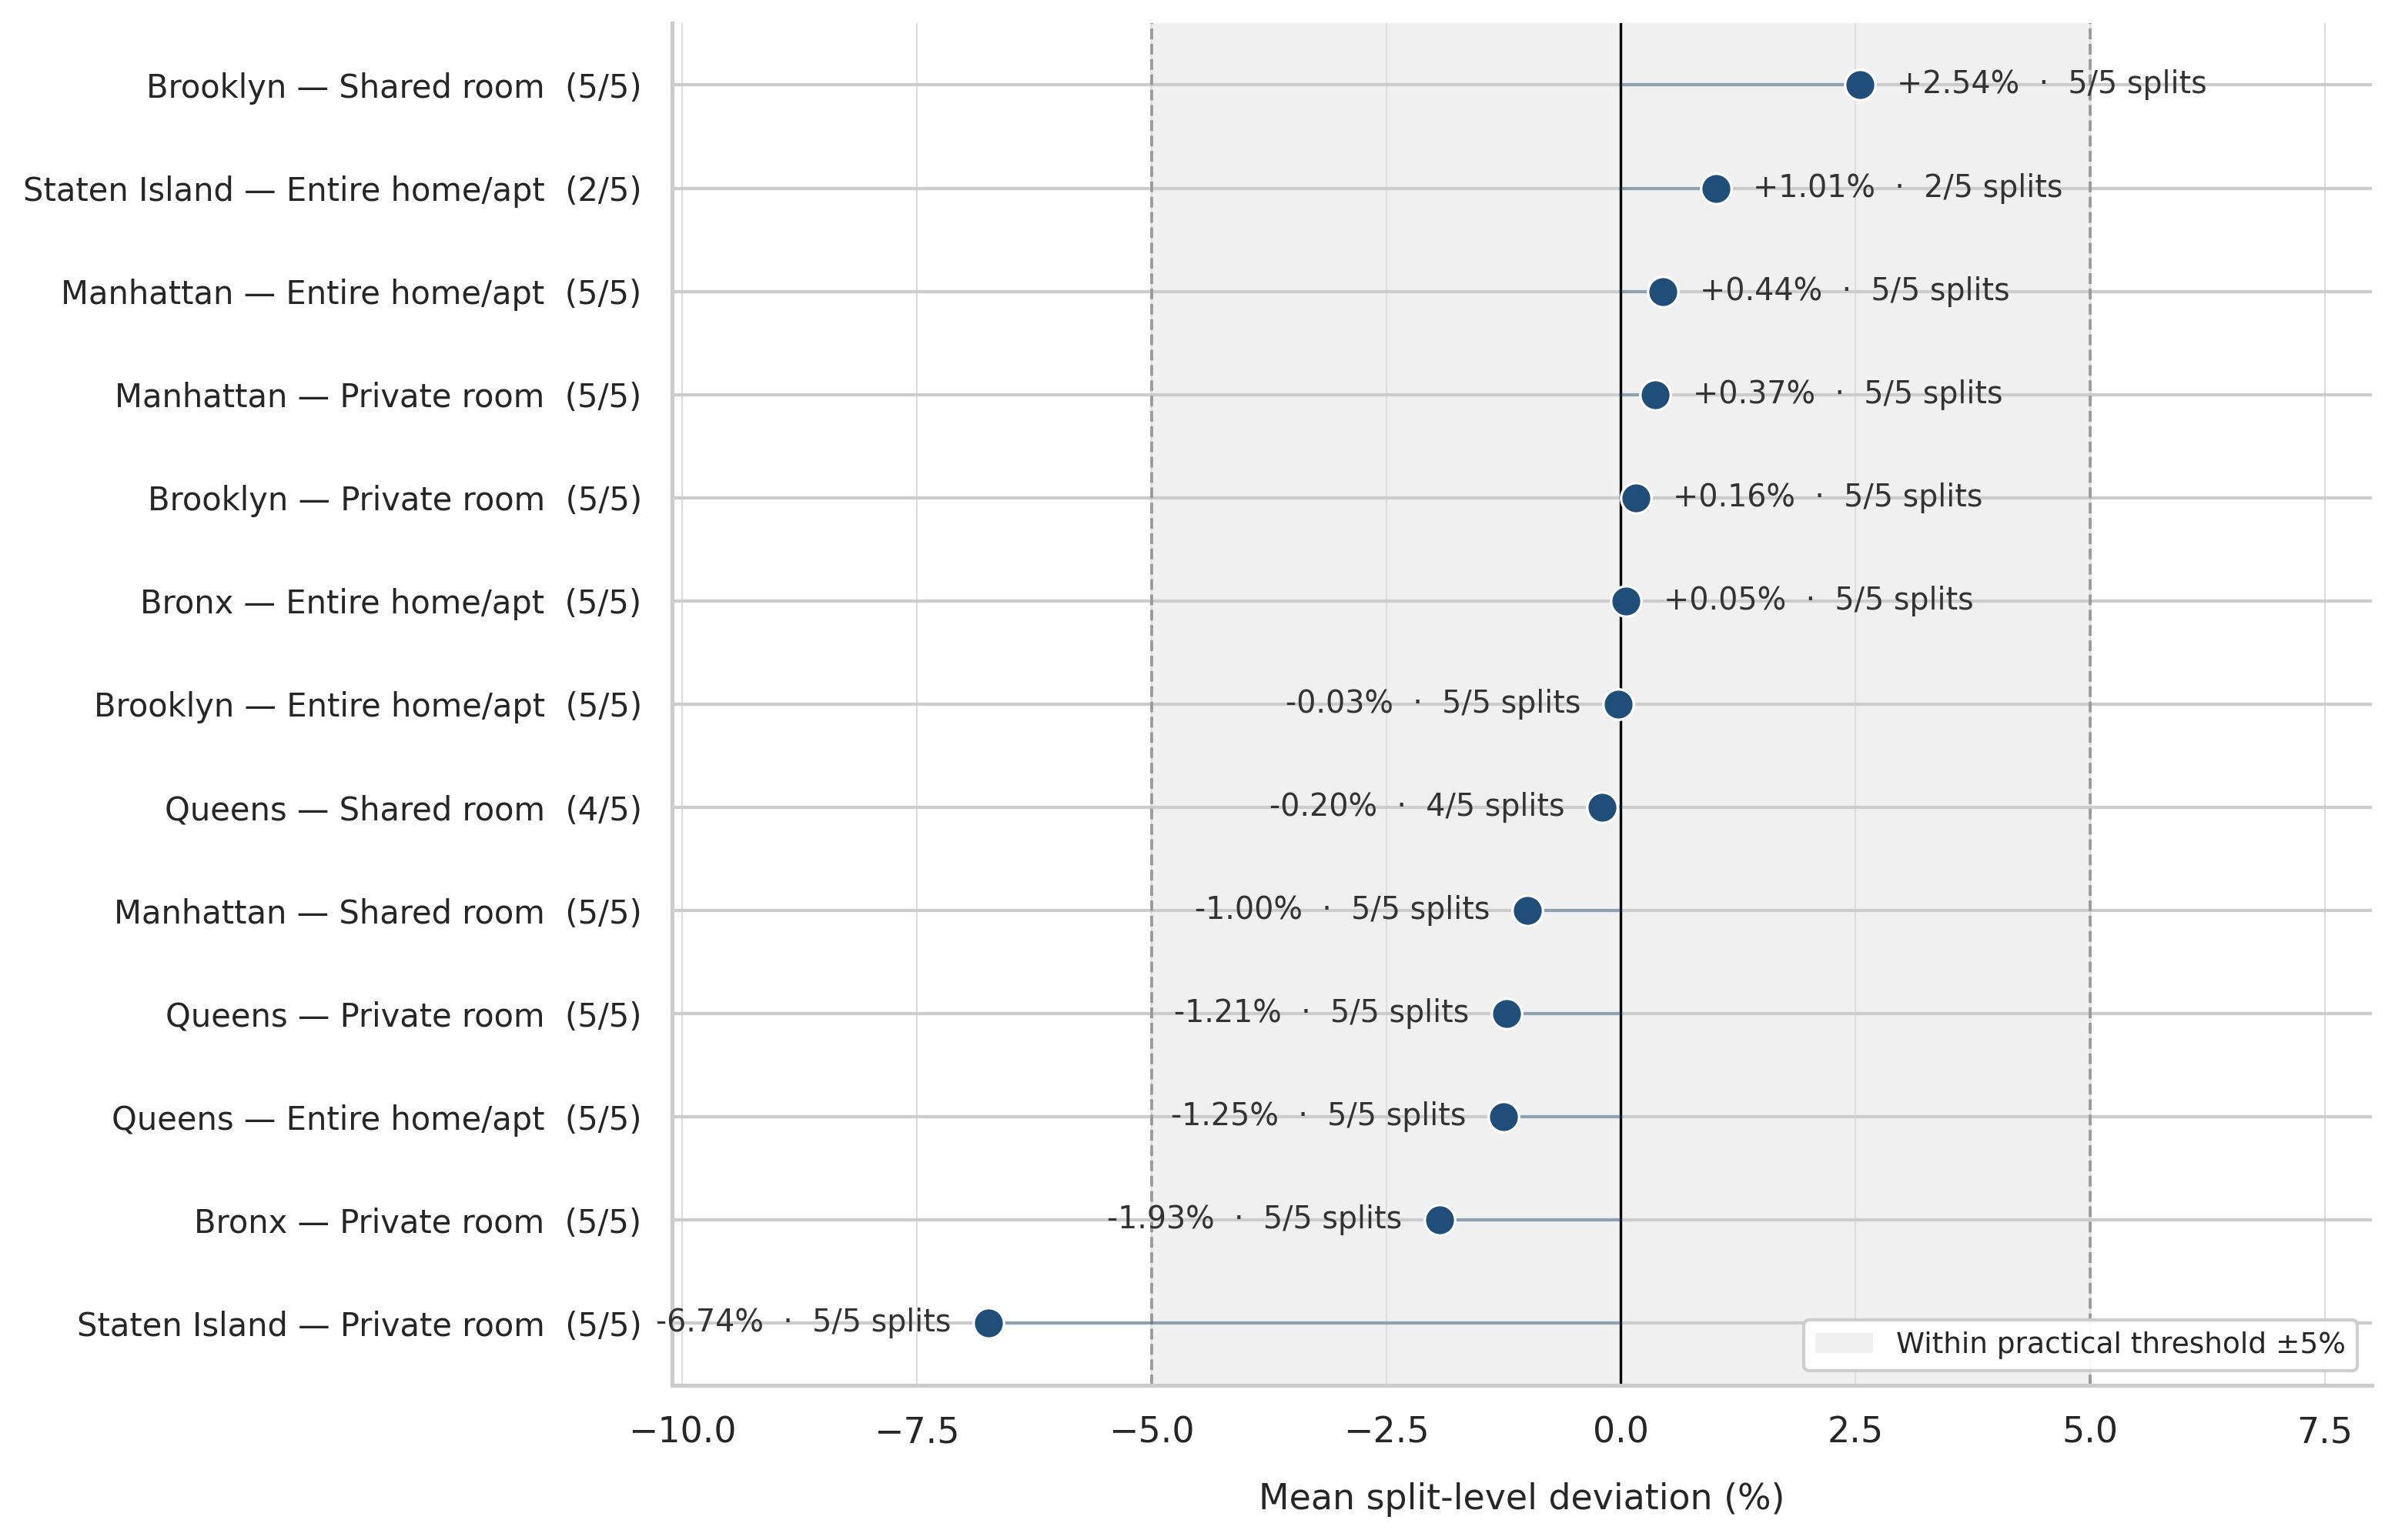

In [ ]:
# ---------- 1. Chuẩn bị dữ liệu ----------
plot_df = summary.copy()

# Chuyển log-ratio trung bình sang % chính xác: 100*(exp(D)-1)
plot_df['pct_dev'] = 100.0 * (np.exp(plot_df['mean_median_centered']) - 1.0)

# Nhãn phân khúc bằng tiếng Anh
plot_df['label'] = (
    plot_df['neighbourhood_group'] + ' — ' + plot_df['room_type']
    + '  (' + plot_df['n_splits_present'].astype(str) + '/5)'
)

# Sắp xếp theo độ lệch tăng dần
plot_df = plot_df.sort_values('pct_dev', ascending=True).reset_index(drop=True)

def status(row):
    if row['stable_below_model']:
        return 'below_stable'
    if row['stable_above_model']:
        return 'above_stable'
    return 'unstable'

plot_df['status'] = plot_df.apply(status, axis=1)

# ---------- 2. Thiết lập style ----------
plt.rcParams.update({
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 300,
})

THRESH_PCT = 100.0 * (np.exp(np.log(1.05)) - 1.0)   # = 5.0

# Một marker duy nhất cho mọi phân khúc
MARKER_COLOR = '#1f4e79'

fig, ax = plt.subplots(figsize=(10.5, 6.8))

# ---------- 3. Vẽ vùng ngưỡng thực tế ----------
ax.axvspan(-THRESH_PCT, THRESH_PCT, color='#f0f0f0', zorder=0)
ax.axvline(0, color='black', lw=0.8, zorder=1)
ax.axvline(-THRESH_PCT, color='#999999', lw=0.9, ls='--', zorder=1)
ax.axvline( THRESH_PCT, color='#999999', lw=0.9, ls='--', zorder=1)

# ---------- 4. Vẽ điểm và nhãn ----------
y = np.arange(len(plot_df))
for i, row in plot_df.iterrows():
    ax.scatter(row['pct_dev'], i,
               marker='o', s=90, color=MARKER_COLOR,
               edgecolor='white', linewidth=0.8, zorder=3)
    ax.plot([0, row['pct_dev']], [i, i],
            color=MARKER_COLOR, lw=1.0, alpha=0.35, zorder=2)

    # Xử lý vị trí nhãn để không bị đè
    if row['pct_dev'] >= 0:
        ha = 'left'
        x_offset = 0.4
    else:
        ha = 'right'
        x_offset = -0.4

    txt = f"{row['pct_dev']:+.2f}%  ·  {int(row['n_splits_present'])}/5 splits"
    ax.text(row['pct_dev'] + x_offset, i, txt,
            va='center', ha=ha, fontsize=9.5, color='#333333')

# ---------- 5. Trục và nhãn ----------
ax.set_yticks(y)
ax.set_yticklabels(plot_df['label'], fontsize=10)
ax.set_xlabel('Mean split-level deviation (%)', fontsize=11, labelpad=10)
#ax.set_title(
#    'RQ3 — Observed price deviation from model, averaged across splits\n'
#    '(Describing magnitude and direction only; no segment passed the Holm criterion)',
#    fontsize=12, loc='left', pad=15,
#)

xmin = min(-THRESH_PCT * 1.6, plot_df['pct_dev'].min() * 1.5)
xmax = max( THRESH_PCT * 1.6, plot_df['pct_dev'].max() * 1.25)
ax.set_xlim(xmin, xmax)
ax.grid(axis='x', color='#dddddd', lw=0.5, zorder=0)
ax.set_axisbelow(True)

# ---------- 6. Legend (chỉ giữ chú giải vùng ngưỡng) ----------
legend_handles = [
    Patch(facecolor='#f0f0f0', edgecolor='none',
          label=f'Within practical threshold ±{THRESH_PCT:.0f}%'),
]
ax.legend(handles=legend_handles, loc='lower right', fontsize=9,
          frameon=True, framealpha=0.95)

# ---------- 7. Xuất ảnh (không có caption) ----------
plt.tight_layout()
plt.savefig('rq3_dotplot_deviation_en.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:

# ============================================================
# RQ3 — LIGHTWEIGHT SENSITIVITY ANALYSIS
# ============================================================
# Design:
#   2 representative segments
#   3 injected shifts: +5%, +10%, +20%
#   5 original test splits
#   200 host-clustered bootstrap replicates per split
#
# Total: 2 * 3 * 5 = 30 bootstrap calls
#
# Multiple testing:
#   Bonferroni correction using the number of eligible
#   segments in each split.
#
# This is a supplementary sensitivity check, not a replacement
# for the original RQ3 analysis (Holm, B=4000).
# ============================================================

# -----------------------------
# A. CONFIGURATION
# -----------------------------

B_SENS = 200

MIN_SEGMENT_N = 25
MIN_VALID_BOOTSTRAP_RATE = 0.99
PRACTICAL_THRESHOLD = np.log(1.05)

TARGET_SEGMENTS = [
    ("Brooklyn", "Entire home/apt"),
    ("Staten Island", "Private room"),
]

INJECTED_SHIFTS = [0.05, 0.10, 0.20]

SENS_SEEDS = list(SEEDS)


# -----------------------------
# B. PREPARE ORIGINAL D VALUES
# -----------------------------

baseline_gap = {}

for seed in SENS_SEEDS:

    test_s = split_models[seed]["test"]

    price_te_raw = np.asarray(
        split_models[seed]["price_te_raw"],
        dtype=float
    )

    pred_log = np.asarray(
        split_models[seed]["pred_log"],
        dtype=float
    )

    pred_naive = np.maximum(np.expm1(pred_log), 0)

    gap_df = pd.DataFrame({
        "neighbourhood_group":
            test_s["neighbourhood_group"].to_numpy(),

        "room_type":
            test_s["room_type"].to_numpy(),

        "host_id":
            test_s["host_id"].to_numpy(),

        "actual_price": price_te_raw,
        "predicted_price": pred_naive
    })

    gap_df["D"] = np.log(
        np.maximum(gap_df["actual_price"], 1) /
        np.maximum(gap_df["predicted_price"], 1)
    )

    baseline_gap[seed] = gap_df


# -----------------------------
# C. RUN SENSITIVITY TEST
# -----------------------------

sensitivity_results = []

total_tests = (
    len(TARGET_SEGMENTS)
    * len(INJECTED_SHIFTS)
    * len(SENS_SEEDS)
)

test_counter = 0

for target_neighbourhood, target_room_type in TARGET_SEGMENTS:

    for shift_pct in INJECTED_SHIFTS:

        print(
            f"\nTarget: {target_neighbourhood} | "
            f"{target_room_type} | Shift: +{shift_pct:.0%}"
        )

        shift_log = np.log1p(shift_pct)

        for split_idx, seed in enumerate(SENS_SEEDS):

            test_counter += 1

            gap_df = baseline_gap[seed].copy()

            # Target segment mask
            target_mask = (
                (gap_df["neighbourhood_group"] == target_neighbourhood) &
                (gap_df["room_type"] == target_room_type)
            )

            target_n = int(target_mask.sum())

            # Count all eligible segments for correction
            segment_sizes = (
                gap_df.groupby(
                    ["neighbourhood_group", "room_type"]
                ).size()
            )

            n_eligible_segments = int(
                (segment_sizes >= MIN_SEGMENT_N).sum()
            )

            # Skip if target segment is not eligible
            if target_n < MIN_SEGMENT_N:

                sensitivity_results.append({
                    "neighbourhood_group": target_neighbourhood,
                    "room_type": target_room_type,
                    "injected_shift": shift_pct,
                    "seed": seed,
                    "target_n": target_n,
                    "n_eligible_segments": n_eligible_segments,
                    "theta": np.nan,
                    "ci_low": np.nan,
                    "ci_high": np.nan,
                    "p_raw": np.nan,
                    "p_bonferroni": np.nan,
                    "significant": False,
                    "practical": False,
                    "detected": False
                })

                continue

            # Inject shift into target segment only
            gap_df["D_sim"] = gap_df["D"].copy()

            gap_df.loc[target_mask, "D_sim"] += shift_log

            # Host-clustered bootstrap:
            # overall median is recomputed within each replicate
            # by the existing helper function.
            bootstrap_seed = (
                900000
                + split_idx * 1000
                + int(shift_pct * 100)
                + len(target_neighbourhood)
            )

            theta_hat, boot_theta, valid_rate, n_hosts = (
                cluster_bootstrap_segment_gap(
                    gap_df,
                    segment_mask=target_mask,
                    value_col="D_sim",
                    group_col="host_id",
                    B=B_SENS,
                    seed=bootstrap_seed
                )
            )

            # Bootstrap reliability check
            if (
                valid_rate < MIN_VALID_BOOTSTRAP_RATE
                or len(boot_theta) == 0
                or not np.isfinite(theta_hat)
            ):

                ci_low = np.nan
                ci_high = np.nan
                p_raw = np.nan
                p_corrected = np.nan
                significant = False
                practical = False
                detected = False

            else:

                boot_theta = np.asarray(
                    boot_theta,
                    dtype=float
                )

                boot_theta = boot_theta[
                    np.isfinite(boot_theta)
                ]

                # Basic bootstrap CI
                q_low = np.quantile(boot_theta, 0.025)
                q_high = np.quantile(boot_theta, 0.975)

                ci_low = 2 * theta_hat - q_high
                ci_high = 2 * theta_hat - q_low

                # Two-sided bootstrap p-value
                bootstrap_errors = boot_theta - theta_hat

                p_raw = (
                    1 + np.sum(
                        np.abs(bootstrap_errors) >= abs(theta_hat)
                    )
                ) / (len(bootstrap_errors) + 1)

                # Conservative Bonferroni correction
                p_corrected = min(
                    p_raw * n_eligible_segments,
                    1.0
                )

                significant = p_corrected < 0.05

                # Practical magnitude: at least 5%
                practical = (
                    abs(theta_hat) >= PRACTICAL_THRESHOLD
                )

                # Positive injected shift -> positive detection
                detected = (
                    significant
                    and practical
                    and theta_hat > 0
                )

            sensitivity_results.append({
                "neighbourhood_group": target_neighbourhood,
                "room_type": target_room_type,
                "injected_shift": shift_pct,
                "seed": seed,
                "target_n": target_n,
                "n_hosts": n_hosts,
                "n_eligible_segments": n_eligible_segments,
                "theta": theta_hat,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "p_raw": p_raw,
                "p_bonferroni": p_corrected,
                "significant": significant,
                "practical": practical,
                "detected": detected
            })

            print(
                f"  [{test_counter}/{total_tests}] "
                f"Seed {seed}: theta={theta_hat:.4f}, "
                f"adjusted p={p_corrected:.4f}, "
                f"detected={detected}"
            )


# -----------------------------
# D. RESULT TABLES
# -----------------------------

sensitivity_detail_df = pd.DataFrame(
    sensitivity_results
)

# Aggregate across the five original splits.
sensitivity_summary = (
    sensitivity_detail_df
    .groupby([
        "neighbourhood_group",
        "room_type",
        "injected_shift"
    ])
    .agg(
        n_splits=("seed", "count"),
        mean_theta=("theta", "mean"),
        mean_target_n=("target_n", "mean"),
        detected_splits=("detected", "sum")
    )
    .reset_index()
)

sensitivity_summary["detected_3_of_5"] = (
    sensitivity_summary["detected_splits"] >= 3
)

sensitivity_summary["detection_rate_across_splits"] = (
    sensitivity_summary["detected_splits"] /
    sensitivity_summary["n_splits"]
)

print("\n" + "=" * 70)
print("RQ3 SENSITIVITY ANALYSIS — SUMMARY")
print("=" * 70)

display(
    sensitivity_summary.round(4)
)

print("\n" + "=" * 70)
print("RQ3 SENSITIVITY ANALYSIS — DETAIL")
print("=" * 70)

display(
    sensitivity_detail_df.round(4)
)

# -----------------------------
# E. SAVE RESULTS
# -----------------------------

sensitivity_detail_df.to_csv(
    "RQ3_sensitivity_detail.csv",
    index=False
)

sensitivity_summary.to_csv(
    "RQ3_sensitivity_summary.csv",
    index=False
)

print("\nSaved:")
print("- RQ3_sensitivity_detail.csv")
print("- RQ3_sensitivity_summary.csv")


Target: Brooklyn | Entire home/apt | Shift: +5%
  [1/30] Seed 42: theta=0.0269, adjusted p=0.0647, detected=False
  [2/30] Seed 1: theta=0.0259, adjusted p=0.2985, detected=False
  [3/30] Seed 7: theta=0.0554, adjusted p=0.0597, detected=False
  [4/30] Seed 123: theta=0.0431, adjusted p=0.0597, detected=False
  [5/30] Seed 2024: theta=0.0468, adjusted p=0.0597, detected=False

Target: Brooklyn | Entire home/apt | Shift: +10%
  [6/30] Seed 42: theta=0.0642, adjusted p=0.0647, detected=False
  [7/30] Seed 1: theta=0.0640, adjusted p=0.0597, detected=False
  [8/30] Seed 7: theta=0.0931, adjusted p=0.0597, detected=False
  [9/30] Seed 123: theta=0.0835, adjusted p=0.0597, detected=False
  [10/30] Seed 2024: theta=0.0858, adjusted p=0.0597, detected=False

Target: Brooklyn | Entire home/apt | Shift: +20%
  [11/30] Seed 42: theta=0.1348, adjusted p=0.0647, detected=False
  [12/30] Seed 1: theta=0.1358, adjusted p=0.0597, detected=False
  [13/30] Seed 7: theta=0.1648, adjusted p=0.0597, dete

,neighbourhood_group,room_type,injected_shift,n_splits,mean_theta,mean_target_n,detected_splits,detected_3_of_5,detection_rate_across_splits
0,Brooklyn,Entire home/apt,0.05,5,0.0396,1445.2,0,False,0.0
1,Brooklyn,Entire home/apt,0.10,5,0.0781,1445.2,0,False,0.0
2,Brooklyn,Entire home/apt,0.20,5,0.1499,1445.2,0,False,0.0
3,Staten Island,Private room,0.05,5,-0.0212,27.0,0,False,0.0
4,Staten Island,Private room,0.10,5,0.0253,27.0,0,False,0.0
5,Staten Island,Private room,0.20,5,0.1121,27.0,0,False,0.0



RQ3 SENSITIVITY ANALYSIS — DETAIL


,neighbourhood_group,room_type,injected_shift,seed,target_n,n_hosts,n_eligible_segments,theta,ci_low,ci_high,p_raw,p_bonferroni,significant,practical,detected
0,Brooklyn,Entire home/apt,0.05,42,1478,6655,13,0.0269,0.0122,0.0438,0.0050,0.0647,False,False,False
1,Brooklyn,Entire home/apt,0.05,1,1456,6668,12,0.0259,0.0010,0.0390,0.0249,0.2985,False,False,False
2,Brooklyn,Entire home/apt,0.05,7,1442,6681,12,0.0554,0.0398,0.0715,0.0050,0.0597,False,True,False
3,Brooklyn,Entire home/apt,0.05,123,1393,6625,12,0.0431,0.0207,0.0594,0.0050,0.0597,False,False,False
4,Brooklyn,Entire home/apt,0.05,2024,1457,6654,12,0.0468,0.0262,0.0619,0.0050,0.0597,False,False,False
5,Brooklyn,Entire home/apt,0.10,42,1478,6655,13,0.0642,0.0452,0.0824,0.0050,0.0647,False,True,False
6,Brooklyn,Entire home/apt,0.10,1,1456,6668,12,0.0640,0.0443,0.0757,0.0050,0.0597,False,True,False
7,Brooklyn,Entire home/apt,0.10,7,1442,6681,12,0.0931,0.0734,0.1109,0.0050,0.0597,False,True,False
8,Brooklyn,Entire home/apt,0.10,123,1393,6625,12,0.0835,0.0620,0.1048,0.0050,0.0597,False,True,False
9,Brooklyn,Entire home/apt,0.10,2024,1457,6654,12,0.0858,0.0627,0.1019,0.0050,0.0597,False,True,False



Saved:
- RQ3_sensitivity_detail.csv
- RQ3_sensitivity_summary.csv


In [ ]:
# ============================================================
# RQ3 — HOST TYPE: MULTI-HOST vs SINGLE-HOST
# Bootstrap trực tiếp hiệu số median, chạy qua 5 seed
# ============================================================

B = 2000
BASE_BOOTSTRAP_SEED = 42

# Lấy 5 seed đầu tiên theo thứ tự
seeds = sorted(split_models.keys())[:5]

if len(seeds) != 5:
    raise ValueError(
        f"Yêu cầu 5 seed, nhưng split_models chỉ có {len(seeds)} seed."
    )

results_host_type = []

for seed_idx, seed in enumerate(seeds):

    # ---------- 1. Chuẩn bị dữ liệu của seed ----------
    model_data = split_models[seed]

    test = model_data['test']
    price_te_raw = np.asarray(model_data['price_te_raw']).reshape(-1)
    pred_log = np.asarray(model_data['pred_log']).reshape(-1)

    if len(test) != len(price_te_raw) or len(test) != len(pred_log):
        raise ValueError(
            f"Seed {seed}: số dòng test, actual price và prediction không khớp."
        )

    pred_price = np.maximum(np.expm1(pred_log), 0)

    host_gap_df = test[
        ['calculated_host_listings_count', 'host_id']
    ].copy()

    host_gap_df['actual_price'] = price_te_raw
    host_gap_df['pred_price'] = pred_price

    # Dùng cùng định nghĩa log-ratio như code cũ
    host_gap_df['D'] = np.log(
        np.maximum(host_gap_df['actual_price'], 1)
        / np.maximum(host_gap_df['pred_price'], 1)
    )

    host_gap_df['host_type'] = np.where(
        host_gap_df['calculated_host_listings_count'] > 1,
        'multi',
        'single'
    )

    # Loại bỏ dòng thiếu host_id hoặc D không hữu hạn
    host_gap_df = host_gap_df[
        host_gap_df['host_id'].notna()
        & np.isfinite(host_gap_df['D'])
    ].copy()

    # ---------- 2. Tạo cụm host riêng cho mỗi nhóm ----------
    multi_df = host_gap_df[host_gap_df['host_type'] == 'multi']
    single_df = host_gap_df[host_gap_df['host_type'] == 'single']

    multi_groups = [
        g['D'].to_numpy()
        for _, g in multi_df.groupby('host_id', sort=False)
    ]

    single_groups = [
        g['D'].to_numpy()
        for _, g in single_df.groupby('host_id', sort=False)
    ]

    if len(multi_groups) < 2 or len(single_groups) < 2:
        raise ValueError(
            f"Seed {seed}: không đủ host trong một trong hai nhóm để bootstrap."
        )

    # ---------- 3. Point estimate trên dữ liệu quan sát ----------
    median_multi = np.median(multi_df['D'])
    median_single = np.median(single_df['D'])

    # Multi minus single
    observed_diff = median_multi - median_single

    # ---------- 4. Cluster bootstrap ----------
    # Lấy mẫu host có hoàn lại trong từng nhóm.
    # Nếu một host được chọn, giữ toàn bộ D của host đó.
    rng = np.random.default_rng(BASE_BOOTSTRAP_SEED + seed_idx)

    boot_diffs = np.empty(B)

    for b in range(B):

        m_idx = rng.integers(
            0, len(multi_groups), size=len(multi_groups)
        )
        s_idx = rng.integers(
            0, len(single_groups), size=len(single_groups)
        )

        boot_multi = np.concatenate(
            [multi_groups[j] for j in m_idx]
        )
        boot_single = np.concatenate(
            [single_groups[j] for j in s_idx]
        )

        boot_diffs[b] = (
            np.median(boot_multi) - np.median(boot_single)
        )

    # Percentile bootstrap CI 95%
    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

    results_host_type.append({
        'seed': seed,
        'n_multi_listings': len(multi_df),
        'n_single_listings': len(single_df),
        'n_multi_hosts': len(multi_groups),
        'n_single_hosts': len(single_groups),
        'median_D_multi': median_multi,
        'median_D_single': median_single,
        'diff_multi_minus_single': observed_diff,
        'ci95_low': ci_low,
        'ci95_high': ci_high,
        'ci_excludes_zero': (ci_low > 0) or (ci_high < 0)
    })


In [ ]:
# ---------- 5. Tổng hợp kết quả ----------
host_type_results = pd.DataFrame(results_host_type)

print('\n=== HOST TYPE: MULTI-HOST - SINGLE-HOST ===')
print(
    host_type_results.to_string(
        index=False,
        formatters={
            'median_D_multi': '{:.4f}'.format,
            'median_D_single': '{:.4f}'.format,
            'diff_multi_minus_single': '{:.4f}'.format,
            'ci95_low': '{:.4f}'.format,
            'ci95_high': '{:.4f}'.format
        }
    )
)


=== HOST TYPE: MULTI-HOST - SINGLE-HOST ===
 seed  n_multi_listings  n_single_listings  n_multi_hosts  n_single_hosts median_D_multi median_D_single diff_multi_minus_single ci95_low ci95_high  ci_excludes_zero
    1              2447               4886           1782            4886        -0.0256         -0.0240                 -0.0016  -0.0228    0.0167             False
    7              2465               4868           1813            4868        -0.0236         -0.0216                 -0.0020  -0.0172    0.0182             False
   42              2496               4837           1818            4837        -0.0179         -0.0312                  0.0132  -0.0023    0.0309             False
  123              2521               4812           1813            4812        -0.0252         -0.0273                  0.0021  -0.0155    0.0215             False
 2024              2507               4826           1828            4826        -0.0161         -0.0266                  0.0

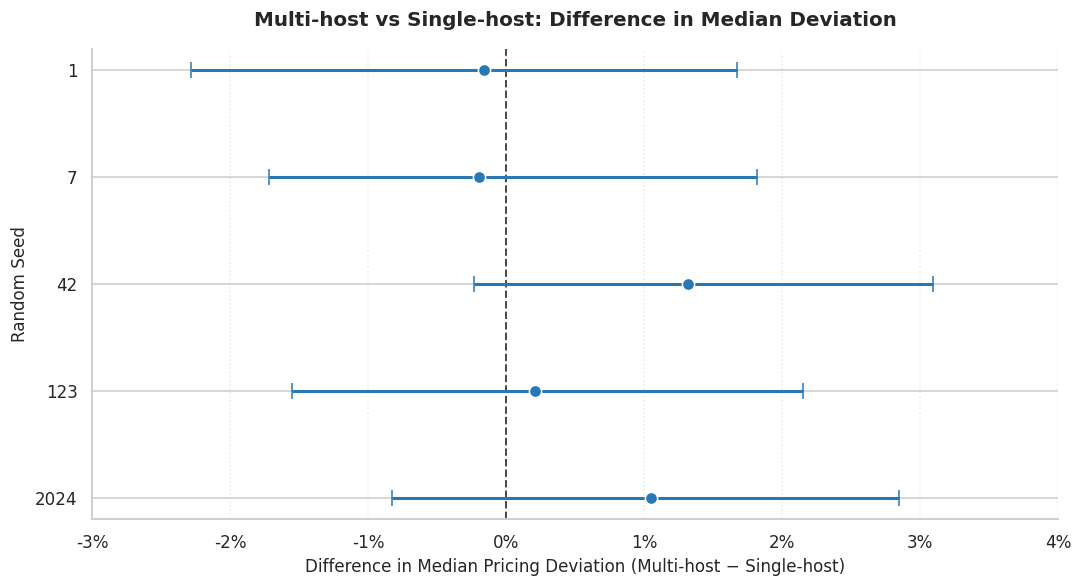

In [ ]:
# Data
seeds = ['1', '7', '42', '123', '2024']

diff = np.array([
    -0.0016,
    -0.0020,
     0.0132,
     0.0021,
     0.0105
])

ci_low = np.array([
    -0.0228,
    -0.0172,
    -0.0023,
    -0.0155,
    -0.0083
])

ci_high = np.array([
     0.0167,
     0.0182,
     0.0309,
     0.0215,
     0.0285
])

# Error bars
xerr = np.array([
    diff - ci_low,
    ci_high - diff
])

fig, ax = plt.subplots(figsize=(10, 5.5))

y = np.arange(len(seeds))

# Zero reference line
ax.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=1.3,
    alpha=0.7,
    label='No difference'
)

# Confidence intervals and point estimates
ax.errorbar(
    diff,
    y,
    xerr=xerr,
    fmt='o',
    color='#2878B5',
    ecolor='#2878B5',
    elinewidth=2,
    capsize=5,
    markersize=8,
    markeredgecolor='white',
    markeredgewidth=1
)

# Labels
ax.set_yticks(y)
ax.set_yticklabels(seeds)
ax.invert_yaxis()

ax.set_xlabel(
    'Difference in Median Pricing Deviation '
    '(Multi-host − Single-host)',
    fontsize=11
)

ax.set_ylabel('Random Seed', fontsize=11)

ax.set_title(
    'Multi-host vs Single-host: Difference in Median Deviation',
    fontsize=13,
    fontweight='bold',
    pad=15
)

# Formatting
ax.set_xlim(-0.03, 0.04)
ax.set_xticks(np.arange(-0.03, 0.041, 0.01))
ax.set_xticklabels(
    [f'{v:.0%}' for v in np.arange(-0.03, 0.041, 0.01)]
)

ax.grid(axis='x', linestyle=':', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(
    'host_type_forest_plot.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


In [ ]:
# Tóm tắt độ nhất quán giữa 5 seed
print('\n=== SUMMARY ACROSS 5 SEEDS ===')
print(
    'Mean observed difference:',
    round(host_type_results['diff_multi_minus_single'].mean(), 4)
)
print(
    'Median observed difference:',
    round(host_type_results['diff_multi_minus_single'].median(), 4)
)
print(
    'Seeds with positive difference:',
    int((host_type_results['diff_multi_minus_single'] > 0).sum()),
    '/ 5'
)
print(
    'Seeds with negative difference:',
    int((host_type_results['diff_multi_minus_single'] < 0).sum()),
    '/ 5'
)
print(
    'Seeds whose bootstrap CI excludes zero:',
    int(host_type_results['ci_excludes_zero'].sum()),
    '/ 5'
)


=== SUMMARY ACROSS 5 SEEDS ===
Mean observed difference: 0.0044
Median observed difference: 0.0021
Seeds with positive difference: 3 / 5
Seeds with negative difference: 2 / 5
Seeds whose bootstrap CI excludes zero: 0 / 5


In [ ]:
# ============================================================
# RQ3 — HOST-TYPE COMPARISON WITHIN EACH ROOM TYPE
# Multi-listing hosts vs single-listing hosts
# Estimand: median(D_multi) - median(D_single)
# Bootstrap theo host_id, riêng từng room type và từng split
# ============================================================

B_HOST = 2000
BASE_HOST_SEED = 20261029
MIN_HOSTS_PER_GROUP = 2

host_type_room_results = []

# Giữ đúng thứ tự 5 splits đã sử dụng trong các phân tích trước
seeds = list(SEEDS)

if len(seeds) != 5:
    raise ValueError(
        f"Yêu cầu đúng 5 SEEDS, hiện có {len(seeds)}."
    )

for split_idx, seed in enumerate(seeds):

    model_data = split_models[seed]
    test = model_data["test"].copy().reset_index(drop=True)

    price_actual = np.asarray(
        model_data["price_te_raw"]
    ).reshape(-1)

    pred_log = np.asarray(
        model_data["pred_log"]
    ).reshape(-1)

    if not (
        len(test) == len(price_actual) == len(pred_log)
    ):
        raise ValueError(
            f"Seed {seed}: số dòng test, actual và prediction không khớp."
        )

    required_cols = [
        "room_type",
        "calculated_host_listings_count",
        "host_id",
    ]
    missing_cols = [
        c for c in required_cols if c not in test.columns
    ]
    if missing_cols:
        raise ValueError(
            f"Seed {seed}: thiếu các cột {missing_cols}."
        )

    # ---------- 1. Tạo dữ liệu phân tích ----------
    host_df = test[required_cols].copy()
    host_df["actual_price"] = price_actual
    host_df["pred_price"] = np.maximum(
        np.expm1(pred_log), 0
    )

    host_df["D"] = np.log(
        np.maximum(host_df["actual_price"], 1)
        / np.maximum(host_df["pred_price"], 1)
    )

    # Giữ định nghĩa host type đang dùng trong paper
    host_df["host_type"] = np.where(
        host_df["calculated_host_listings_count"] > 1,
        "multi",
        "single",
    )

    # Không bootstrap các dòng không xác định được host,
    # room type, hoặc host type
    host_df = host_df.dropna(
        subset=[
            "host_id",
            "room_type",
            "calculated_host_listings_count",
        ]
    ).copy()

    host_df = host_df[
        np.isfinite(host_df["D"])
    ].copy()

    # ---------- 2. So sánh trong từng room type ----------
    for room_idx, room_type in enumerate(
        sorted(host_df["room_type"].unique())
    ):

        room_df = host_df[
            host_df["room_type"] == room_type
        ].copy()

        multi_df = room_df[
            room_df["host_type"] == "multi"
        ]
        single_df = room_df[
            room_df["host_type"] == "single"
        ]

        multi_hosts = [
            group["D"].to_numpy()
            for _, group in multi_df.groupby(
                "host_id", sort=False
            )
        ]

        single_hosts = [
            group["D"].to_numpy()
            for _, group in single_df.groupby(
                "host_id", sort=False
            )
        ]

        n_multi_hosts = len(multi_hosts)
        n_single_hosts = len(single_hosts)

        # Không đủ host để bootstrap: lưu trạng thái,
        # không tự xem đây là kết quả bằng 0.
        if (
            n_multi_hosts < MIN_HOSTS_PER_GROUP
            or n_single_hosts < MIN_HOSTS_PER_GROUP
        ):
            host_type_room_results.append({
                "seed": seed,
                "room_type": room_type,
                "n_multi_listings": len(multi_df),
                "n_single_listings": len(single_df),
                "n_multi_hosts": n_multi_hosts,
                "n_single_hosts": n_single_hosts,
                "median_D_multi": np.nan,
                "median_D_single": np.nan,
                "diff_multi_minus_single": np.nan,
                "ci95_low": np.nan,
                "ci95_high": np.nan,
                "ci_excludes_zero": np.nan,
                "status": "insufficient_hosts",
            })
            continue

        # ---------- 3. Point estimates ----------
        median_multi = np.median(multi_df["D"])
        median_single = np.median(single_df["D"])

        # Giá trị dương: median D của multi-host cao hơn
        # single-host trong cùng loại phòng.
        observed_diff = median_multi - median_single

        # ---------- 4. Cluster bootstrap ----------
        rng = np.random.default_rng(
            BASE_HOST_SEED
            + split_idx * 100
            + room_idx
        )

        boot_diffs = np.empty(B_HOST)

        for b in range(B_HOST):

            # Resample host trong từng nhóm độc lập.
            # Giữ toàn bộ listing của host được chọn.
            idx_multi = rng.integers(
                0, n_multi_hosts, size=n_multi_hosts
            )
            idx_single = rng.integers(
                0, n_single_hosts, size=n_single_hosts
            )

            boot_multi = np.concatenate([
                multi_hosts[j] for j in idx_multi
            ])
            boot_single = np.concatenate([
                single_hosts[j] for j in idx_single
            ])

            boot_diffs[b] = (
                np.median(boot_multi)
                - np.median(boot_single)
            )

        # Percentile bootstrap 95% CI
        ci_low, ci_high = np.quantile(
            boot_diffs, [0.025, 0.975]
        )

        ci_excludes_zero = (
            (ci_low > 0) or (ci_high < 0)
        )

        host_type_room_results.append({
            "seed": seed,
            "room_type": room_type,
            "n_multi_listings": len(multi_df),
            "n_single_listings": len(single_df),
            "n_multi_hosts": n_multi_hosts,
            "n_single_hosts": n_single_hosts,
            "median_D_multi": median_multi,
            "median_D_single": median_single,
            "diff_multi_minus_single": observed_diff,
            "ci95_low": ci_low,
            "ci95_high": ci_high,
            "ci_excludes_zero": ci_excludes_zero,
            "status": "ok",
        })


In [ ]:
# ============================================================
# 5. KẾT QUẢ THEO TỪNG SPLIT VÀ ROOM TYPE
# ============================================================

host_type_room_df = pd.DataFrame(
    host_type_room_results
)

print("\n=== HOST TYPE WITHIN EACH ROOM TYPE: PER SPLIT ===")

print(
    host_type_room_df.sort_values(
        ["room_type", "seed"]
    ).to_string(
        index=False,
        formatters={
            "median_D_multi": lambda x: (
                f"{x:.4f}" if pd.notna(x) else "NA"
            ),
            "median_D_single": lambda x: (
                f"{x:.4f}" if pd.notna(x) else "NA"
            ),
            "diff_multi_minus_single": lambda x: (
                f"{x:.4f}" if pd.notna(x) else "NA"
            ),
            "ci95_low": lambda x: (
                f"{x:.4f}" if pd.notna(x) else "NA"
            ),
            "ci95_high": lambda x: (
                f"{x:.4f}" if pd.notna(x) else "NA"
            ),
        }
    )
)



=== HOST TYPE WITHIN EACH ROOM TYPE: PER SPLIT ===
 seed       room_type  n_multi_listings  n_single_listings  n_multi_hosts  n_single_hosts median_D_multi median_D_single diff_multi_minus_single ci95_low ci95_high  ci_excludes_zero status
    1 Entire home/apt               932               2886            611            2886        -0.0233         -0.0225                 -0.0008  -0.0314    0.0302             False     ok
    7 Entire home/apt               987               2812            663            2812        -0.0141         -0.0180                  0.0038  -0.0208    0.0293             False     ok
   42 Entire home/apt               987               2856            674            2856        -0.0068         -0.0314                  0.0246  -0.0014    0.0504             False     ok
  123 Entire home/apt               985               2837            637            2837        -0.0139         -0.0348                  0.0208  -0.0068    0.0481             False     ok
 20

In [ ]:
# ============================================================
# 6. TỔNG HỢP QUA 5 SPLITS
# CI được tính riêng từng split; KHÔNG gộp các cận CI.
# ============================================================

valid_host_results = host_type_room_df[
    host_type_room_df["status"] == "ok"
].copy()

host_type_room_summary = (
    valid_host_results
    .groupby("room_type", as_index=False)
    .agg(
        n_splits_valid=("seed", "nunique"),
        mean_diff=("diff_multi_minus_single", "mean"),
        sd_diff=("diff_multi_minus_single", "std"),
        median_diff=("diff_multi_minus_single", "median"),
        n_ci_excludes_zero=("ci_excludes_zero", "sum"),
        n_positive=("diff_multi_minus_single",
                    lambda x: (x > 0).sum()),
        n_negative=("diff_multi_minus_single",
                    lambda x: (x < 0).sum()),
    )
)

print("\n=== HOST TYPE WITHIN EACH ROOM TYPE: 5-SPLIT SUMMARY ===")

print(
    host_type_room_summary.sort_values(
        "room_type"
    ).to_string(
        index=False,
        formatters={
            "mean_diff": "{:.4f}".format,
            "sd_diff": "{:.4f}".format,
            "median_diff": "{:.4f}".format,
        }
    )
)


=== HOST TYPE WITHIN EACH ROOM TYPE: 5-SPLIT SUMMARY ===
      room_type  n_splits_valid mean_diff sd_diff median_diff  n_ci_excludes_zero  n_positive  n_negative
Entire home/apt               5    0.0163  0.0143      0.0208                   1           4           1
   Private room               5   -0.0039  0.0073     -0.0015                   0           1           4
    Shared room               5   -0.0015  0.1327      0.0317                   1           3           2


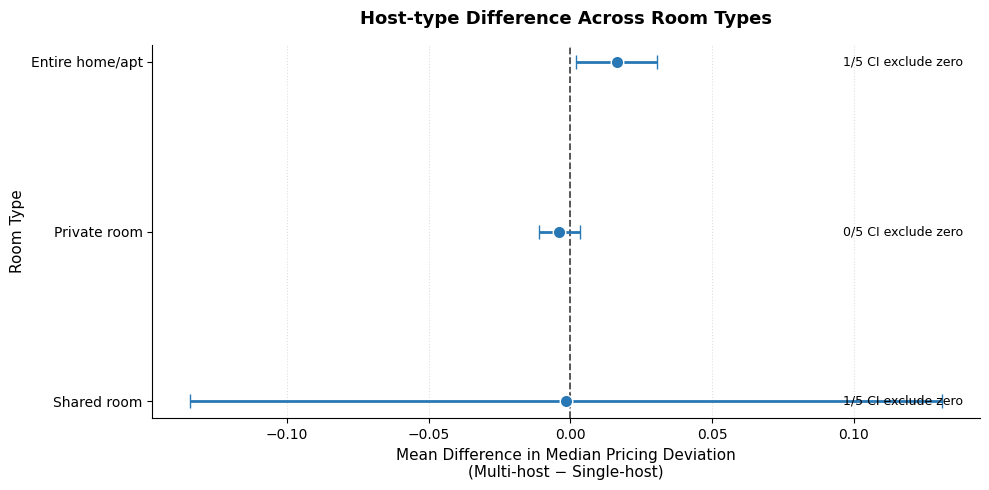

In [ ]:
# Data
room_types = [
    'Entire home/apt',
    'Private room',
    'Shared room'
]

mean_diff = np.array([0.0163, -0.0039, -0.0015])
sd_diff = np.array([0.0143, 0.0073, 0.1327])

n_ci = [1, 0, 1]

y = np.arange(len(room_types))

fig, ax = plt.subplots(figsize=(10, 5))

# Zero reference
ax.axvline(
    0,
    color='black',
    linestyle='--',
    linewidth=1.3,
    alpha=0.7
)

# Mean ± SD
ax.errorbar(
    mean_diff,
    y,
    xerr=sd_diff,
    fmt='o',
    color='#2878B5',
    ecolor='#2878B5',
    elinewidth=2,
    capsize=5,
    markersize=9,
    markeredgecolor='white',
    markeredgewidth=1
)

ax.set_yticks(y)
ax.set_yticklabels(room_types)
ax.invert_yaxis()

ax.set_xlabel(
    'Mean Difference in Median Pricing Deviation\n'
    '(Multi-host − Single-host)',
    fontsize=11
)

ax.set_ylabel('Room Type', fontsize=11)

ax.set_title(
    'Host-type Difference Across Room Types',
    fontsize=13,
    fontweight='bold',
    pad=15
)

ax.grid(axis='x', linestyle=':', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

# Annotate CI consistency
for i, count in enumerate(n_ci):
    ax.text(
        0.98, i,
        f'{count}/5 CI exclude zero',
        transform=ax.get_yaxis_transform(),
        ha='right',
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    'host_type_by_room_type.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


Research Question 1:

In [ ]:
best_alpha_lasso = 0.0001  # nằm giữa vùng phẳng (1e-6 đến ~5e-4), tránh chọn đúng điểm biên
best_alpha_ridge = 1.0     # không đổi — đường cong vẫn phẳng hoàn toàn như trước
X_tr_lin, y_tr_lin, X_te_lin, _, _ = prepare_fold_fixed(train_full, test, drop_first=True, use_name_features=True)

final_lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Lasso(alpha=best_alpha_lasso, random_state=42, max_iter=50000))
])
final_lasso.fit(X_tr_lin, y_tr_lin)

lasso_coef = pd.Series(final_lasso.named_steps['model'].coef_, index=X_tr_lin.columns).sort_values(key=abs, ascending=False)
print(lasso_coef)
print('\nSố feature bị loại (coef=0):', (lasso_coef == 0).sum(), '/', len(lasso_coef))

room_Private room          -0.353303
neighbourhood_target_enc    0.198509
n_bed_name                  0.197322
n_bed_name_missing          0.179618
room_Shared room           -0.164552
minimum_nights_log         -0.104915
availability_365            0.073523
dist_times_square          -0.060935
is_unavailable             -0.051568
kw_luxury                   0.037473
kw_townhouse                0.035249
has_review                 -0.033780
kw_loft                     0.032846
kw_cozy                    -0.031867
kw_duplex                   0.031308
ng_Manhattan                0.030621
reviews_per_month_log      -0.028879
number_of_reviews_log      -0.027349
kw_penthouse                0.022684
host_listings_log          -0.010705
latitude_scaled            -0.007587
kw_hostel                  -0.007253
longitude_scaled           -0.006479
kw_bunk                    -0.004917
ng_Staten Island           -0.004622
ng_Queens                   0.002508
dist_wall_street            0.001939
d

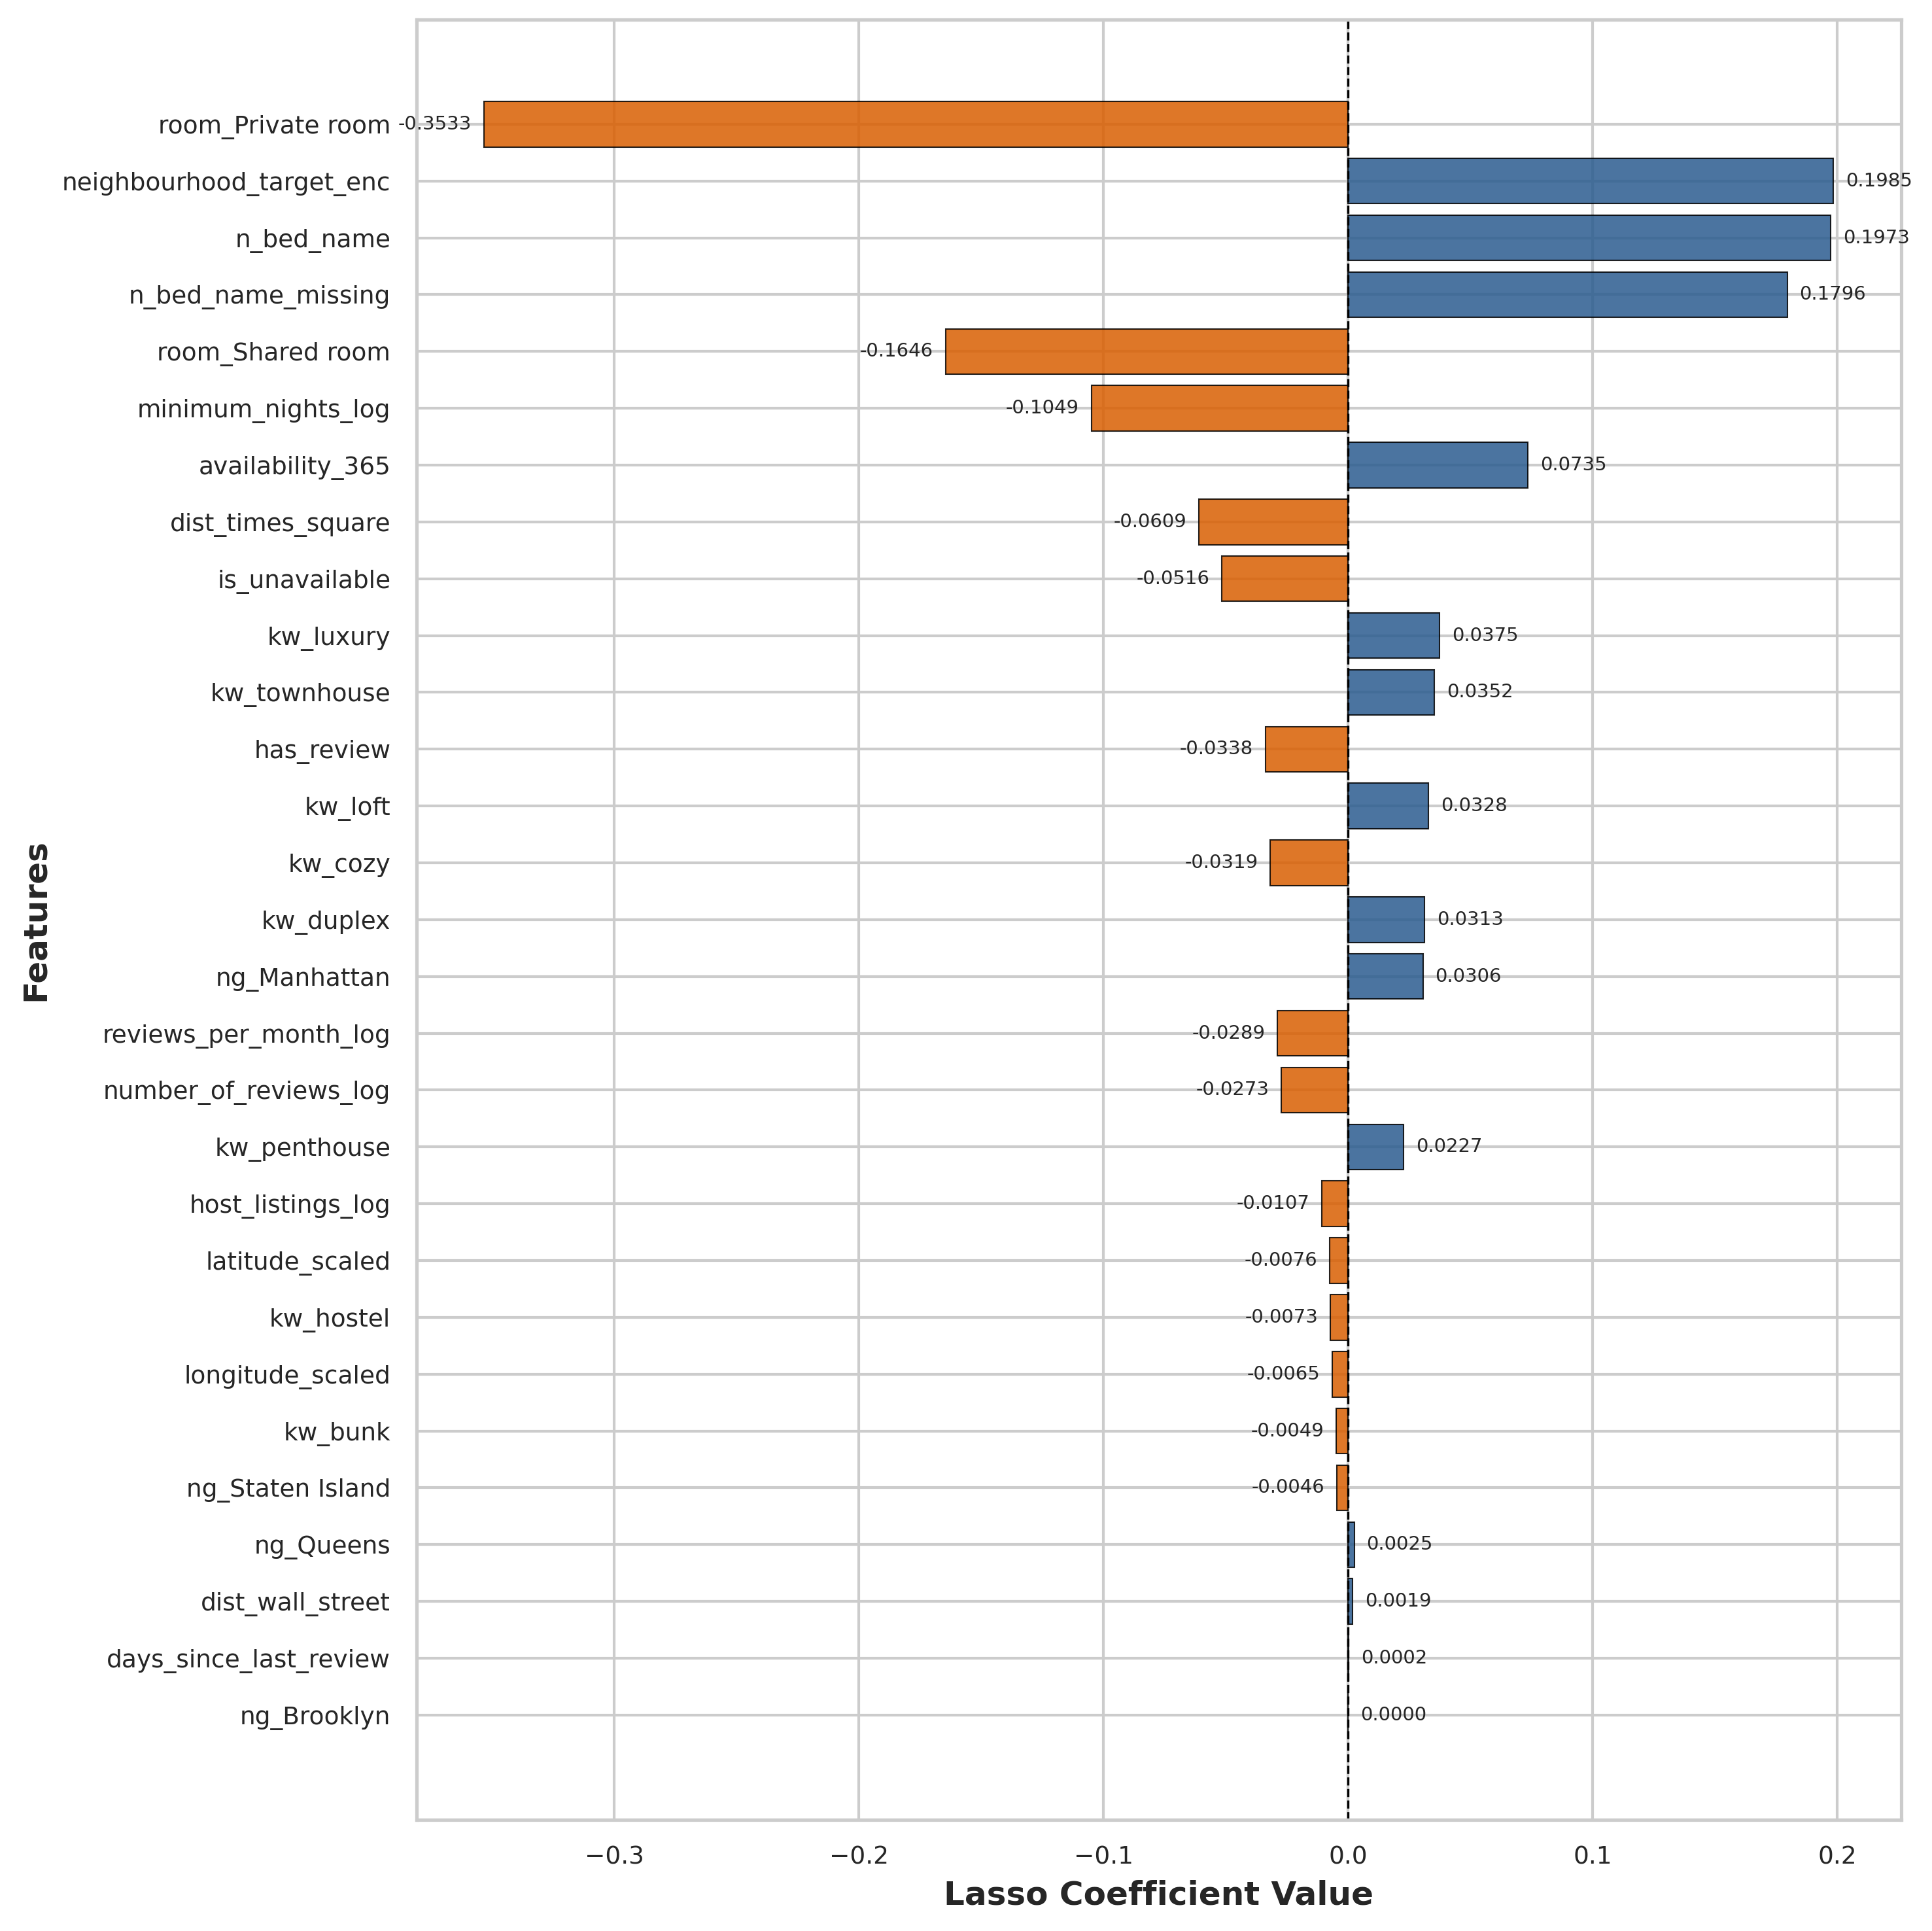

In [ ]:
# Dữ liệu hệ số Lasso - ĐÃ CẬP NHẬT
data = {
    'room_Private room': -0.353303,
    'neighbourhood_target_enc': 0.198509,
    'n_bed_name': 0.197322,
    'n_bed_name_missing': 0.179618,
    'room_Shared room': -0.164552,
    'minimum_nights_log': -0.104915,
    'availability_365': 0.073523,
    'dist_times_square': -0.060935,
    'is_unavailable': -0.051568,
    'kw_luxury': 0.037473,
    'kw_townhouse': 0.035249,
    'has_review': -0.033780,
    'kw_loft': 0.032846,
    'kw_cozy': -0.031867,
    'kw_duplex': 0.031308,
    'ng_Manhattan': 0.030621,
    'reviews_per_month_log': -0.028879,
    'number_of_reviews_log': -0.027349,
    'kw_penthouse': 0.022684,
    'host_listings_log': -0.010705,
    'latitude_scaled': -0.007587,
    'kw_hostel': -0.007253,
    'longitude_scaled': -0.006479,
    'kw_bunk': -0.004917,
    'ng_Staten Island': -0.004622,
    'ng_Queens': 0.002508,
    'dist_wall_street': 0.001939,
    'days_since_last_review': 0.000238,
    'ng_Brooklyn': -0.000000
}

coefs = pd.Series(data)

# Thống kê số feature bị loại
# zero_coefs = coefs[coefs == 0]
# print(f"Số feature bị loại (coef=0): {len(zero_coefs)} / {len(coefs)}")

# Sắp xếp theo trị tuyệt đối TĂNG DẦN → giá trị lớn nhất ở TRÊN cùng
coefs_sorted = coefs.sort_values(key=abs, ascending=True)


# Kích thước lớn hơn một chút để chứa đủ 29 feature
fig, ax = plt.subplots(figsize=(10, 10), dpi=300)

# Màu: dương → xanh đậm, âm → cam đỏ
colors = ['#2b5c8f' if val >= 0 else '#d95f02' for val in coefs_sorted.values]

# Vẽ biểu đồ
bars = ax.barh(coefs_sorted.index, coefs_sorted.values,
               color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)

# Đường phân cách 0
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

# Nhãn và định dạng
ax.set_xlabel('Lasso Coefficient Value', fontsize=12, fontweight='bold')
ax.set_ylabel('Features', fontsize=12, fontweight='bold')
ax.tick_params(axis='both', labelsize=9)

# Thêm giá trị hệ số cạnh thanh (tùy chọn, dễ đọc hơn)
for bar in bars:
    width = bar.get_width()
    align = 'left' if width >= 0 else 'right'
    x_pos = width + 0.005 if width >= 0 else width - 0.005
    ax.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'{width:.4f}', ha=align, va='center', fontsize=7)

plt.tight_layout()
# plt.savefig('lasso_coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# 3. FEATURE IMPORTANCE MỚI (RF, XGBoost, Lasso) — seed=42
# ============================================================
X_tr_tree, y_tr, X_te_tree, _, _ = prepare_fold_fixed(train_full, test, drop_first=False, use_name_features=True)
X_tr_lin, y_tr_lin, X_te_lin, _, _ = prepare_fold_fixed(train_full, test, drop_first=True, use_name_features=True)

rf_final = RandomForestRegressor(**best_params_rf, n_jobs=-1, random_state=42).fit(X_tr_tree, y_tr)
xgb_final = XGBRegressor(**best_params_xgb, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=42).fit(X_tr_tree, y_tr)
lasso_final = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=best_alpha_lasso, random_state=42, max_iter=50000))]).fit(X_tr_lin, y_tr_lin)

importance_df = pd.DataFrame({
    'Feature': X_tr_tree.columns,
    'RF_Importance': rf_final.feature_importances_,
    'XGB_Importance': xgb_final.feature_importances_,
}).sort_values('RF_Importance', ascending=False)

lasso_coef = pd.Series(lasso_final.named_steps['model'].coef_, index=X_tr_lin.columns).abs().rename('Lasso_Coef_Abs')
importance_df = importance_df.merge(lasso_coef.reset_index().rename(columns={'index': 'Feature'}), on='Feature', how='left')
print(importance_df.head(20).to_string(index=False))

                 Feature  RF_Importance  XGB_Importance  Lasso_Coef_Abs
    room_Entire home/apt       0.284042        0.408806             NaN
neighbourhood_target_enc       0.129871        0.034619        0.198509
       room_Private room       0.116798        0.205819        0.353303
       dist_times_square       0.076873        0.013609        0.060935
        longitude_scaled       0.056675        0.005823        0.006479
        availability_365       0.044907        0.009075        0.073523
        dist_wall_street       0.040294        0.007216        0.001939
              n_bed_name       0.037168        0.029253        0.197322
         latitude_scaled       0.036330        0.004112        0.007587
      minimum_nights_log       0.030256        0.008800        0.104915
  days_since_last_review       0.023992        0.004800        0.000238
   reviews_per_month_log       0.022536        0.003944        0.028879
       host_listings_log       0.021350        0.008402        0

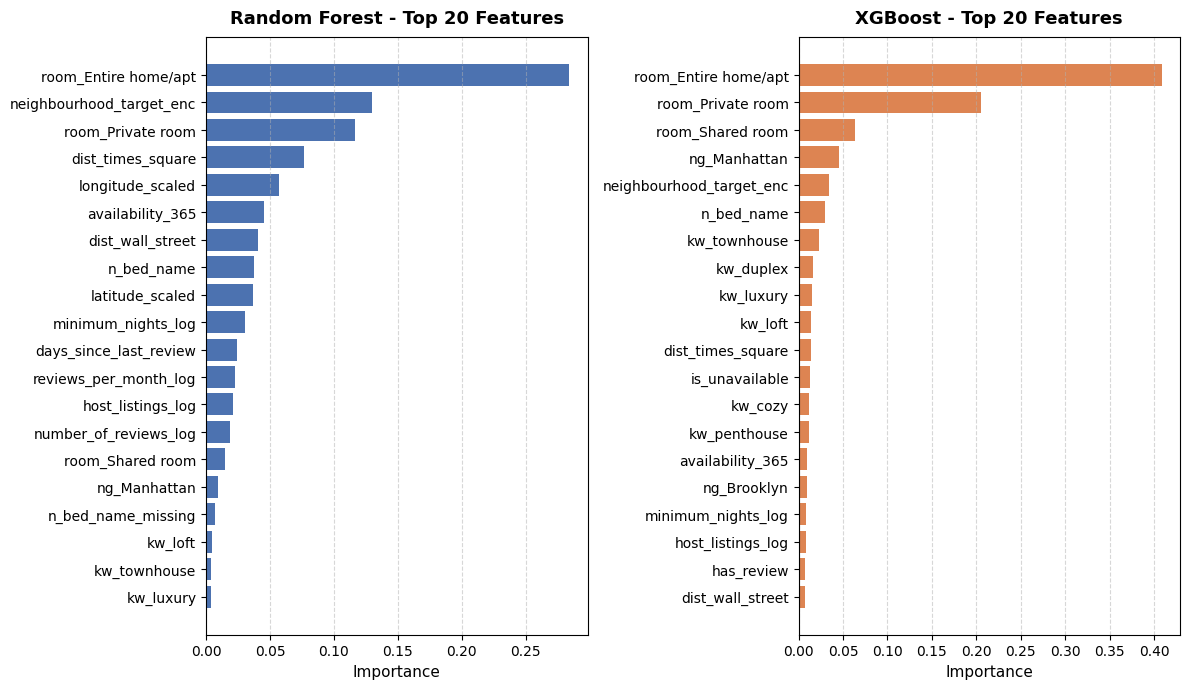

In [ ]:
# 1. Chỉ lấy Top 20 features cho từng mô hình và sắp xếp từ nhỏ đến lớn để vẽ barh
top20_rf = importance_df.sort_values('RF_Importance', ascending=False).head(20).sort_values('RF_Importance', ascending=True)
top20_xgb = importance_df.sort_values('XGB_Importance', ascending=False).head(20).sort_values('XGB_Importance', ascending=True)

# 2. Khởi tạo khung vẽ với tỷ lệ hợp lý cho Top 20 (rộng 12 inch, cao 7 inch)
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=False)

# --- Random Forest ---
axes[0].barh(top20_rf['Feature'], top20_rf['RF_Importance'], color='#4C72B0')
axes[0].set_title('Random Forest - Top 20 Features', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Importance', fontsize=11)
axes[0].tick_params(axis='both', labelsize=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# --- XGBoost ---
axes[1].barh(top20_xgb['Feature'], top20_xgb['XGB_Importance'], color='#DD8452')
axes[1].set_title('XGBoost - Top 20 Features', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Importance', fontsize=11)
axes[1].tick_params(axis='both', labelsize=10)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

# 3. Tối ưu khoảng cách và lưu file với bbox_inches='tight' để xén sạch lề thừa
plt.tight_layout()
# plt.savefig('RQ1_Feature_Importance2.png', dpi=300, bbox_inches='tight')
plt.show()

Calibration

In [ ]:
# ============================================================
# VIỆC 1+2 — CALIBRATION: trung vị với trung vị, + cột mean dùng smearing
# ============================================================
pred_log = split_models[seed0]['pred_log']
price_te_raw = split_models[seed0]['price_te_raw']
pred_naive = np.maximum(np.expm1(pred_log), 0)
pred_smeared = np.maximum(smearing_factor * np.exp(pred_log) - 1, 0)

cal_df = pd.DataFrame({'actual': price_te_raw, 'pred_naive': pred_naive, 'pred_smeared': pred_smeared})
cal_df['decile'] = pd.qcut(cal_df['pred_naive'], 10, labels=[f'D{i}' for i in range(1, 11)])

calibration = cal_df.groupby('decile').agg(
    n=('actual', 'size'),
    actual_median=('actual', 'median'),
    pred_median=('pred_naive', 'median'),
    actual_mean=('actual', 'mean'),
    pred_mean_smeared=('pred_smeared', 'mean'),
)
calibration['ratio_median'] = calibration['actual_median'] / calibration['pred_median']
calibration['ratio_mean_smeared'] = calibration['actual_mean'] / calibration['pred_mean_smeared']
print('\n=== CALIBRATION (median-vs-median, và mean-vs-mean đã smearing) ===')
print(calibration)


=== CALIBRATION (median-vs-median, và mean-vs-mean đã smearing) ===
          n  actual_median  pred_median  actual_mean  pred_mean_smeared  \
decile                                                                    
D1      734           47.0    49.957573    50.561308          52.246961   
D2      733           59.0    59.785271    81.882674          64.983199   
D3      733           69.0    70.131287    75.799454          76.505213   
D4      733           85.0    84.699142    94.090041          92.626715   
D5      734          100.0   104.490242   118.242507         113.603680   
D6      733          120.0   123.928802   148.261937         134.549531   
D7      733          140.0   146.547852   162.622101         158.835608   
D8      733          167.0   171.189117   185.729877         186.470562   
D9      733          200.0   203.995605   233.437926         223.831906   
D10     734          290.5   274.455688   401.076294         329.819531   

        ratio_median  ratio_me

/tmp/ipykernel_1097/1849192805.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  calibration = cal_df.groupby('decile').agg(


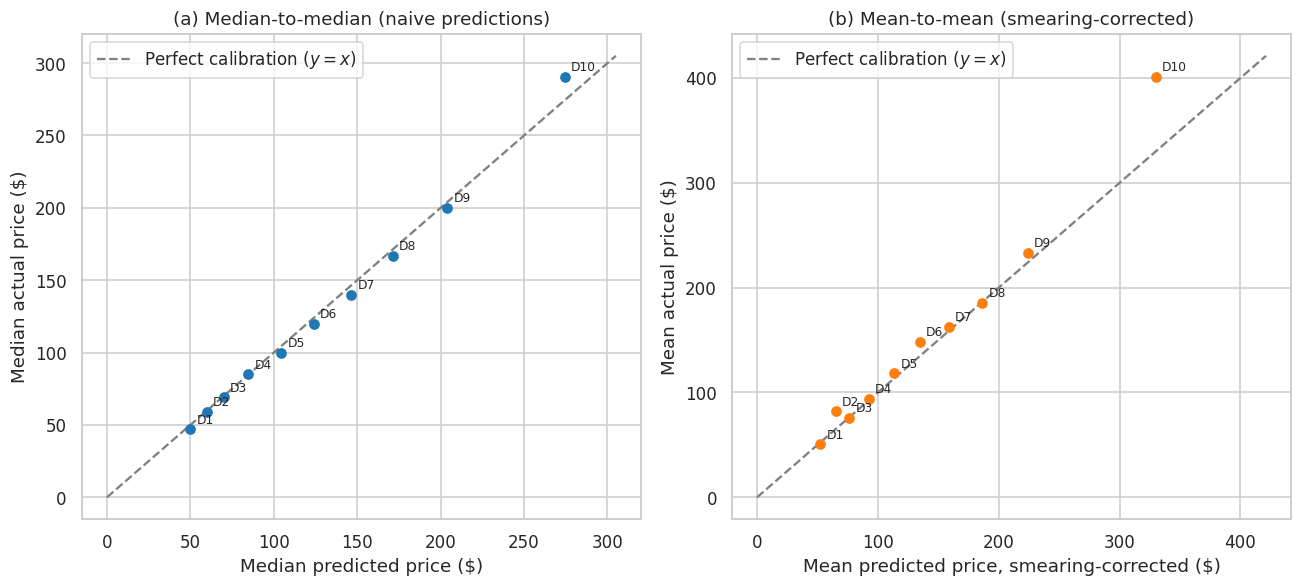

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

# --- Panel trái: median-to-median (naive) ---
ax = axes[0]
ax.scatter(calibration['pred_median'], calibration['actual_median'], color='tab:blue', zorder=3)
lims = [0, max(calibration['pred_median'].max(), calibration['actual_median'].max()) * 1.05]
ax.plot(lims, lims, '--', color='gray', label='Perfect calibration ($y=x$)')
for dec, row in calibration.iterrows():
    ax.annotate(dec, (row['pred_median'], row['actual_median']), fontsize=8,
                textcoords="offset points", xytext=(4, 4))
ax.set_xlabel('Median predicted price ($)')
ax.set_ylabel('Median actual price ($)')
ax.set_title('(a) Median-to-median (naive predictions)')
ax.legend()

# --- Panel phải: mean-to-mean (smearing-corrected) ---
ax = axes[1]
ax.scatter(calibration['pred_mean_smeared'], calibration['actual_mean'], color='tab:orange', zorder=3)
lims = [0, max(calibration['pred_mean_smeared'].max(), calibration['actual_mean'].max()) * 1.05]
ax.plot(lims, lims, '--', color='gray', label='Perfect calibration ($y=x$)')
for dec, row in calibration.iterrows():
    ax.annotate(dec, (row['pred_mean_smeared'], row['actual_mean']), fontsize=8,
                textcoords="offset points", xytext=(4, 4))
ax.set_xlabel('Mean predicted price, smearing-corrected ($)')
ax.set_ylabel('Mean actual price ($)')
ax.set_title('(b) Mean-to-mean (smearing-corrected)')
ax.legend()

plt.tight_layout()
plt.savefig('calibration.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CHECK: D2 có mean ratio = 1.26 do listing giá > $1,000?
# Đếm listing giá cao theo decile và so sánh mean price
# ============================================================

PRICE_THRESHOLD = 1000

# Đảm bảo actual price là numeric
check_df = cal_df.copy()
check_df["actual"] = pd.to_numeric(
    check_df["actual"], errors="coerce"
)

# Đánh dấu listing giá cao
check_df["price_over_1000"] = (
    check_df["actual"] > PRICE_THRESHOLD
)

# Thống kê theo decile
outlier_check = (
    check_df.groupby("decile", observed=True)
    .agg(
        n_listings=("actual", "count"),
        actual_mean=("actual", "mean"),
        actual_median=("actual", "median"),
        n_over_1000=("price_over_1000", "sum"),
        mean_price_over_1000=(
            "actual",
            lambda x: x[x > PRICE_THRESHOLD].mean()
        ),
        mean_price_at_most_1000=(
            "actual",
            lambda x: x[x <= PRICE_THRESHOLD].mean()
        ),
        total_price=("actual", "sum"),
        total_price_over_1000=(
            "actual",
            lambda x: x[x > PRICE_THRESHOLD].sum()
        ),
    )
)

# Tỷ lệ và mức đóng góp của các listing giá cao
outlier_check["pct_over_1000"] = (
    100 * outlier_check["n_over_1000"]
    / outlier_check["n_listings"]
)

outlier_check["pct_total_price_from_over_1000"] = (
    100 * outlier_check["total_price_over_1000"]
    / outlier_check["total_price"].replace(0, np.nan)
)

# Thêm mean prediction sau smearing để kiểm tra mean ratio
outlier_check["pred_mean_smeared"] = (
    check_df.groupby("decile", observed=True)["pred_smeared"]
    .mean()
)

outlier_check["mean_ratio_smeared"] = (
    outlier_check["actual_mean"]
    / outlier_check["pred_mean_smeared"].replace(0, np.nan)
)

# Hiển thị kết quả
cols_to_show = [
    "n_listings",
    "actual_mean",
    "actual_median",
    "n_over_1000",
    "pct_over_1000",
    "mean_price_over_1000",
    "mean_price_at_most_1000",
    "pct_total_price_from_over_1000",
    "pred_mean_smeared",
    "mean_ratio_smeared",
]

print("\n=== HIGH-PRICE LISTING CHECK BY DECILE ===")
print(outlier_check[cols_to_show].round(3).to_string())

print("\n=== D2 DETAIL ===")
if "D2" in outlier_check.index:
    print(outlier_check.loc["D2", cols_to_show].round(3))
else:
    print("Không tìm thấy D2; hãy kiểm tra số decile được tạo bởi pd.qcut().")

# Đối chiếu số listing > $1,000 trên toàn bộ test set
print("\n=== OVERALL CHECK ===")
print(
    "Tổng listing giá > $1,000:",
    int(check_df["price_over_1000"].sum())
)
print(
    "Tỷ lệ listing giá > $1,000 (%):",
    round(100 * check_df["price_over_1000"].mean(), 3)
)


=== HIGH-PRICE LISTING CHECK BY DECILE ===
        n_listings  actual_mean  actual_median  n_over_1000  pct_over_1000  mean_price_over_1000  mean_price_at_most_1000  pct_total_price_from_over_1000  pred_mean_smeared  mean_ratio_smeared
decile                                                                                                                                                                                          
D1             734       50.561           47.0            0          0.000                   NaN                   50.561                           0.000             52.247               0.968
D2             733       81.883           59.0            3          0.409              4566.667                   63.452                          22.826             64.983               1.260
D3             733       75.799           69.0            0          0.000                   NaN                   75.799                           0.000             76.505            